In [1]:
import torch
import cv2
import pandas as pd
import numpy as np

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Environment setup successful!")

PyTorch: 2.11.0+cpu
GPU available: False
OpenCV: 4.14.0
NumPy: 2.1.3
Environment setup successful!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"

folders = [
    "data/raw",
    "data/landmarks",
    "models",
    "reports",
    "src"
]

for folder in folders:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)

print("Project folder created:", BASE_DIR)

for folder in folders:
    print("Created:", folder)

Project folder created: /content/drive/MyDrive/T240_Sign_Language
Created: data/raw
Created: data/landmarks
Created: models
Created: reports
Created: src


In [ ]:
import os
from collections import Counter

RAW_DIR = "/content/drive/MyDrive/T240_Sign_Language/data/raw"

video_files = []
class_counts = Counter()

for root, dirs, files in os.walk(RAW_DIR):
    for file in files:
        if file.lower().endswith((".mov", ".mp4", ".avi")):
            video_files.append(os.path.join(root, file))
            class_name = os.path.basename(root)
            class_counts[class_name] += 1

print("Total videos extracted:", len(video_files))
print("Total sign classes:", len(class_counts))
print("\nVideos per class:")

for label, count in sorted(class_counts.items()):
    print(f"{label}: {count}")

Total videos extracted: 190
Total sign classes: 9

Videos per class:
48. Hello: 21
49. How are you: 21
50. Alright: 21
51. Good Morning: 21
52. Good afternoon: 22
53. Good evening: 21
54. Good night: 21
55. Thank you: 21
56. Pleased: 21


In [5]:
%pip install -q mediapipe
import mediapipe as mp

print("MediaPipe version:", mp.__version__)
print("MediaPipe installed successfully!")

MediaPipe version: 1.2.0
MediaPipe installed successfully!


In [ ]:
import os
import cv2

RAW_DIR = "/content/drive/MyDrive/T240_Sign_Language/data/raw"

video_path = None

for root, dirs, files in os.walk(RAW_DIR):
    for file in files:
        if file.lower().endswith(".mov"):
            video_path = os.path.join(root, file)
            break
    if video_path:
        break

cap = cv2.VideoCapture(video_path)

print("Video:", video_path)
print("Opened:", cap.isOpened())
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Total frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("Width:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
print("Height:", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))

cap.release()

Video: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0029.MOV
Opened: True
FPS: 25.0
Total frames: 63
Width: 1920
Height: 1080


In [ ]:
import mediapipe as mp

print("Has tasks API:", hasattr(mp, "tasks"))

if hasattr(mp, "tasks"):
    print("Has vision API:", hasattr(mp.tasks, "vision"))

Has tasks API: True
Has vision API: True


In [ ]:
import os
import urllib.request

MODEL_DIR = "/content/drive/MyDrive/T240_Sign_Language/models"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "hand_landmarker.task"
)

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
)

if not os.path.exists(MODEL_PATH):
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

print("Model downloaded:", os.path.exists(MODEL_PATH))
print("Model size (MB):", round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2))

Model downloaded: True
Model size (MB): 7.46


In [ ]:
import mediapipe as mp

BaseOptions = mp.tasks.BaseOptions
HandLandmarker = mp.tasks.vision.HandLandmarker
HandLandmarkerOptions = mp.tasks.vision.HandLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = HandLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=MODEL_PATH
    ),
    running_mode=VisionRunningMode.IMAGE,
    num_hands=2
)

detector = HandLandmarker.create_from_options(options)

print("Hand detector initialized successfully!")

Hand detector initialized successfully!


In [ ]:
import cv2
import mediapipe as mp

cap = cv2.VideoCapture(video_path)

success, frame = cap.read()
cap.release()

if not success:
    print("Could not read video frame.")
else:
    # OpenCV uses BGR; MediaPipe expects RGB.
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame_rgb
    )

    result = detector.detect(mp_image)

    print("Frame read successfully!")
    print("Hands detected:", len(result.hand_landmarks))

    for i, hand in enumerate(result.hand_landmarks):
        print(f"Hand {i + 1}: {len(hand)} landmarks")

Frame read successfully!
Hands detected: 2
Hand 1: 21 landmarks
Hand 2: 21 landmarks


In [ ]:
import cv2
import numpy as np
import mediapipe as mp

cap = cv2.VideoCapture(video_path)

sequence = []
frames_processed = 0
frames_with_hands = 0

while True:
    success, frame = cap.read()

    if not success:
        break

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame_rgb
    )

    result = detector.detect(mp_image)

    # Two hands × 21 landmarks × 3 coordinates
    features = np.zeros((2, 21, 3), dtype=np.float32)

    for hand_idx, hand_landmarks in enumerate(
        result.hand_landmarks[:2]
    ):
        for landmark_idx, landmark in enumerate(hand_landmarks):
            features[hand_idx, landmark_idx] = [
                landmark.x,
                landmark.y,
                landmark.z
            ]

    if result.hand_landmarks:
        frames_with_hands += 1

    sequence.append(features.flatten())
    frames_processed += 1

cap.release()

sequence = np.array(sequence, dtype=np.float32)

print("Frames processed:", frames_processed)
print("Frames with detected hands:", frames_with_hands)
print("Sequence shape:", sequence.shape)
print("Feature count per frame:", sequence.shape[1])

Frames processed: 63
Frames with detected hands: 63
Sequence shape: (63, 126)
Feature count per frame: 126


In [ ]:
import os
import numpy as np

LANDMARK_DIR = "/content/drive/MyDrive/T240_Sign_Language/data/landmarks"
os.makedirs(LANDMARK_DIR, exist_ok=True)

label = "Good evening"

save_path = os.path.join(
    LANDMARK_DIR,
    "test_good_evening.npy"
)

np.save(save_path, sequence)

print("Sequence saved:", save_path)
print("Shape:", np.load(save_path).shape)
print("Label:", label)

Sequence saved: /content/drive/MyDrive/T240_Sign_Language/data/landmarks/test_good_evening.npy
Shape: (63, 126)
Label: Good evening


In [ ]:
import os
import cv2

RAW_DIR = "/content/drive/MyDrive/T240_Sign_Language/data/raw"

video_path = None

for root, dirs, files in os.walk(RAW_DIR):
    for file in files:
        if file.lower().endswith(".mov"):
            video_path = os.path.join(root, file)
            break
    if video_path:
        break

cap = cv2.VideoCapture(video_path)

print("Video:", video_path)
print("Opened:", cap.isOpened())
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Total frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("Width:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
print("Height:", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))

cap.release()

Video: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0029.MOV
Opened: True
FPS: 25.0
Total frames: 63
Width: 1920
Height: 1080


In [ ]:
import os
from collections import Counter

RAW_DIR = "/content/drive/MyDrive/T240_Sign_Language/data/raw"

video_paths = []
label_counts = Counter()

for root, dirs, files in os.walk(RAW_DIR):
    for file in files:
        if file.lower().endswith((".mov", ".mp4", ".avi")):
            video_path = os.path.join(root, file)
            label = os.path.basename(root)

            video_paths.append((video_path, label))
            label_counts[label] += 1

video_paths.sort()

print("Total videos:", len(video_paths))
print("Total classes:", len(label_counts))
print("\nSample video and label:")

for path, label in video_paths[:5]:
    print(label, "->", os.path.basename(path))

print("\nVideos per class:")
for label, count in sorted(label_counts.items()):
    print(f"{label}: {count}")

Total videos: 190
Total classes: 9

Sample video and label:
48. Hello -> MVI_0029.MOV
48. Hello -> MVI_0030.MOV
48. Hello -> MVI_0031.MOV
48. Hello -> MVI_0032.MOV
48. Hello -> MVI_0037.MOV

Videos per class:
48. Hello: 21
49. How are you: 21
50. Alright: 21
51. Good Morning: 21
52. Good afternoon: 22
53. Good evening: 21
54. Good night: 21
55. Thank you: 21
56. Pleased: 21


In [ ]:

import os
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp
from tqdm.auto import tqdm
import shutil
from datetime import datetime

# 1. Project folders
BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
RAW_DIR = os.path.join(BASE_DIR, "data", "raw")
LANDMARK_DIR = os.path.join(BASE_DIR, "data", "landmarks")
REPORT_DIR = os.path.join(BASE_DIR, "reports")
MODEL_PATH = os.path.join(BASE_DIR, "models", "hand_landmarker.task")

os.makedirs(LANDMARK_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

# 2. Back up the existing manifest
manifest_path = os.path.join(REPORT_DIR, "landmark_manifest.csv")

if os.path.exists(manifest_path):
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    backup_path = os.path.join(
        REPORT_DIR, f"landmark_manifest_backup_{timestamp}.csv"
    )
    shutil.copy2(manifest_path, backup_path)
    print("Existing manifest backed up to:", backup_path)

# 3. Find videos
video_paths = []

for root, dirs, files in os.walk(RAW_DIR):
    for file in files:
        if file.lower().endswith((".mov", ".mp4", ".avi")):
            video_path = os.path.join(root, file)
            label = os.path.basename(root)
            video_paths.append((video_path, label))

video_paths.sort()
print("Total videos found:", len(video_paths))

if len(video_paths) == 0:
    raise RuntimeError("No videos found. Check RAW_DIR.")

# 4. Initialize MediaPipe with lower thresholds
options = mp.tasks.vision.HandLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(
        model_asset_path=MODEL_PATH
    ),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.3,
    min_hand_presence_confidence=0.3
)

detector = mp.tasks.vision.HandLandmarker.create_from_options(options)
print("Detector initialized with confidence thresholds = 0.3")

# 5. Re-extract every video
records = []

try:
    for video_path, label in tqdm(video_paths, desc="Re-extracting landmarks"):

        video_name = os.path.splitext(os.path.basename(video_path))[0]

        relative_path = os.path.relpath(video_path, RAW_DIR)
        folder_key = os.path.dirname(relative_path).replace(
            os.sep, "_"
        ).replace(" ", "_").replace(".", "")

        safe_label = label.replace(" ", "_").replace(".", "")
        output_name = f"{folder_key}_{safe_label}_{video_name}.npy"
        output_path = os.path.join(LANDMARK_DIR, output_name)

        cap = cv2.VideoCapture(video_path)
        sequence = []
        frames_with_hands = 0
        frame_count = 0
        error_message = ""

        try:
            while True:
                success, frame = cap.read()
                if not success:
                    break

                frame_count += 1

                frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                mp_image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=frame_rgb
                )

                result = detector.detect(mp_image)

                # Two hands x 21 landmarks x 3 coordinates.
                # Preserve the original 126-feature shape.
                features = np.zeros((2, 21, 3), dtype=np.float32)

                # Keep left/right slots consistent using handedness.
                handedness = result.handedness or []

                for hand_idx, hand in enumerate(result.hand_landmarks):
                    if hand_idx >= len(handedness):
                        continue

                    category = handedness[hand_idx][0].category_name.lower()

                    if category == "left":
                        slot = 0
                    elif category == "right":
                        slot = 1
                    else:
                        continue

                    for landmark_idx, point in enumerate(hand):
                        features[slot, landmark_idx] = [
                            point.x, point.y, point.z
                        ]

                if result.hand_landmarks:
                    frames_with_hands += 1

                sequence.append(features.reshape(126))

        except Exception as e:
            error_message = str(e)

        finally:
            cap.release()

        if error_message:
            print(f"\nERROR: {video_path}\n{error_message}")
            records.append({
                "video_path": video_path,
                "label": label,
                "sequence_path": "",
                "frames": frame_count,
                "frames_with_hands": frames_with_hands,
                "status": "error"
            })
            continue

        if len(sequence) == 0:
            records.append({
                "video_path": video_path,
                "label": label,
                "sequence_path": "",
                "frames": 0,
                "frames_with_hands": 0,
                "status": "failed_no_frames"
            })
            continue

        sequence_array = np.asarray(sequence, dtype=np.float32)

        # Save to a temporary file first, then replace the old sequence.
        temp_path = output_path + ".tmp.npy"
        np.save(temp_path, sequence_array)
        os.replace(temp_path, output_path)

        records.append({
            "video_path": video_path,
            "label": label,
            "sequence_path": output_path,
            "frames": int(sequence_array.shape[0]),
            "frames_with_hands": frames_with_hands,
            "status": "success"
        })

finally:
    detector.close()

# 6. Save the new manifest
manifest = pd.DataFrame(records)
manifest.to_csv(manifest_path, index=False)

# 7. Summary
print("\n--- RE-EXTRACTION SUMMARY ---")
print("Videos found:", len(video_paths))
print("Videos recorded:", len(manifest))
print("\nStatus counts:")
print(manifest["status"].value_counts().to_string())

print("\nSequences by label:")
print(
    manifest.groupby(["label", "status"])
    .size()
    .to_string()
)

successful = int((manifest["status"] == "success").sum())
print("\nSuccessful extractions:", successful)
print("Manifest saved to:", manifest_path)

print("\n--- DETECTION COVERAGE ---")
valid = manifest[manifest["frames"] > 0].copy()
valid["coverage_percent"] = (
    valid["frames_with_hands"] / valid["frames"] * 100
)
print("Total frames:", int(valid["frames"].sum()))
print("Frames with hands:", int(valid["frames_with_hands"].sum()))
print(
    "Overall detection coverage:",
    round(
        valid["frames_with_hands"].sum()
        / valid["frames"].sum() * 100, 2
    ),
    "%"
)


Existing manifest backed up to: /content/drive/MyDrive/T240_Sign_Language/reports/landmark_manifest_backup_20261028_061403.csv
Total videos found: 190
Detector initialized with confidence thresholds = 0.3


Re-extracting landmarks:   0%|          | 0/190 [00:00<?, ?it/s]


--- RE-EXTRACTION SUMMARY ---
Videos found: 190
Videos recorded: 190

Status counts:
status
success    190

Sequences by label:
label               status 
48. Hello           success    21
49. How are you     success    21
50. Alright         success    21
51. Good Morning    success    21
52. Good afternoon  success    22
53. Good evening    success    21
54. Good night      success    21
55. Thank you       success    21
56. Pleased         success    21

Successful extractions: 190
Manifest saved to: /content/drive/MyDrive/T240_Sign_Language/reports/landmark_manifest.csv

--- DETECTION COVERAGE ---
Total frames: 12884
Frames with hands: 11731
Overall detection coverage: 91.05 %


In [ ]:

import os
import numpy as np
import pandas as pd

MANIFEST_PATH = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "reports/landmark_manifest.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

valid_count = 0
invalid_files = []
frame_counts = []

for _, row in manifest.iterrows():
    path = row["sequence_path"]

    try:
        data = np.load(path)

        if (
            data.ndim == 2
            and data.shape[1] == 126
            and data.shape[0] > 0
            and np.isfinite(data).all()
        ):
            valid_count += 1
            frame_counts.append(data.shape[0])
        else:
            invalid_files.append(path)

    except Exception:
        invalid_files.append(path)

print("Total manifest entries:", len(manifest))
print("Valid sequences:", valid_count)
print("Invalid sequences:", len(invalid_files))

if frame_counts:
    print("Minimum frames:", min(frame_counts))
    print("Maximum frames:", max(frame_counts))
    print("Average frames:", round(np.mean(frame_counts), 2))

print("\nVideos per class:")
print(manifest["label"].value_counts().sort_index().to_string())

if invalid_files:
    print("\nFirst invalid paths:", invalid_files[:5])


Total manifest entries: 190
Valid sequences: 190
Invalid sequences: 0
Minimum frames: 41
Maximum frames: 100
Average frames: 67.81

Videos per class:
label
48. Hello             21
49. How are you       21
50. Alright           21
51. Good Morning      21
52. Good afternoon    22
53. Good evening      21
54. Good night        21
55. Thank you         21
56. Pleased           21


In [ ]:

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import joblib

# --------------------------------------------------
# 1. Set project paths
# --------------------------------------------------
BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
REPORT_DIR = os.path.join(BASE_DIR, "reports")
LANDMARK_DIR = os.path.join(BASE_DIR, "data", "landmarks")
MODEL_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

MANIFEST_PATH = os.path.join(REPORT_DIR, "landmark_manifest.csv")

# --------------------------------------------------
# 2. Load manifest
# --------------------------------------------------
manifest = pd.read_csv(MANIFEST_PATH)

print("Total manifest rows:", len(manifest))
print("\nStatus counts:")
print(manifest["status"].value_counts(dropna=False))

# Include sequences extracted in previous runs
manifest = manifest[
    manifest["status"].isin(["success", "already_saved"])
].copy()

# Keep only rows whose landmark files exist
manifest = manifest[
    manifest["sequence_path"].apply(
        lambda path: isinstance(path, str) and os.path.isfile(path)
    )
].copy()

print("\nValid landmark files:", len(manifest))

if len(manifest) == 0:
    raise ValueError(
        "No valid landmark files found. Check sequence_path "
        "in landmark_manifest.csv and the data/landmarks folder."
    )

# --------------------------------------------------
# 3. Encode labels
# --------------------------------------------------
label_encoder = LabelEncoder()
manifest["label_id"] = label_encoder.fit_transform(manifest["label"])

joblib.dump(
    label_encoder,
    os.path.join(MODEL_DIR, "label_encoder.pkl")
)


# --------------------------------------------------
# 4. Prepare sequences: 60 frames x 126 features
# --------------------------------------------------
TARGET_FRAMES = 60
FEATURES = 126

def resample_sequence(sequence, target_frames=60):
    """Resample a sequence to a fixed number of frames."""
    sequence = np.asarray(sequence, dtype=np.float32)

    if len(sequence) == target_frames:
        return sequence

    old_positions = np.linspace(0, 1, len(sequence))
    new_positions = np.linspace(0, 1, target_frames)

    resampled = np.empty(
        (target_frames, sequence.shape[1]),
        dtype=np.float32
    )

    for feature_idx in range(sequence.shape[1]):
        resampled[:, feature_idx] = np.interp(
            new_positions,
            old_positions,
            sequence[:, feature_idx]
        )

    return resampled

X = []
y = []
skipped = 0

for _, row in manifest.iterrows():
    try:
        sequence = np.load(
            row["sequence_path"]
        ).astype(np.float32)

        if (
            sequence.ndim != 2
            or sequence.shape[1] != FEATURES
            or len(sequence) == 0
            or not np.isfinite(sequence).all()
        ):
            skipped += 1
            continue

        sequence = resample_sequence(
            sequence,
            TARGET_FRAMES
        )

        X.append(sequence)
        y.append(row["label_id"])

    except Exception as e:
        skipped += 1
        print("Skipped:", row["sequence_path"], "|", str(e))

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.int64)

print("Prepared dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("Skipped sequences:", skipped)

# --------------------------------------------------
# 5. Stratified train/validation split
# --------------------------------------------------
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# --------------------------------------------------
# 6. Save dataset
# --------------------------------------------------
dataset_path = os.path.join(
    REPORT_DIR,
    "sign_language_dataset.npz"
)

np.savez_compressed(
    dataset_path,
    X_train=X_train,
    X_val=X_val,
    y_train=y_train,
    y_val=y_val
)

# --------------------------------------------------
# 7. Display results
# --------------------------------------------------
print("\nDataset preparation complete!")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("Number of classes:", len(label_encoder.classes_))
print("Saved dataset:", dataset_path)

print("\nLabel mapping:")
for i, label in enumerate(label_encoder.classes_):
    print(f"{i}: {label}")


Total manifest rows: 190

Status counts:
status
success    190
Name: count, dtype: int64

Valid landmark files: 190
Prepared dataset shape: (190, 60, 126)
Labels shape: (190,)
Skipped sequences: 0

Dataset preparation complete!
X_train: (152, 60, 126)
X_val: (38, 60, 126)
y_train: (152,)
y_val: (38,)
Number of classes: 9
Saved dataset: /content/drive/MyDrive/T240_Sign_Language/reports/sign_language_dataset.npz

Label mapping:
0: 48. Hello
1: 49. How are you
2: 50. Alright
3: 51. Good Morning
4: 52. Good afternoon
5: 53. Good evening
6: 54. Good night
7: 55. Thank you
8: 56. Pleased


In [ ]:
import torch
import torch.nn as nn

# Use CPU or GPU automatically
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class SignLanguageLSTM(nn.Module):
    def __init__(self, input_size=126, hidden_size=64, num_classes=9):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x shape: (batch, 60 frames, 126 features)
        _, (hidden, _) = self.lstm(x)

        # Use the final hidden state
        features = hidden[-1]
        features = self.dropout(features)

        return self.fc(features)


model = SignLanguageLSTM(num_classes=9).to(device)

print("Model created successfully!")
print("Device:", device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Model created successfully!
Device: cpu
Total parameters: 49737


In [ ]:
import os
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = os.path.join(
    BASE_DIR, "reports", "sign_language_dataset.npz"
)

# Load dataset
data = np.load(DATA_PATH)

X_train = torch.tensor(data["X_train"], dtype=torch.float32)
X_val = torch.tensor(data["X_val"], dtype=torch.float32)
y_train = torch.tensor(data["y_train"], dtype=torch.long)
y_val = torch.tensor(data["y_val"], dtype=torch.long)

# Create DataLoaders
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False
)

print("Training data:", X_train.shape, y_train.shape)
print("Validation data:", X_val.shape, y_val.shape)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Data preparation for PyTorch complete!")

Training data: torch.Size([152, 60, 126]) torch.Size([152])
Validation data: torch.Size([38, 60, 126]) torch.Size([38])
Training batches: 10
Validation batches: 3
Data preparation for PyTorch complete!


In [ ]:
import os
import copy
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 30
best_val_acc = 0.0
best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * inputs.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_total / train_total
    train_acc = train_correct / train_total

    # Validation
    model.eval()
    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * inputs.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    # Save the best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_model_state,
            os.path.join(MODEL_DIR, "best_sign_language_lstm.pth")
        )

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

# Restore the best model in memory
model.load_state_dict(best_model_state)

print("\nTraining complete!")
print(f"Best validation accuracy: {best_val_acc:.2%}")
print("Best model saved in:", os.path.join(
    MODEL_DIR, "best_sign_language_lstm.pth"
))

Epoch [01/30] Train Loss: 2.2230 | Train Acc: 0.1184 | Val Loss: 2.1979 | Val Acc: 0.0789
Epoch [02/30] Train Loss: 2.2001 | Train Acc: 0.1382 | Val Loss: 2.1931 | Val Acc: 0.1053
Epoch [03/30] Train Loss: 2.1985 | Train Acc: 0.0987 | Val Loss: 2.1912 | Val Acc: 0.1053
Epoch [04/30] Train Loss: 2.1999 | Train Acc: 0.1184 | Val Loss: 2.1896 | Val Acc: 0.0789
Epoch [05/30] Train Loss: 2.1995 | Train Acc: 0.0987 | Val Loss: 2.1918 | Val Acc: 0.0526
Epoch [06/30] Train Loss: 2.1933 | Train Acc: 0.1382 | Val Loss: 2.1896 | Val Acc: 0.0789
Epoch [07/30] Train Loss: 2.1834 | Train Acc: 0.1513 | Val Loss: 2.1824 | Val Acc: 0.1579
Epoch [08/30] Train Loss: 2.1797 | Train Acc: 0.1316 | Val Loss: 2.1678 | Val Acc: 0.1053
Epoch [09/30] Train Loss: 2.1570 | Train Acc: 0.1645 | Val Loss: 2.1427 | Val Acc: 0.1316
Epoch [10/30] Train Loss: 2.0964 | Train Acc: 0.1974 | Val Loss: 2.0813 | Val Acc: 0.1053
Epoch [11/30] Train Loss: 2.0188 | Train Acc: 0.1842 | Val Loss: 2.0256 | Val Acc: 0.1316
Epoch [12/

CLASSIFICATION REPORT

                    precision    recall  f1-score   support

         48. Hello       0.21      1.00      0.35         4
   49. How are you       0.60      0.75      0.67         4
       50. Alright       1.00      0.25      0.40         4
  51. Good Morning       0.00      0.00      0.00         4
52. Good afternoon       0.00      0.00      0.00         5
  53. Good evening       0.33      0.25      0.29         4
    54. Good night       0.00      0.00      0.00         4
     55. Thank you       0.50      0.60      0.55         5
       56. Pleased       0.00      0.00      0.00         4

          accuracy                           0.32        38
         macro avg       0.29      0.32      0.25        38
      weighted avg       0.29      0.32      0.25        38



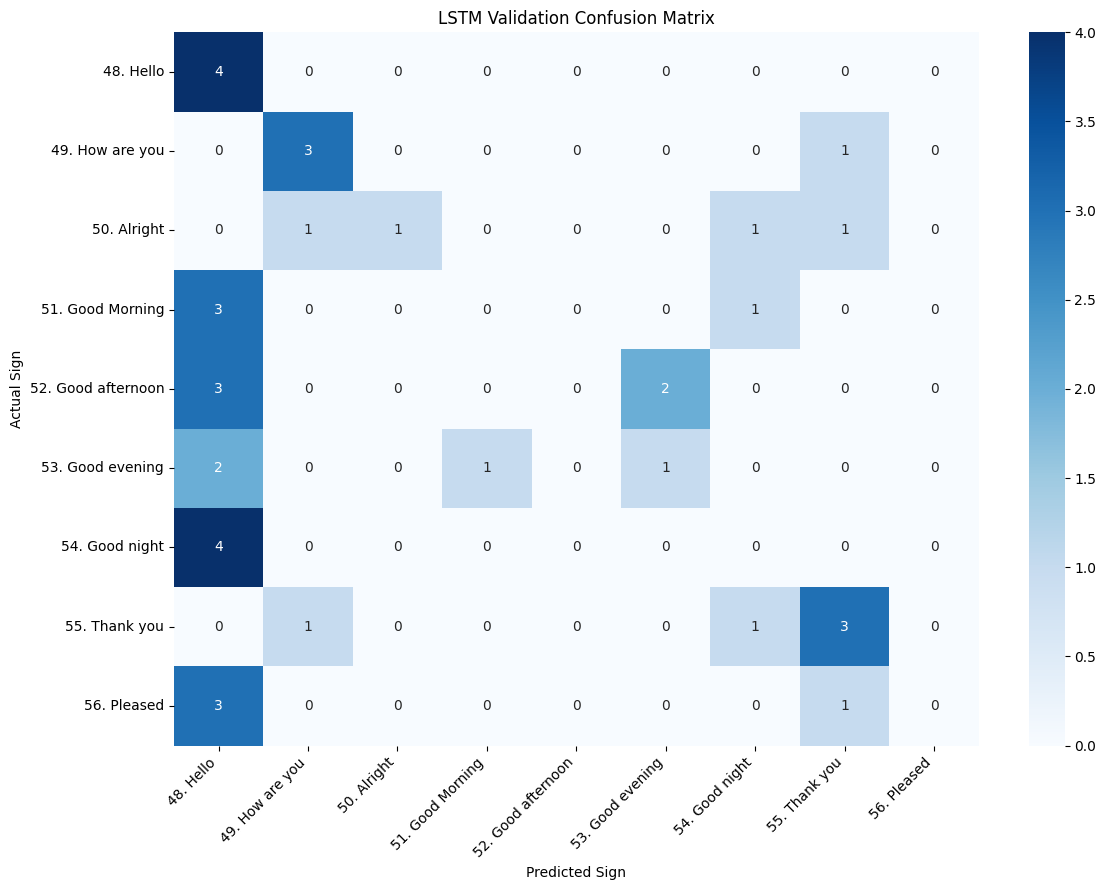

In [ ]:
import numpy as np
import torch
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"

# Load the saved label names
label_encoder = joblib.load(
    os.path.join(BASE_DIR, "models", "label_encoder.pkl")
)

# Get predictions
model.eval()
all_predictions = []
all_labels = []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Classification report
class_names = label_encoder.classes_

print("CLASSIFICATION REPORT\n")
print(classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Sign")
plt.ylabel("Actual Sign")
plt.title("LSTM Validation Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = os.path.join(
    BASE_DIR, "reports", "sign_language_dataset.npz"
)

data = np.load(DATA_PATH)

X_train = data["X_train"].copy()
X_val = data["X_val"].copy()

def normalize_landmarks(X):
    X = X.copy()

    # Each frame: two hands, 21 landmarks per hand, xyz coordinates
    X = X.reshape(X.shape[0], X.shape[1], 2, 21, 3)

    for hand_idx in range(2):
        hand = X[:, :, hand_idx, :, :]

        # A zero wrist indicates a likely missing hand
        detected = np.any(hand[:, :, 0, :] != 0, axis=-1)

        # Center landmarks relative to the wrist
        wrist = hand[:, :, 0:1, :].copy()
        hand -= wrist

        # Scale using the largest absolute coordinate per frame
        scale = np.max(np.abs(hand), axis=(2, 3), keepdims=True)
        scale[scale < 1e-6] = 1.0
        hand /= scale

        # Preserve missing-hand frames as zeros
        hand[~detected] = 0

    return X.reshape(X.shape[0], X.shape[1], 126).astype(np.float32)

X_train_norm = normalize_landmarks(X_train)
X_val_norm = normalize_landmarks(X_val)

print("Normalized training data:", X_train_norm.shape)
print("Normalized validation data:", X_val_norm.shape)
print("All values finite:",
      np.isfinite(X_train_norm).all() and np.isfinite(X_val_norm).all())

Normalized training data: (152, 60, 126)
Normalized validation data: (38, 60, 126)
All values finite: True


In [ ]:
import os
import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_DIR = os.path.join(BASE_DIR, "models")

# Create datasets using normalized features
train_dataset_norm = TensorDataset(
    torch.tensor(X_train_norm, dtype=torch.float32),
    y_train
)
val_dataset_norm = TensorDataset(
    torch.tensor(X_val_norm, dtype=torch.float32),
    y_val
)

train_loader_norm = DataLoader(
    train_dataset_norm, batch_size=16, shuffle=True
)
val_loader_norm = DataLoader(
    val_dataset_norm, batch_size=16, shuffle=False
)

# Fresh model and optimizer
model = SignLanguageLSTM(num_classes=9).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 40
best_val_acc = 0.0
best_model_state = copy.deepcopy(model.state_dict())
best_path = os.path.join(MODEL_DIR, "best_sign_language_lstm_norm.pth")

for epoch in range(EPOCHS):
    model.train()
    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader_norm:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_total / train_total
    train_acc = train_correct / train_total

    model.eval()
    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader_norm:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = copy.deepcopy(model.state_dict())
        torch.save(best_model_state, best_path)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

model.load_state_dict(best_model_state)

print("\nRetraining complete!")
print(f"Best normalized validation accuracy: {best_val_acc:.2%}")
print("Saved model:", best_path)

Epoch [01/40] Train Loss: 2.2139 | Train Acc: 0.1053 | Val Loss: 2.2032 | Val Acc: 0.1316
Epoch [02/40] Train Loss: 2.2008 | Train Acc: 0.1118 | Val Loss: 2.2029 | Val Acc: 0.0789
Epoch [03/40] Train Loss: 2.1920 | Train Acc: 0.1250 | Val Loss: 2.2030 | Val Acc: 0.0789
Epoch [04/40] Train Loss: 2.1721 | Train Acc: 0.2105 | Val Loss: 2.2037 | Val Acc: 0.1053
Epoch [05/40] Train Loss: 2.1764 | Train Acc: 0.1776 | Val Loss: 2.2020 | Val Acc: 0.0789
Epoch [06/40] Train Loss: 2.1719 | Train Acc: 0.1447 | Val Loss: 2.1998 | Val Acc: 0.1316
Epoch [07/40] Train Loss: 2.1424 | Train Acc: 0.1447 | Val Loss: 2.1737 | Val Acc: 0.1053
Epoch [08/40] Train Loss: 2.0283 | Train Acc: 0.2763 | Val Loss: 2.0467 | Val Acc: 0.1316
Epoch [09/40] Train Loss: 1.8924 | Train Acc: 0.2105 | Val Loss: 1.9183 | Val Acc: 0.2368
Epoch [10/40] Train Loss: 1.7520 | Train Acc: 0.3355 | Val Loss: 1.8545 | Val Acc: 0.1579
Epoch [11/40] Train Loss: 1.6840 | Train Acc: 0.3355 | Val Loss: 1.8606 | Val Acc: 0.2105
Epoch [12/

Best checkpoint accuracy: 57.89%

CLASSIFICATION REPORT

                    precision    recall  f1-score   support

         48. Hello       0.80      1.00      0.89         4
   49. How are you       1.00      1.00      1.00         4
       50. Alright       0.75      0.75      0.75         4
  51. Good Morning       0.10      0.25      0.14         4
52. Good afternoon       0.50      0.20      0.29         5
  53. Good evening       0.40      0.50      0.44         4
    54. Good night       0.00      0.00      0.00         4
     55. Thank you       0.80      0.80      0.80         5
       56. Pleased       1.00      0.75      0.86         4

          accuracy                           0.58        38
         macro avg       0.59      0.58      0.57        38
      weighted avg       0.60      0.58      0.57        38



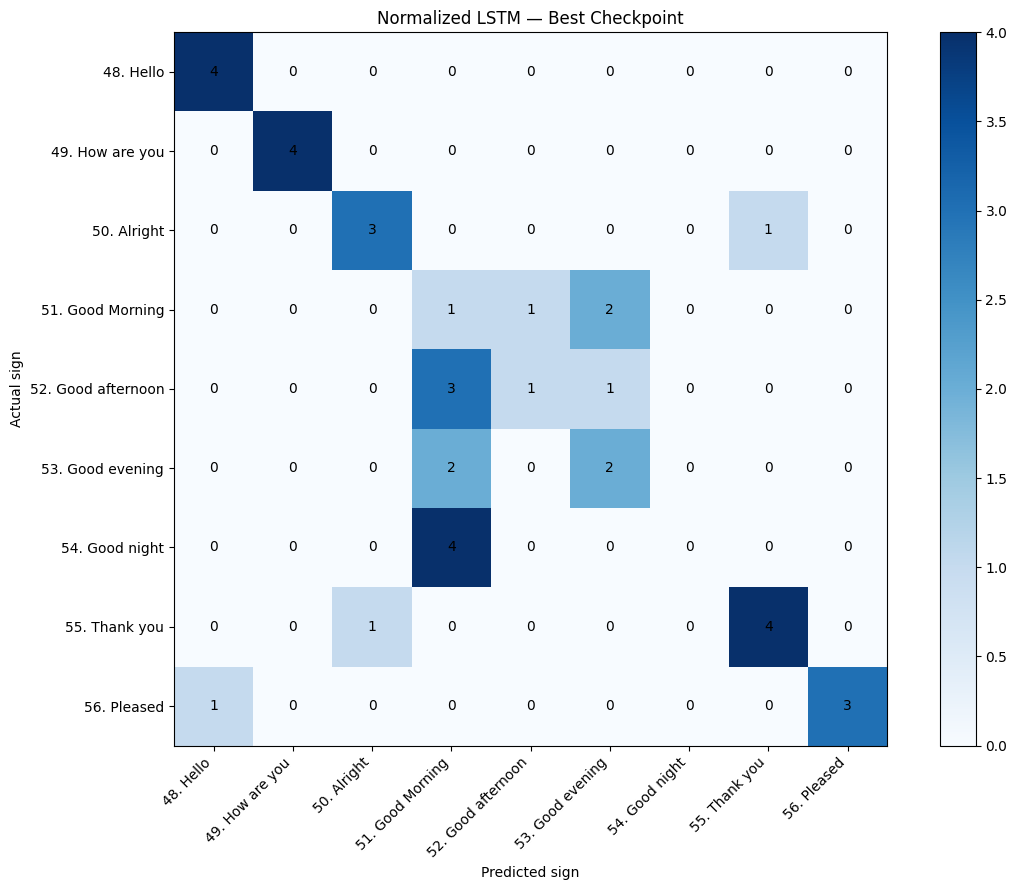

In [ ]:
import os
import numpy as np
import torch
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_PATH = os.path.join(
    BASE_DIR, "models", "best_sign_language_lstm_norm.pth"
)

# Load the best checkpoint
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for inputs, labels in val_loader_norm:
        outputs = model(inputs.to(device))
        all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

label_encoder = joblib.load(
    os.path.join(BASE_DIR, "models", "label_encoder.pkl")
)
class_names = label_encoder.classes_

print("Best checkpoint accuracy:",
      f"{accuracy_score(all_labels, all_predictions):.2%}")

print("\nCLASSIFICATION REPORT\n")
print(classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(12, 9))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.colorbar()
plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.xlabel("Predicted sign")
plt.ylabel("Actual sign")
plt.title("Normalized LSTM — Best Checkpoint")
plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import numpy as np
import torch
import joblib

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"

# Load label encoder and best model
label_encoder = joblib.load(
    os.path.join(BASE_DIR, "models", "label_encoder.pkl")
)

model.load_state_dict(torch.load(
    os.path.join(BASE_DIR, "models", "best_sign_language_lstm_norm.pth"),
    map_location=device,
    weights_only=True
))
model.eval()

# Choose one video to test
test_video = video_paths[0][0]
actual_label = video_paths[0][1]

print("Video:", os.path.basename(test_video))
print("Actual sign:", actual_label)

# Extract landmarks using your existing MediaPipe detector
cap = cv2.VideoCapture(test_video)
frames = []

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame_rgb
    )
    result = detector.detect(mp_image)

    landmarks = np.zeros((2, 21, 3), dtype=np.float32)

    if result.hand_landmarks:
        for hand_idx, hand in enumerate(result.hand_landmarks[:2]):
            for point_idx, point in enumerate(hand):
                landmarks[hand_idx, point_idx] = [
                    point.x, point.y, point.z
                ]

    frames.append(landmarks.reshape(126))

cap.release()

sequence = np.asarray(frames, dtype=np.float32)

if len(sequence) == 0:
    print("No frames found in video.")
else:
    # Sample/pad to 60 frames
    indices = np.linspace(
        0, len(sequence) - 1, min(len(sequence), 60)
    ).astype(int)
    sequence = sequence[indices]

    if len(sequence) < 60:
        padding = np.repeat(
            sequence[-1:], 60 - len(sequence), axis=0
        )
        sequence = np.concatenate([sequence, padding], axis=0)

    # Apply the same normalization used during training
    sequence = normalize_landmarks(sequence[np.newaxis])[0]

    inputs = torch.tensor(
        sequence[np.newaxis], dtype=torch.float32
    ).to(device)

    with torch.no_grad():
        probabilities = torch.softmax(model(inputs), dim=1)[0]
        predicted_id = probabilities.argmax().item()

    print("Predicted sign:", label_encoder.inverse_transform([predicted_id])[0])
    print(f"Model confidence: {probabilities[predicted_id].item():.2%}")

Video: MVI_0029.MOV
Actual sign: 48. Hello
Predicted sign: 49. How are you
Model confidence: 32.11%


In [ ]:
import numpy as np
import torch
import joblib
import os

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"

# Find a validation video that was not in the training split
data = np.load(
    os.path.join(BASE_DIR, "reports", "sign_language_dataset.npz")
)

# Get the saved validation arrays and label names
X_val_raw = data["X_val"]
y_val_np = data["y_val"]

label_encoder = joblib.load(
    os.path.join(BASE_DIR, "models", "label_encoder.pkl")
)

# Evaluate all validation examples
model.eval()
with torch.no_grad():
    inputs = torch.tensor(X_val_norm, dtype=torch.float32).to(device)
    probs = torch.softmax(model(inputs), dim=2) if False else torch.softmax(model(inputs), dim=1)
    preds = probs.argmax(dim=1).cpu().numpy()
    confidence = probs.max(dim=1).values.cpu().numpy()

print("Validation predictions:")
for i in range(len(y_val_np)):
    actual = label_encoder.inverse_transform([int(y_val_np[i])])[0]
    predicted = label_encoder.inverse_transform([int(preds[i])])[0]
    print(
        f"{i+1:02d}. Actual: {actual} | "
        f"Predicted: {predicted} | Confidence: {confidence[i]:.2%}"
    )

print("\nValidation accuracy:", f"{(preds == y_val_np).mean():.2%}")

Validation predictions:
01. Actual: 56. Pleased | Predicted: 56. Pleased | Confidence: 57.62%
02. Actual: 50. Alright | Predicted: 55. Thank you | Confidence: 81.47%
03. Actual: 49. How are you | Predicted: 49. How are you | Confidence: 98.08%
04. Actual: 48. Hello | Predicted: 48. Hello | Confidence: 67.97%
05. Actual: 56. Pleased | Predicted: 56. Pleased | Confidence: 77.72%
06. Actual: 51. Good Morning | Predicted: 52. Good afternoon | Confidence: 27.12%
07. Actual: 54. Good night | Predicted: 51. Good Morning | Confidence: 32.29%
08. Actual: 54. Good night | Predicted: 51. Good Morning | Confidence: 34.06%
09. Actual: 51. Good Morning | Predicted: 51. Good Morning | Confidence: 32.15%
10. Actual: 52. Good afternoon | Predicted: 53. Good evening | Confidence: 30.88%
11. Actual: 49. How are you | Predicted: 49. How are you | Confidence: 98.10%
12. Actual: 49. How are you | Predicted: 49. How are you | Confidence: 96.45%
13. Actual: 50. Alright | Predicted: 50. Alright | Confidence: 8

In [ ]:
import os
import numpy as np

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
REPORT_DIR = os.path.join(BASE_DIR, "reports")

# Save normalized training and validation features
output_path = os.path.join(
    REPORT_DIR, "sign_language_dataset_normalized.npz"
)

np.savez_compressed(
    output_path,
    X_train=X_train_norm,
    X_val=X_val_norm,
    y_train=y_train.numpy(),
    y_val=y_val.numpy()
)

print("Normalized dataset saved successfully!")
print("Path:", output_path)
print("Training shape:", X_train_norm.shape)
print("Validation shape:", X_val_norm.shape)

Normalized dataset saved successfully!
Path: /content/drive/MyDrive/T240_Sign_Language/reports/sign_language_dataset_normalized.npz
Training shape: (152, 60, 126)
Validation shape: (38, 60, 126)


In [ ]:
import os
import copy
import torch
import torch.nn as nn

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

# Start with a fresh model
model = SignLanguageLSTM(num_classes=9).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4
)

EPOCHS = 60
PATIENCE = 10
best_val_loss = float("inf")
best_val_acc = 0.0
best_model_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

best_path = os.path.join(
    MODEL_DIR, "best_sign_language_lstm_improved.pth"
)

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader_norm:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader_norm:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    scheduler.step(val_loss)

    # Save checkpoint when validation loss improves
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_acc = val_acc
        best_model_state = copy.deepcopy(model.state_dict())
        torch.save(best_model_state, best_path)
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%} | "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch+1}.")
        break

model.load_state_dict(best_model_state)

print("\nTraining complete!")
print(f"Validation accuracy at best-loss checkpoint: {best_val_acc:.2%}")
print(f"Best validation loss: {best_val_loss:.4f}")
print("Saved model:", best_path)

Epoch [01/60] Train Loss: 2.2252 | Train Acc: 10.53% | Val Loss: 2.2018 | Val Acc: 15.79% | LR: 0.001000
Epoch [02/60] Train Loss: 2.1948 | Train Acc: 15.13% | Val Loss: 2.1976 | Val Acc: 13.16% | LR: 0.001000
Epoch [03/60] Train Loss: 2.1864 | Train Acc: 12.50% | Val Loss: 2.1977 | Val Acc: 7.89% | LR: 0.001000
Epoch [04/60] Train Loss: 2.1776 | Train Acc: 14.47% | Val Loss: 2.1955 | Val Acc: 10.53% | LR: 0.001000
Epoch [05/60] Train Loss: 2.1528 | Train Acc: 19.08% | Val Loss: 2.1795 | Val Acc: 15.79% | LR: 0.001000
Epoch [06/60] Train Loss: 2.1115 | Train Acc: 20.39% | Val Loss: 2.1254 | Val Acc: 15.79% | LR: 0.001000
Epoch [07/60] Train Loss: 2.0265 | Train Acc: 25.66% | Val Loss: 2.0291 | Val Acc: 18.42% | LR: 0.001000
Epoch [08/60] Train Loss: 1.9505 | Train Acc: 20.39% | Val Loss: 1.9270 | Val Acc: 18.42% | LR: 0.001000
Epoch [09/60] Train Loss: 1.8625 | Train Acc: 23.03% | Val Loss: 1.8826 | Val Acc: 18.42% | LR: 0.001000
Epoch [10/60] Train Loss: 1.8127 | Train Acc: 21.71% | V

In [ ]:
import os
import torch

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"

best_model_path = os.path.join(
    BASE_DIR, "models", "best_sign_language_lstm_norm.pth"
)

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

print("Best model restored successfully!")
print("Model:", best_model_path)
print("Best recorded validation accuracy: 71.05%")

Best model restored successfully!
Model: /content/drive/MyDrive/T240_Sign_Language/models/best_sign_language_lstm_norm.pth
Best recorded validation accuracy: 71.05%


In [ ]:
import os
import glob

video_folder = "/content/drive/MyDrive/T240_Sign_Language/data/raw"

videos = glob.glob(video_folder + "/**/*.MOV", recursive=True)

print("Total videos found:", len(videos))

for i, video in enumerate(videos[:10]):
    print(f"{i}: {video}")

Total videos found: 190
0: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0029.MOV
1: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0031.MOV
2: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0030.MOV
3: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0032.MOV
4: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0038.MOV
5: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0037.MOV
6: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0089.MOV
7: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0090.MOV
8: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0039.MOV
9: /content/drive/MyDrive/T240_Sign_Language/data/raw/Gree

In [ ]:

import cv2
import mediapipe as mp
import numpy as np

cap = cv2.VideoCapture(test_video)
frames = []

while cap.isOpened():
    success, frame = cap.read()
    if not success:
        break

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame_rgb
    )

    result = detector.detect(mp_image)

    landmarks = np.zeros((2, 21, 3), dtype=np.float32)

    if result.hand_landmarks:
        for hand_idx, hand in enumerate(result.hand_landmarks[:2]):
            for point_idx, point in enumerate(hand):
                landmarks[hand_idx, point_idx] = [
                    point.x, point.y, point.z
                ]

    frames.append(landmarks.reshape(126))

cap.release()

sequence = np.array(frames, dtype=np.float32)

print("Video processed successfully!")
print("Total frames:", len(sequence))
print("Feature shape:", sequence.shape)


Video processed successfully!
Total frames: 63
Feature shape: (63, 126)


In [ ]:

# Select 60 frames from the video
indices = np.linspace(0, len(sequence) - 1, 60).astype(int)
sequence_60 = sequence[indices]

# Normalize using the same function used during training
sequence_norm = normalize_landmarks(sequence_60[np.newaxis])[0]

# Convert to a PyTorch tensor
import torch

inputs = torch.tensor(
    sequence_norm,
    dtype=torch.float32
).unsqueeze(0).to(device)

# Predict the sign
model.eval()

with torch.no_grad():
    outputs = model(inputs)
    probabilities = torch.softmax(outputs, dim=1)
    confidence, predicted_idx = probabilities.max(dim=1)

predicted_class = label_encoder.inverse_transform(
    [predicted_idx.item()]
)[0]

print("Actual sign: 48. Hello")
print("Predicted sign:", predicted_class)
print(f"Confidence: {confidence.item() * 100:.2f}%")


Actual sign: 48. Hello
Predicted sign: 49. How are you
Confidence: 32.11%


In [ ]:

data = np.load(
    "/content/drive/MyDrive/T240_Sign_Language/reports/sign_language_dataset_normalized.npz"
)

X_train_saved = data["X_train"]
X_val_saved = data["X_val"]

print("Training data shape:", X_train_saved.shape)
print("Validation data shape:", X_val_saved.shape)
print("Test video shape:", sequence_norm.shape)

print("\nTraining data range:",
      float(X_train_saved.min()), "to", float(X_train_saved.max()))
print("Test video range:",
      float(sequence_norm.min()), "to", float(sequence_norm.max()))

print("\nTraining sample mean:", float(X_train_saved.mean()))
print("Test video mean:", float(sequence_norm.mean()))


Training data shape: (152, 60, 126)
Validation data shape: (38, 60, 126)
Test video shape: (60, 126)

Training data range: -1.0 to 1.0
Test video range: 0.0 to 0.0

Training sample mean: 0.06457235664129257
Test video mean: 0.0


In [ ]:

import pandas as pd

manifest_path = "/content/drive/MyDrive/T240_Sign_Language/reports/landmark_manifest.csv"
manifest = pd.read_csv(manifest_path)

print("Manifest columns:")
print(manifest.columns.tolist())

print("\nFirst 5 rows:")
display(manifest.head())


Manifest columns:
['video_path', 'label', 'sequence_path', 'frames', 'frames_with_hands', 'status']

First 5 rows:


,video_path,label,sequence_path,frames,frames_with_hands,status
0,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,63,63,success
1,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,74,74,success
2,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,65,65,success
3,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,61,61,success
4,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,49,47,success


In [ ]:

# Find validation samples labeled Hello
hello_label = label_encoder.transform(["48. Hello"])[0]

val_hello_indices = np.where(y_val == hello_label)[0]

print("Validation Hello samples:", len(val_hello_indices))

# Match validation samples against the original manifest using video paths
val_paths = set(
    manifest.loc[
        manifest["label"] == "48. Hello", "video_path"
    ].tolist()
)

print("Hello video paths in manifest:", len(val_paths))
print("\nExample Hello video paths:")
for path in list(val_paths)[:5]:
    print(path)


Validation Hello samples: 4
Hello video paths in manifest: 21

Example Hello video paths:
/content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0091.MOV
/content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0039.MOV
/content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0029.MOV
/content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_9916.MOV
/content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0037.MOV


In [ ]:

print("Available split-related variables:")

for name in [
    "train_idx", "val_idx",
    "train_indices", "val_indices",
    "X_train", "X_val", "y_train", "y_val",
    "X_train_norm", "X_val_norm"
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: shape={value.shape}" if hasattr(value, "shape")
              else f"{name}: available")


Available split-related variables:
X_train: shape=(152, 60, 126)
X_val: shape=(38, 60, 126)
y_train: shape=torch.Size([152])
y_val: shape=torch.Size([38])
X_train_norm: shape=(152, 60, 126)
X_val_norm: shape=(38, 60, 126)


In [ ]:

model.eval()

with torch.no_grad():
    val_inputs = torch.tensor(
        X_val_norm, dtype=torch.float32
    ).to(device)

    val_outputs = model(val_inputs)
    val_probs = torch.softmax(val_outputs, dim=1)
    val_preds = val_outputs.argmax(dim=1).cpu().numpy()

val_labels = y_val.cpu().numpy() if torch.is_tensor(y_val) else y_val

correct = (val_preds == val_labels).sum()

print(f"Validation accuracy: {correct}/{len(val_labels)} "
      f"= {correct / len(val_labels) * 100:.2f}%")

# Show predictions for the four Hello validation samples
hello_id = label_encoder.transform(["48. Hello"])[0]
hello_indices = np.where(val_labels == hello_id)[0]

print("\nHello validation samples:")
for i in hello_indices:
    pred_name = label_encoder.inverse_transform([int(val_preds[i])])[0]
    confidence = val_probs[i, val_preds[i]].item() * 100
    print(f"Sample {i}: predicted={pred_name}, confidence={confidence:.2f}%")


Validation accuracy: 22/38 = 57.89%

Hello validation samples:
Sample 3: predicted=48. Hello, confidence=67.97%
Sample 19: predicted=48. Hello, confidence=53.58%
Sample 30: predicted=48. Hello, confidence=58.85%
Sample 31: predicted=48. Hello, confidence=62.98%


In [ ]:

checkpoint_path = "/content/drive/MyDrive/T240_Sign_Language/models/best_sign_language_lstm_norm.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model.eval()

with torch.no_grad():
    val_inputs = torch.tensor(
        X_val_norm, dtype=torch.float32
    ).to(device)
    val_outputs = model(val_inputs)
    val_preds = val_outputs.argmax(dim=1).cpu().numpy()

val_labels = y_val.cpu().numpy() if torch.is_tensor(y_val) else y_val

correct = (val_preds == val_labels).sum()
print(f"Reloaded checkpoint accuracy: {correct}/{len(val_labels)} "
      f"= {correct / len(val_labels) * 100:.2f}%")


Reloaded checkpoint accuracy: 22/38 = 57.89%


In [ ]:

saved = np.load(
    "/content/drive/MyDrive/T240_Sign_Language/reports/sign_language_dataset_normalized.npz"
)

saved_X_val = saved["X_val"]
saved_y_val = saved["y_val"]

current_y_val = y_val.cpu().numpy() if torch.is_tensor(y_val) else y_val

print("X_val_norm matches saved X_val:",
      np.allclose(X_val_norm, saved_X_val))

print("y_val matches saved y_val:",
      np.array_equal(current_y_val, saved_y_val))

print("Saved validation labels:", saved_y_val.shape)
print("Current validation labels:", current_y_val.shape)


X_val_norm matches saved X_val: True
y_val matches saved y_val: True
Saved validation labels: (38,)
Current validation labels: (38,)


In [ ]:

checkpoint = torch.load(
    "/content/drive/MyDrive/T240_Sign_Language/models/best_sign_language_lstm_norm.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))
    for key, value in checkpoint.items():
        if not isinstance(value, dict):
            print(f"{key}: {value}")


Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['lstm.weight_ih_l0', 'lstm.weight_hh_l0', 'lstm.bias_ih_l0', 'lstm.bias_hh_l0', 'fc.weight', 'fc.bias']
lstm.weight_ih_l0: tensor([[-0.0257,  0.0800, -0.0017,  ...,  0.0989,  0.0545, -0.0880],
        [-0.0787,  0.0901,  0.1062,  ...,  0.1205,  0.1318,  0.0142],
        [-0.0330, -0.0388,  0.0862,  ...,  0.0615, -0.0355,  0.0466],
        ...,
        [ 0.1110,  0.1022,  0.0075,  ...,  0.0230,  0.1029,  0.0232],
        [ 0.0414,  0.0007, -0.0539,  ..., -0.0405,  0.0536,  0.0035],
        [ 0.0992,  0.0806,  0.0517,  ...,  0.0822,  0.1101,  0.0704]])
lstm.weight_hh_l0: tensor([[ 0.0269, -0.0932,  0.0171,  ..., -0.0862, -0.0731, -0.0592],
        [ 0.0900, -0.0033, -0.0367,  ...,  0.0234,  0.0424,  0.0774],
        [-0.0465, -0.1201,  0.1044,  ..., -0.0734,  0.0225,  0.1010],
        ...,
        [-0.0164,  0.1960, -0.0886,  ...,  0.0512, -0.0479, -0.0764],
        [-0.0447, -0.0063,  0.0205,  ..., -0.0532,  0.0193, -0

In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    X = torch.tensor(X_val_norm, dtype=torch.float32).to(device)
    y = y_val.to(device)

    outputs = model(X)
    predictions = torch.argmax(outputs, dim=1)

    correct = (predictions == y).sum().item()
    total = y.size(0)

print(f"Actual Validation Accuracy: {100 * correct / total:.2f}%")
print(f"Correct predictions: {correct}/{total}")

Actual Validation Accuracy: 57.89%
Correct predictions: 22/38


In [ ]:
import os

checkpoint_path = "/content/drive/MyDrive/T240_Sign_Language/models/best_sign_language_lstm_norm.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("Checkpoint size:", round(os.path.getsize(checkpoint_path) / 1024, 2), "KB")

Checkpoint exists: True
Checkpoint size: 197.52 KB


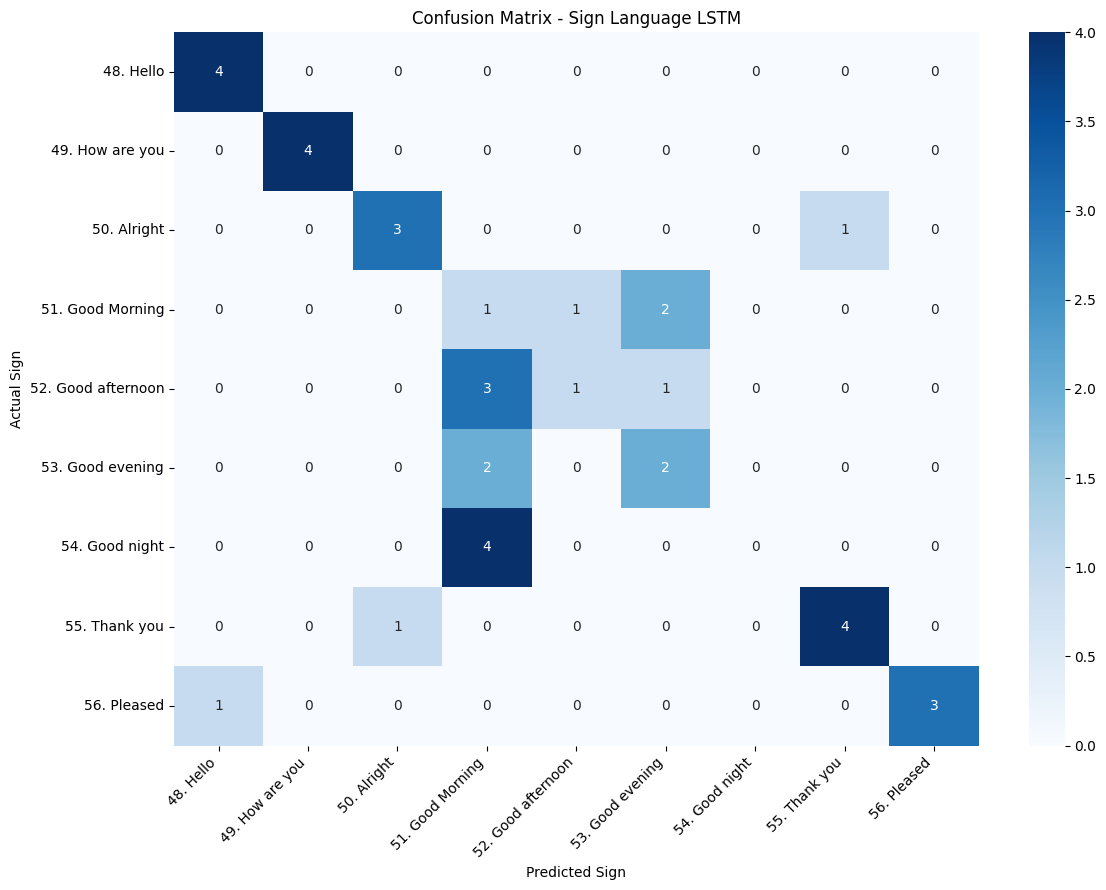


Classification Report:

                    precision    recall  f1-score   support

         48. Hello       0.80      1.00      0.89         4
   49. How are you       1.00      1.00      1.00         4
       50. Alright       0.75      0.75      0.75         4
  51. Good Morning       0.10      0.25      0.14         4
52. Good afternoon       0.50      0.20      0.29         5
  53. Good evening       0.40      0.50      0.44         4
    54. Good night       0.00      0.00      0.00         4
     55. Thank you       0.80      0.80      0.80         5
       56. Pleased       1.00      0.75      0.86         4

          accuracy                           0.58        38
         macro avg       0.59      0.58      0.57        38
      weighted avg       0.60      0.58      0.57        38



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import torch
import numpy as np

model.eval()

with torch.no_grad():
    X = torch.tensor(X_val_norm, dtype=torch.float32).to(device)
    y_true = y_val.cpu().numpy()

    outputs = model(X)
    y_pred = outputs.argmax(dim=1).cpu().numpy()

cm = confusion_matrix(y_true, y_pred, labels=np.arange(9))

class_names = label_encoder.classes_

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Sign")
plt.ylabel("Actual Sign")
plt.title("Confusion Matrix - Sign Language LSTM")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(9),
    target_names=class_names,
    zero_division=0
))

In [ ]:
import numpy as np
from collections import Counter

class_names = label_encoder.classes_

print("TRAINING SAMPLES PER CLASS")
for class_id, count in sorted(Counter(y_train.cpu().numpy()).items()):
    print(f"{class_names[class_id]}: {count}")

print("\nVALIDATION SAMPLES PER CLASS")
for class_id, count in sorted(Counter(y_val.cpu().numpy()).items()):
    print(f"{class_names[class_id]}: {count}")

TRAINING SAMPLES PER CLASS
48. Hello: 17
49. How are you: 17
50. Alright: 17
51. Good Morning: 17
52. Good afternoon: 17
53. Good evening: 17
54. Good night: 17
55. Thank you: 16
56. Pleased: 17

VALIDATION SAMPLES PER CLASS
48. Hello: 4
49. How are you: 4
50. Alright: 4
51. Good Morning: 4
52. Good afternoon: 5
53. Good evening: 4
54. Good night: 4
55. Thank you: 5
56. Pleased: 4


In [ ]:
import torch

def evaluate_accuracy(loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

train_acc_now = evaluate_accuracy(train_loader_norm)
val_acc_now = evaluate_accuracy(val_loader_norm)

print(f"Training Accuracy:   {train_acc_now:.2f}%")
print(f"Validation Accuracy: {val_acc_now:.2f}%")
print(f"Accuracy Gap:        {train_acc_now - val_acc_now:.2f}%")

Training Accuracy:   76.32%
Validation Accuracy: 57.89%
Accuracy Gap:        18.42%


In [ ]:
import numpy as np

def normalize_landmarks_v2(X):
    X = X.copy().reshape(X.shape[0], X.shape[1], 2, 21, 3)

    # A hand is detected if its wrist coordinates are nonzero
    detected = np.any(X[:, :, :, 0, :] != 0, axis=-1)

    # Use the first detected hand's wrist as the shared origin.
    # If only the second hand is detected, use that hand instead.
    origin = X[:, :, 0, 0, :].copy()
    use_second = ~detected[:, :, 0] & detected[:, :, 1]
    origin[use_second] = X[:, :, 1, 0, :][use_second]

    # Keep the relative positions of both hands
    X -= origin[:, :, None, None, :]

    # Apply one shared scale per frame
    scale = np.max(np.abs(X), axis=(2, 3, 4), keepdims=True)
    scale[scale < 1e-6] = 1.0
    X /= scale

    # Preserve missing hands as zeros
    X[~detected] = 0

    return X.reshape(X.shape[0], X.shape[1], 126).astype(np.float32)


X_train_v2 = normalize_landmarks_v2(X_train)
X_val_v2 = normalize_landmarks_v2(X_val)

print("New training shape:", X_train_v2.shape)
print("New validation shape:", X_val_v2.shape)
print("Training values finite:", np.isfinite(X_train_v2).all())
print("Validation values finite:", np.isfinite(X_val_v2).all())

New training shape: (152, 60, 126)
New validation shape: (38, 60, 126)
Training values finite: True
Validation values finite: True


In [ ]:
import copy
import os
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Separate datasets for the experiment
train_dataset_v2 = TensorDataset(
    torch.tensor(X_train_v2, dtype=torch.float32),
    y_train.cpu()
)

val_dataset_v2 = TensorDataset(
    torch.tensor(X_val_v2, dtype=torch.float32),
    y_val.cpu()
)

train_loader_v2 = DataLoader(
    train_dataset_v2, batch_size=16, shuffle=True
)

val_loader_v2 = DataLoader(
    val_dataset_v2, batch_size=16, shuffle=False
)

# Fresh model: original architecture
model_v2 = SignLanguageLSTM(num_classes=9).to(device)

criterion_v2 = nn.CrossEntropyLoss()
optimizer_v2 = torch.optim.Adam(
    model_v2.parameters(), lr=0.001
)

EPOCHS_V2 = 40
best_val_acc_v2 = 0.0

best_path_v2 = os.path.join(
    BASE_DIR, "models", "best_sign_language_lstm_v2.pth"
)

for epoch in range(EPOCHS_V2):
    model_v2.train()
    train_correct = 0
    train_total = 0
    train_loss_total = 0.0

    for inputs, labels in train_loader_v2:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer_v2.zero_grad()
        outputs = model_v2(inputs)
        loss = criterion_v2(outputs, labels)
        loss.backward()
        optimizer_v2.step()

        train_loss_total += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_acc = train_correct / train_total
    train_loss = train_loss_total / train_total

    model_v2.eval()
    val_correct = 0
    val_total = 0
    val_loss_total = 0.0

    with torch.no_grad():
        for inputs, labels in val_loader_v2:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_v2(inputs)
            loss = criterion_v2(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_acc = val_correct / val_total
    val_loss = val_loss_total / val_total

    if val_acc > best_val_acc_v2:
        best_val_acc_v2 = val_acc
        torch.save(model_v2.state_dict(), best_path_v2)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS_V2}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

print(f"\nBest V2 validation accuracy: {best_val_acc_v2:.2%}")
print("Experimental checkpoint:", best_path_v2)

Epoch [01/40] Train Loss: 2.2073 | Train Acc: 9.21% | Val Loss: 2.2026 | Val Acc: 10.53%
Epoch [02/40] Train Loss: 2.2131 | Train Acc: 9.21% | Val Loss: 2.2038 | Val Acc: 13.16%
Epoch [03/40] Train Loss: 2.1964 | Train Acc: 13.82% | Val Loss: 2.2044 | Val Acc: 10.53%
Epoch [04/40] Train Loss: 2.1930 | Train Acc: 13.82% | Val Loss: 2.2028 | Val Acc: 10.53%
Epoch [05/40] Train Loss: 2.1920 | Train Acc: 15.79% | Val Loss: 2.2031 | Val Acc: 13.16%
Epoch [06/40] Train Loss: 2.1825 | Train Acc: 15.13% | Val Loss: 2.2051 | Val Acc: 10.53%
Epoch [07/40] Train Loss: 2.1791 | Train Acc: 14.47% | Val Loss: 2.2042 | Val Acc: 10.53%
Epoch [08/40] Train Loss: 2.1642 | Train Acc: 21.05% | Val Loss: 2.2039 | Val Acc: 15.79%
Epoch [09/40] Train Loss: 2.1339 | Train Acc: 17.76% | Val Loss: 2.1977 | Val Acc: 10.53%
Epoch [10/40] Train Loss: 2.1064 | Train Acc: 20.39% | Val Loss: 2.1854 | Val Acc: 10.53%
Epoch [11/40] Train Loss: 2.0274 | Train Acc: 23.03% | Val Loss: 2.0384 | Val Acc: 21.05%
Epoch [12/40

In [ ]:
import os
import torch

original_path = os.path.join(
    BASE_DIR, "models", "best_sign_language_lstm_norm.pth"
)

model.load_state_dict(
    torch.load(
        original_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

print("Original best model restored.")
print("Checkpoint:", original_path)

Original best model restored.
Checkpoint: /content/drive/MyDrive/T240_Sign_Language/models/best_sign_language_lstm_norm.pth


In [ ]:
import torch

def augment_landmarks(inputs, noise_std=0.01):
    """
    Apply small random perturbations to landmark coordinates.
    Inputs shape: (batch, 60, 126)
    """
    noise = torch.randn_like(inputs) * noise_std
    augmented = inputs + noise

    # Keep normalized coordinates within their expected range
    augmented = torch.clamp(augmented, -1.0, 1.0)

    return augmented

In [ ]:
sample = torch.tensor(X_train_norm[:2], dtype=torch.float32).to(device)
augmented_sample = augment_landmarks(sample)

print("Original shape:", sample.shape)
print("Augmented shape:", augmented_sample.shape)
print("Original unchanged:", torch.allclose(
    sample.cpu(),
    torch.tensor(X_train_norm[:2])
))
print("Augmented values finite:", torch.isfinite(
    augmented_sample
).all().item())

Original shape: torch.Size([2, 60, 126])
Augmented shape: torch.Size([2, 60, 126])
Original unchanged: True
Augmented values finite: True


In [ ]:
import os
import copy
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Separate loaders
train_dataset_aug = TensorDataset(
    torch.tensor(X_train_norm, dtype=torch.float32),
    y_train.cpu()
)

val_dataset_aug = TensorDataset(
    torch.tensor(X_val_norm, dtype=torch.float32),
    y_val.cpu()
)

train_loader_aug = DataLoader(
    train_dataset_aug, batch_size=16, shuffle=True
)

val_loader_aug = DataLoader(
    val_dataset_aug, batch_size=16, shuffle=False
)

# Fresh experimental model
model_aug = SignLanguageLSTM(num_classes=9).to(device)
criterion_aug = nn.CrossEntropyLoss()
optimizer_aug = torch.optim.Adam(
    model_aug.parameters(), lr=0.001
)

best_val_acc_aug = 0.0

aug_path = os.path.join(
    BASE_DIR, "models", "best_sign_language_lstm_aug.pth"
)

for epoch in range(40):
    model_aug.train()
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader_aug:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Augment training inputs only
        inputs = augment_landmarks(inputs, noise_std=0.01)

        optimizer_aug.zero_grad()
        outputs = model_aug(inputs)
        loss = criterion_aug(outputs, labels)
        loss.backward()
        optimizer_aug.step()

        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_acc = train_correct / train_total

    model_aug.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader_aug:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model_aug(inputs)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_acc = val_correct / val_total

    if val_acc > best_val_acc_aug:
        best_val_acc_aug = val_acc
        torch.save(model_aug.state_dict(), aug_path)

    print(
        f"Epoch [{epoch+1:02d}/40] "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Acc: {val_acc:.2%}"
    )

print(f"\nBest augmented validation accuracy: {best_val_acc_aug:.2%}")
print("Experimental checkpoint:", aug_path)

Epoch [01/40] Train Acc: 7.24% | Val Acc: 15.79%
Epoch [02/40] Train Acc: 9.87% | Val Acc: 15.79%
Epoch [03/40] Train Acc: 11.84% | Val Acc: 7.89%
Epoch [04/40] Train Acc: 17.11% | Val Acc: 7.89%
Epoch [05/40] Train Acc: 17.11% | Val Acc: 2.63%
Epoch [06/40] Train Acc: 12.50% | Val Acc: 7.89%
Epoch [07/40] Train Acc: 19.74% | Val Acc: 18.42%
Epoch [08/40] Train Acc: 23.03% | Val Acc: 18.42%
Epoch [09/40] Train Acc: 18.42% | Val Acc: 15.79%
Epoch [10/40] Train Acc: 26.97% | Val Acc: 15.79%
Epoch [11/40] Train Acc: 36.18% | Val Acc: 21.05%
Epoch [12/40] Train Acc: 36.18% | Val Acc: 23.68%
Epoch [13/40] Train Acc: 32.24% | Val Acc: 21.05%
Epoch [14/40] Train Acc: 41.45% | Val Acc: 28.95%
Epoch [15/40] Train Acc: 38.82% | Val Acc: 28.95%
Epoch [16/40] Train Acc: 39.47% | Val Acc: 31.58%
Epoch [17/40] Train Acc: 32.89% | Val Acc: 42.11%
Epoch [18/40] Train Acc: 36.84% | Val Acc: 39.47%
Epoch [19/40] Train Acc: 44.08% | Val Acc: 31.58%
Epoch [20/40] Train Acc: 40.13% | Val Acc: 28.95%
Epoch 

                    precision    recall  f1-score   support

         48. Hello       0.40      0.50      0.44         4
   49. How are you       1.00      1.00      1.00         4
       50. Alright       0.50      0.25      0.33         4
  51. Good Morning       0.00      0.00      0.00         4
52. Good afternoon       0.50      0.60      0.55         5
  53. Good evening       0.12      0.25      0.17         4
    54. Good night       0.00      0.00      0.00         4
     55. Thank you       0.67      0.80      0.73         5
       56. Pleased       0.50      0.50      0.50         4

          accuracy                           0.45        38
         macro avg       0.41      0.43      0.41        38
      weighted avg       0.42      0.45      0.42        38



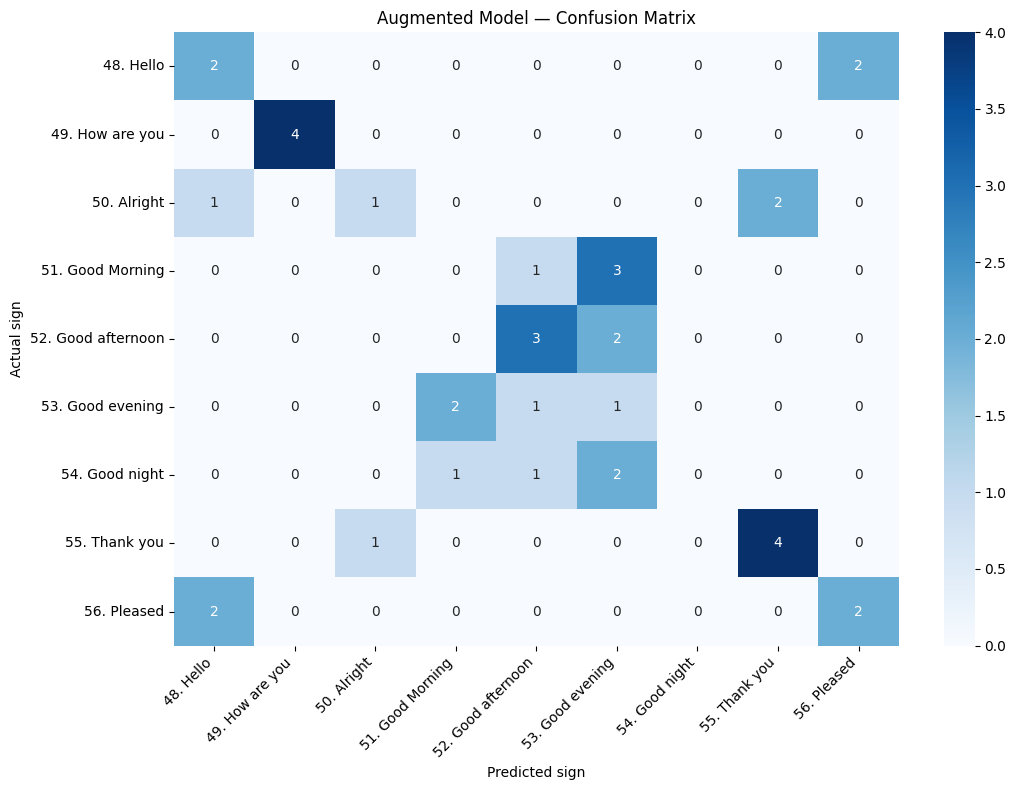

In [ ]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model_aug.load_state_dict(
    torch.load(aug_path, map_location=device, weights_only=True)
)
model_aug.eval()

with torch.no_grad():
    X = torch.tensor(X_val_norm, dtype=torch.float32).to(device)
    y_true = y_val.cpu().numpy()
    y_pred_aug = model_aug(X).argmax(dim=1).cpu().numpy()

print(classification_report(
    y_true,
    y_pred_aug,
    labels=np.arange(9),
    target_names=label_encoder.classes_,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred_aug, labels=np.arange(9))

plt.figure(figsize=(11, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted sign")
plt.ylabel("Actual sign")
plt.title("Augmented Model — Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
import torch
import numpy as np

model.eval()
model_aug.eval()

X = torch.tensor(X_val_norm, dtype=torch.float32).to(device)

with torch.no_grad():
    original_probs = torch.softmax(model(X), dim=1)
    augmented_probs = torch.softmax(model_aug(X), dim=1)

    # Average the predicted class probabilities
    ensemble_probs = (original_probs + augmented_probs) / 2
    ensemble_preds = ensemble_probs.argmax(dim=1).cpu().numpy()

y_true = y_val.cpu().numpy()

original_preds = original_probs.argmax(dim=1).cpu().numpy()
augmented_preds = augmented_probs.argmax(dim=1).cpu().numpy()

print(f"Original accuracy:  {(original_preds == y_true).mean():.2%}")
print(f"Augmented accuracy: {(augmented_preds == y_true).mean():.2%}")
print(f"Ensemble accuracy:  {(ensemble_preds == y_true).mean():.2%}")
print(f"Ensemble correct:   {(ensemble_preds == y_true).sum()}/{len(y_true)}")

Original accuracy:  57.89%
Augmented accuracy: 44.74%
Ensemble accuracy:  52.63%
Ensemble correct:   20/38


In [ ]:
import os
import numpy as np

total_frames = 0
frames_with_landmarks = 0
missing_files = []

for _, row in manifest.iterrows():
    path = row["sequence_path"]

    if not os.path.exists(path):
        missing_files.append(path)
        continue

    seq = np.load(path)
    total_frames += len(seq)
    frames_with_landmarks += np.any(seq != 0, axis=1).sum()

print("Total frames:", total_frames)
print("Frames with landmarks:", frames_with_landmarks)
print("Frames with no landmarks:", total_frames - frames_with_landmarks)

if total_frames:
    print(
        "Landmark coverage:",
        f"{100 * frames_with_landmarks / total_frames:.2f}%"
    )

print("Missing sequence files:", len(missing_files))

Total frames: 12884
Frames with landmarks: 11731
Frames with no landmarks: 1153
Landmark coverage: 91.05%
Missing sequence files: 0


In [ ]:
import numpy as np
import pandas as pd
import os

coverage_results = []

for _, row in manifest.iterrows():
    path = row["sequence_path"]

    if not os.path.exists(path):
        continue

    seq = np.load(path)
    detected_frames = np.any(seq != 0, axis=1).sum()
    total = len(seq)

    coverage_results.append({
        "label": row["label"],
        "video": os.path.basename(row["video_path"]),
        "total_frames": total,
        "detected_frames": detected_frames,
        "missing_frames": total - detected_frames,
        "coverage_percent": round(100 * detected_frames / total, 2)
    })

coverage_df = pd.DataFrame(coverage_results)

print("Videos with lowest landmark coverage:")
display(coverage_df.sort_values("coverage_percent").head(15))

Videos with lowest landmark coverage:


,label,video,total_frames,detected_frames,missing_frames,coverage_percent
51,50. Alright,MVI_0097.MOV,87,52,35,59.77
7,48. Hello,MVI_0089.MOV,68,41,27,60.29
49,50. Alright,MVI_0095.MOV,63,38,25,60.32
8,48. Hello,MVI_0090.MOV,69,43,26,62.32
71,51. Good Morning,MVI_0099.MOV,66,42,24,63.64
70,51. Good Morning,MVI_0098.MOV,66,43,23,65.15
139,54. Good night,MVI_0110.MOV,77,51,26,66.23
30,49. How are you,MVI_0094.MOV,95,65,30,68.42
28,49. How are you,MVI_0092.MOV,83,57,26,68.67
93,52. Good afternoon,MVI_0102.MOV,74,51,23,68.92


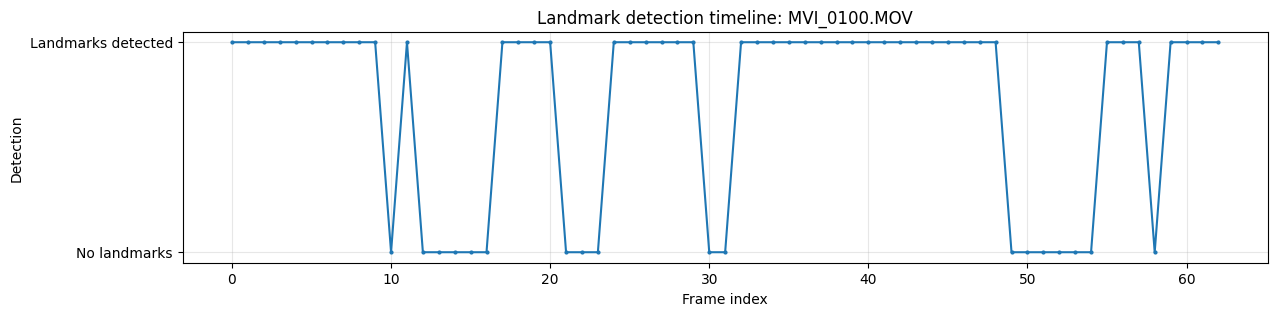

Total frames: 63
Detected: 45
Missing: 18


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

video_name = "MVI_0100.MOV"

row = manifest[
    manifest["video_path"].str.endswith(video_name)
].iloc[0]

seq = np.load(row["sequence_path"])
detected = np.any(seq != 0, axis=1)

plt.figure(figsize=(14, 3))
plt.plot(detected.astype(int), marker=".", markersize=4)
plt.yticks([0, 1], ["No landmarks", "Landmarks detected"])
plt.xlabel("Frame index")
plt.ylabel("Detection")
plt.title(f"Landmark detection timeline: {video_name}")
plt.grid(True, alpha=0.3)
plt.show()

print(f"Total frames: {len(seq)}")
print(f"Detected: {detected.sum()}")
print(f"Missing: {(~detected).sum()}")

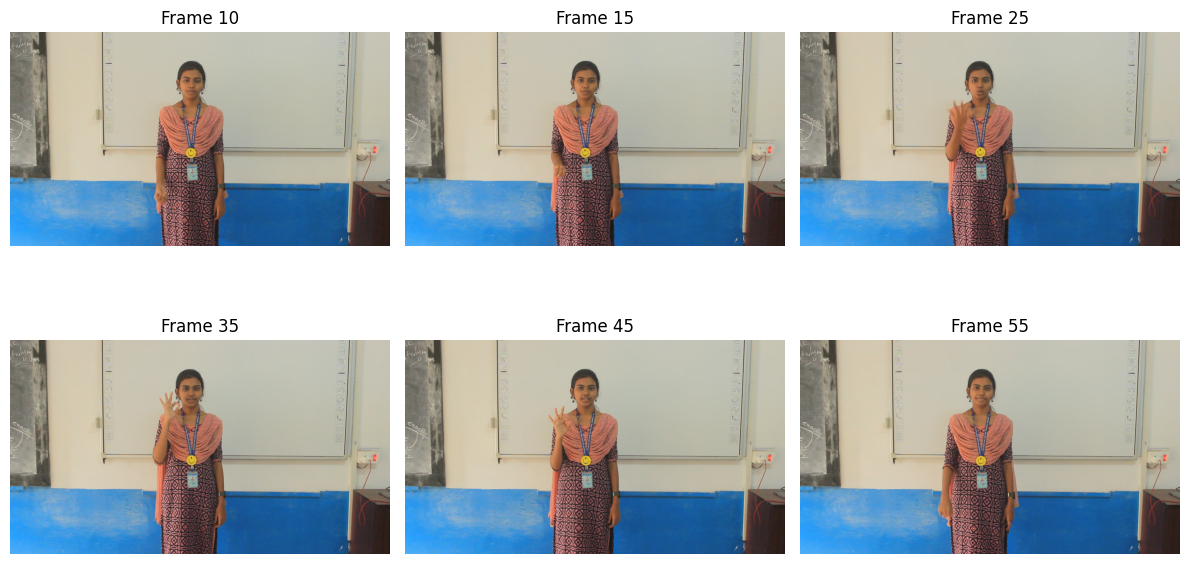

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

video_path = row["video_path"]
cap = cv2.VideoCapture(video_path)

frame_indices = [10, 15, 25, 35, 45, 55]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, idx in zip(axes.flat, frame_indices):
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, frame = cap.read()

    if ret:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        ax.imshow(frame)
        ax.set_title(f"Frame {idx}")
    else:
        ax.set_title(f"Frame {idx}: unavailable")

    ax.axis("off")

cap.release()
plt.tight_layout()
plt.show()

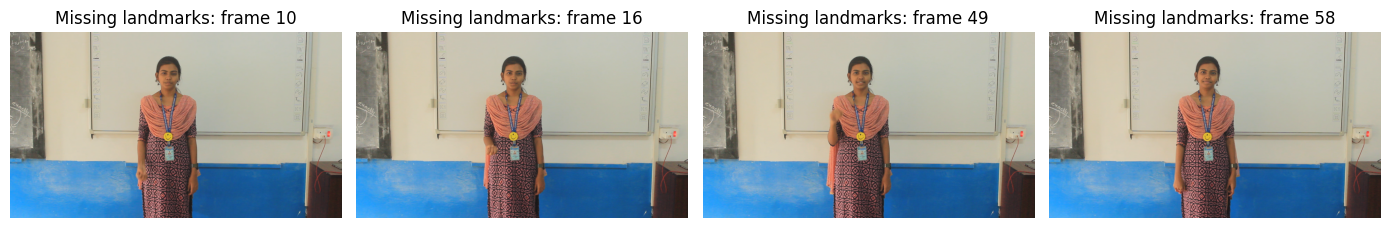

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

video_path = row["video_path"]
seq = np.load(row["sequence_path"])

# Choose 4 frames where landmarks were missing
missing_indices = np.where(~np.any(seq != 0, axis=1))[0]
sample_indices = missing_indices[
    np.linspace(0, len(missing_indices) - 1,
                min(4, len(missing_indices)), dtype=int)
]

cap = cv2.VideoCapture(video_path)
fig, axes = plt.subplots(1, len(sample_indices), figsize=(14, 4))

if len(sample_indices) == 1:
    axes = [axes]

for ax, idx in zip(axes, sample_indices):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ret, frame = cap.read()

    if ret:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Missing landmarks: frame {idx}")
    ax.axis("off")

cap.release()
plt.tight_layout()
plt.show()

In [ ]:
import os
import mediapipe as mp

model_path = "/content/drive/MyDrive/T240_Sign_Language/models/hand_landmarker.task"

print("MediaPipe version:", mp.__version__)
print("Model file exists:", os.path.exists(model_path))
print("Model path:", model_path)

MediaPipe version: 1.2.0
Model file exists: True
Model path: /content/drive/MyDrive/T240_Sign_Language/models/hand_landmarker.task


In [ ]:
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

model_path = "/content/drive/MyDrive/T240_Sign_Language/models/hand_landmarker.task"

base_options = python.BaseOptions(
    model_asset_path=model_path
)

options = vision.HandLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.3,
    min_hand_presence_confidence=0.3
)

hand_landmarker = vision.HandLandmarker.create_from_options(options)

print("HandLandmarker initialized successfully!")

HandLandmarker initialized successfully!


In [ ]:
import cv2
import mediapipe as mp

video_path = row["video_path"]
frame_idx = 47

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
ret, frame = cap.read()
cap.release()

if ret:
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    result = hand_landmarker.detect(mp_image)

    print("Frame:", frame_idx)
    print("Hands detected with lower thresholds:", len(result.hand_landmarks))
else:
    print("Could not read frame.")

Frame: 47
Hands detected with lower thresholds: 1


In [ ]:
import cv2
import mediapipe as mp

video_path = row["video_path"]
frame_indices = [6, 17, 47, 61]

cap = cv2.VideoCapture(video_path)

for idx in frame_indices:
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, frame = cap.read()

    if not ret:
        print(f"Frame {idx}: could not read")
        continue

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    result = hand_landmarker.detect(mp_image)

    print(f"Frame {idx}: {len(result.hand_landmarks)} hand(s) detected")

cap.release()

Frame 6: 2 hand(s) detected
Frame 17: 1 hand(s) detected
Frame 47: 1 hand(s) detected
Frame 61: 1 hand(s) detected


In [ ]:
import cv2
import numpy as np
import mediapipe as mp

video_path = row["video_path"]
cap = cv2.VideoCapture(video_path)

old_seq = np.load(row["sequence_path"])
new_detected = []

for idx in range(int(cap.get(cv2.CAP_PROP_FRAME_COUNT))):
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, frame = cap.read()

    if not ret:
        new_detected.append(False)
        continue

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    result = hand_landmarker.detect(mp_image)
    new_detected.append(len(result.hand_landmarks) > 0)

cap.release()

old_count = np.any(old_seq != 0, axis=1).sum()
new_count = sum(new_detected)

print("Total frames:", len(new_detected))
print(f"Old detected frames: {old_count} ({old_count/len(new_detected)*100:.2f}%)")
print(f"New detected frames: {new_count} ({new_count/len(new_detected)*100:.2f}%)")
print("Additional frames detected:", new_count - old_count)

Total frames: 63
Old detected frames: 45 (71.43%)
New detected frames: 45 (71.43%)
Additional frames detected: 0


In [ ]:
hand_landmarker.detect(mp_image)

HandLandmarkerResult(handedness=[[Category(index=1, score=0.7614881992340088, display_name='Left', category_name='Left')]], hand_landmarks=[[NormalizedLandmark(x=0.38883423805236816, y=0.7737550735473633, z=-8.484805391617556e-08, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.3961043059825897, y=0.7938613891601562, z=-0.005883814767003059, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.3993698060512543, y=0.8203582167625427, z=-0.007232720963656902, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.3979431986808777, y=0.8427245020866394, z=-0.007681120187044144, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.3958544135093689, y=0.8526795506477356, z=-0.0069549293257296085, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.39515116810798645, y=0.8395307660102844, z=-0.00201409705914557, visibility=None, presence=None, name=None), NormalizedLandmark(x=0.39708805084228516, y=0.8633390069007874, 

In [ ]:
import cv2
import numpy as np
import mediapipe as mp

video_path = row["video_path"]

cap = cv2.VideoCapture(video_path)

total_frames = 0
frames_with_hands = 0

while True:
    success, frame = cap.read()
    if not success:
        break

    total_frames += 1

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame_rgb
    )

    result = detector.detect(mp_image)

    if result.hand_landmarks:
        frames_with_hands += 1

cap.release()

print("Video:", video_path)
print("Total frames:", total_frames)
print("Frames with hands:", frames_with_hands)
print(
    "Detection coverage:",
    round(frames_with_hands / total_frames * 100, 2),
    "%"
)

Video: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/51. Good Morning/MVI_0100.MOV
Total frames: 63
Frames with hands: 0
Detection coverage: 0.0 %


In [ ]:
import os
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
LANDMARK_DIR = os.path.join(BASE_DIR, "data", "landmarks")
MANIFEST_PATH = os.path.join(
    BASE_DIR, "reports", "landmark_manifest.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

valid = 0
invalid = []
total_frames = 0
frames_with_hands = 0

for _, row in manifest.iterrows():
    path = row["sequence_path"]

    if not isinstance(path, str) or not os.path.exists(path):
        invalid.append(path)
        continue

    sequence = np.load(path)

    if (
        sequence.ndim != 2
        or sequence.shape[1] != 126
        or sequence.shape[0] == 0
        or not np.isfinite(sequence).all()
    ):
        invalid.append(path)
        continue

    valid += 1
    total_frames += len(sequence)
    frames_with_hands += int(
        np.any(sequence.reshape(-1, 2, 21, 3), axis=(2, 3)).any(axis=1).sum()
    )

print("Manifest entries:", len(manifest))
print("Valid sequences:", valid)
print("Invalid or missing sequences:", len(invalid))
print("Total frames:", total_frames)
print("Frames with landmarks:", frames_with_hands)
print("Coverage:", round(frames_with_hands / total_frames * 100, 2), "%")

Manifest entries: 190
Valid sequences: 190
Invalid or missing sequences: 0
Total frames: 12884
Frames with landmarks: 11731
Coverage: 91.05 %


In [ ]:
import numpy as np

def normalize_landmarks(X):
    X = X.copy()
    X = X.reshape(X.shape[0], X.shape[1], 2, 21, 3)

    for hand_idx in range(2):
        hand = X[:, :, hand_idx, :, :]

        detected = np.any(hand[:, :, 0, :] != 0, axis=-1)

        wrist = hand[:, :, 0:1, :].copy()
        hand -= wrist

        scale = np.max(
            np.abs(hand),
            axis=(2, 3),
            keepdims=True
        )
        scale[scale < 1e-6] = 1.0

        hand /= scale
        hand[~detected] = 0

    return X.reshape(
        X.shape[0], X.shape[1], 126
    ).astype(np.float32)


X_train_norm = normalize_landmarks(X_train)
X_val_norm = normalize_landmarks(X_val)

print("Normalization complete!")
print("X_train_norm:", X_train_norm.shape)
print("X_val_norm:", X_val_norm.shape)
print("Training values finite:", np.isfinite(X_train_norm).all())
print("Validation values finite:", np.isfinite(X_val_norm).all())

Normalization complete!
X_train_norm: (152, 60, 126)
X_val_norm: (38, 60, 126)
Training values finite: True
Validation values finite: True


In [ ]:

import os
import copy
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

torch.manual_seed(42)
np.random.seed(42)

train_dataset = TensorDataset(
    torch.tensor(X_train_norm, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)

val_dataset = TensorDataset(
    torch.tensor(X_val_norm, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False
)

model = SignLanguageLSTM(num_classes=9).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 60
PATIENCE = 10
best_val_loss = float("inf")
epochs_without_improvement = 0

# Keep the previous checkpoint safe
new_checkpoint = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "models/best_sign_language_lstm_earlystop.pth"
)

os.makedirs(os.path.dirname(new_checkpoint), exist_ok=True)
history = []

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        outputs = model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * xb.size(0)
        train_correct += (outputs.argmax(1) == yb).sum().item()
        train_total += yb.size(0)

    model.eval()
    val_loss = 0.0
    val_preds, val_targets = [], []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            outputs = model(xb)
            loss = criterion(outputs, yb)

            val_loss += loss.item() * xb.size(0)
            val_preds.extend(outputs.argmax(1).cpu().numpy())
            val_targets.extend(yb.cpu().numpy())

    train_loss /= train_total
    train_acc = train_correct / train_total
    val_loss /= len(val_dataset)
    val_acc = accuracy_score(val_targets, val_preds)
    val_f1 = f1_score(
        val_targets, val_preds,
        average="macro", zero_division=0
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_f1": val_f1
    })

    # Save the model when validation loss improves
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), new_checkpoint)
        best_val_acc_at_save = val_acc
        best_epoch = epoch + 1
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%} | "
        f"Val F1: {val_f1:.4f} | "
        f"No improvement: {epochs_without_improvement}/{PATIENCE}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch+1}.")
        break

# Restore the best validation-loss checkpoint
model.load_state_dict(
    torch.load(
        new_checkpoint,
        map_location=device,
        weights_only=True
    )
)
model.eval()

print("\nTraining complete!")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy at best-loss epoch: {best_val_acc_at_save:.2%}")
print("Checkpoint saved:", new_checkpoint)


/tmp/ipykernel_8139/541316869.py:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(y_train, dtype=torch.long)
/tmp/ipykernel_8139/541316869.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(y_val, dtype=torch.long)


Epoch [01/60] Train Loss: 2.2067 | Train Acc: 9.87% | Val Loss: 2.1936 | Val Acc: 5.26% | Val F1: 0.0296 | No improvement: 0/10
Epoch [02/60] Train Loss: 2.2033 | Train Acc: 9.87% | Val Loss: 2.1933 | Val Acc: 15.79% | Val F1: 0.0581 | No improvement: 0/10
Epoch [03/60] Train Loss: 2.1825 | Train Acc: 17.76% | Val Loss: 2.1949 | Val Acc: 10.53% | Val F1: 0.0481 | No improvement: 1/10
Epoch [04/60] Train Loss: 2.1802 | Train Acc: 17.76% | Val Loss: 2.1960 | Val Acc: 7.89% | Val F1: 0.0238 | No improvement: 2/10
Epoch [05/60] Train Loss: 2.1763 | Train Acc: 16.45% | Val Loss: 2.1994 | Val Acc: 10.53% | Val F1: 0.0801 | No improvement: 3/10
Epoch [06/60] Train Loss: 2.1714 | Train Acc: 14.47% | Val Loss: 2.1853 | Val Acc: 15.79% | Val F1: 0.0910 | No improvement: 0/10
Epoch [07/60] Train Loss: 2.1208 | Train Acc: 23.68% | Val Loss: 2.1147 | Val Acc: 21.05% | Val F1: 0.1290 | No improvement: 0/10
Epoch [08/60] Train Loss: 2.0159 | Train Acc: 21.71% | Val Loss: 2.0052 | Val Acc: 15.79% | Va

In [ ]:
import torch
from sklearn.metrics import accuracy_score, f1_score

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language/models"

checkpoints = {
    "Previous best": f"{BASE_DIR}/best_sign_language_lstm_reextracted.pth",
    "Early stopping": f"{BASE_DIR}/best_sign_language_lstm_earlystop.pth"
}

X_val_tensor = torch.tensor(
    X_val_norm, dtype=torch.float32
).to(device)

for name, path in checkpoints.items():
    test_model = SignLanguageLSTM(num_classes=9).to(device)
    test_model.load_state_dict(
        torch.load(path, map_location=device, weights_only=True)
    )
    test_model.eval()

    with torch.no_grad():
        predictions = test_model(X_val_tensor).argmax(dim=1).cpu().numpy()

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro", zero_division=0)

    print(f"\n{name}")
    print(f"Accuracy: {accuracy:.2%}")
    print(f"Macro F1: {macro_f1:.4f}")


Previous best
Accuracy: 52.63%
Macro F1: 0.5074

Early stopping
Accuracy: 26.32%
Macro F1: 0.1614


In [ ]:
import os
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

checkpoint_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "models/best_sign_language_lstm_reextracted.pth"
)

# Restore the best saved checkpoint
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

# Predict validation samples
all_preds = []
all_targets = []

with torch.no_grad():
    X_tensor = torch.tensor(
        X_val_norm, dtype=torch.float32
    ).to(device)

    outputs = model(X_tensor)
    predictions = outputs.argmax(dim=1).cpu().numpy()

all_preds = predictions
all_targets = y_val

print("Best checkpoint restored successfully!")
print("\nClassification report:")
print(
    classification_report(
        all_targets,
        all_preds,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

print("Confusion matrix:")
print(confusion_matrix(
    all_targets,
    all_preds,
    labels=np.arange(len(label_encoder.classes_))
))

Best checkpoint restored successfully!

Classification report:
                    precision    recall  f1-score   support

         48. Hello       1.00      1.00      1.00         4
   49. How are you       0.67      1.00      0.80         4
       50. Alright       0.50      0.25      0.33         4
  51. Good Morning       0.20      0.25      0.22         4
52. Good afternoon       0.50      0.40      0.44         5
  53. Good evening       0.00      0.00      0.00         4
    54. Good night       0.00      0.00      0.00         4
     55. Thank you       0.83      1.00      0.91         5
       56. Pleased       1.00      0.75      0.86         4

          accuracy                           0.53        38
         macro avg       0.52      0.52      0.51        38
      weighted avg       0.53      0.53      0.52        38

Confusion matrix:
[[4 0 0 0 0 0 0 0 0]
 [0 4 0 0 0 0 0 0 0]
 [0 2 1 0 0 0 0 1 0]
 [0 0 0 1 0 3 0 0 0]
 [0 0 0 0 2 3 0 0 0]
 [0 0 0 2 2 0 0 0 0]
 [0 0 0 2 

In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"

old_checkpoint = (
    f"{BASE_DIR}/models/best_sign_language_lstm_norm.pth"
)

# Save the currently loaded new model's predictions for reference
new_model = SignLanguageLSTM(num_classes=9).to(device)
new_model.load_state_dict(
    torch.load(
        f"{BASE_DIR}/models/best_sign_language_lstm_reextracted.pth",
        map_location=device,
        weights_only=True
    )
)
new_model.eval()

# Load the old model checkpoint
old_model = SignLanguageLSTM(num_classes=9).to(device)
old_model.load_state_dict(
    torch.load(
        old_checkpoint,
        map_location=device,
        weights_only=True
    )
)
old_model.eval()

X_val_tensor = torch.tensor(
    X_val_norm, dtype=torch.float32
).to(device)

with torch.no_grad():
    old_preds = old_model(X_val_tensor).argmax(1).cpu().numpy()
    new_preds = new_model(X_val_tensor).argmax(1).cpu().numpy()

print("Old model accuracy:", round(accuracy_score(y_val, old_preds) * 100, 2), "%")
print("New model accuracy:", round(accuracy_score(y_val, new_preds) * 100, 2), "%")

print("\nOLD MODEL REPORT")
print(classification_report(
    y_val, old_preds,
    labels=np.arange(9),
    target_names=label_encoder.classes_,
    zero_division=0
))

print("\nNEW MODEL REPORT")
print(classification_report(
    y_val, new_preds,
    labels=np.arange(9),
    target_names=label_encoder.classes_,
    zero_division=0
))

Old model accuracy: 57.89 %
New model accuracy: 52.63 %

OLD MODEL REPORT
                    precision    recall  f1-score   support

         48. Hello       0.80      1.00      0.89         4
   49. How are you       1.00      1.00      1.00         4
       50. Alright       0.75      0.75      0.75         4
  51. Good Morning       0.10      0.25      0.14         4
52. Good afternoon       0.50      0.20      0.29         5
  53. Good evening       0.40      0.50      0.44         4
    54. Good night       0.00      0.00      0.00         4
     55. Thank you       0.80      0.80      0.80         5
       56. Pleased       1.00      0.75      0.86         4

          accuracy                           0.58        38
         macro avg       0.59      0.58      0.57        38
      weighted avg       0.60      0.58      0.57        38


NEW MODEL REPORT
                    precision    recall  f1-score   support

         48. Hello       1.00      1.00      1.00         4
   4

In [ ]:
print("Training samples:", len(X_train_norm))
print("Validation samples:", len(X_val_norm))
print("Current best checkpoint:")
print("/content/drive/MyDrive/T240_Sign_Language/models/best_sign_language_lstm_reextracted.pth")

Training samples: 152
Validation samples: 38
Current best checkpoint:
/content/drive/MyDrive/T240_Sign_Language/models/best_sign_language_lstm_reextracted.pth


In [ ]:
import torch
from sklearn.metrics import classification_report

model = SignLanguageLSTM(num_classes=9).to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/T240_Sign_Language/models/"
        "best_sign_language_lstm_reextracted.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

X_val_tensor = torch.tensor(
    X_val_norm, dtype=torch.float32
).to(device)

with torch.no_grad():
    predictions = model(X_val_tensor).argmax(dim=1).cpu().numpy()

print(classification_report(
    y_val,
    predictions,
    labels=np.arange(9),
    target_names=label_encoder.classes_,
    zero_division=0
))

                    precision    recall  f1-score   support

         48. Hello       1.00      1.00      1.00         4
   49. How are you       0.67      1.00      0.80         4
       50. Alright       0.50      0.25      0.33         4
  51. Good Morning       0.20      0.25      0.22         4
52. Good afternoon       0.50      0.40      0.44         5
  53. Good evening       0.00      0.00      0.00         4
    54. Good night       0.00      0.00      0.00         4
     55. Thank you       0.83      1.00      0.91         5
       56. Pleased       1.00      0.75      0.86         4

          accuracy                           0.53        38
         macro avg       0.52      0.52      0.51        38
      weighted avg       0.53      0.53      0.52        38



In [ ]:
import torch
import numpy as np

model.eval()

X_val_tensor = torch.tensor(
    X_val_norm, dtype=torch.float32
).to(device)

with torch.no_grad():
    predictions = model(X_val_tensor).argmax(dim=1).cpu().numpy()

print("MISCLASSIFIED VALIDATION SAMPLES\n")

mistakes = 0

for i, (true_id, pred_id) in enumerate(zip(y_val, predictions)):
    if true_id != pred_id:
        print(f"Sample: {i}")
        print(f"Actual:    {label_encoder.classes_[true_id]}")
        print(f"Predicted: {label_encoder.classes_[pred_id]}")
        print("-" * 40)
        mistakes += 1

print(f"\nTotal incorrect: {mistakes}/{len(y_val)}")

MISCLASSIFIED VALIDATION SAMPLES

Sample: 1
Actual:    50. Alright
Predicted: 49. How are you
----------------------------------------
Sample: 5
Actual:    51. Good Morning
Predicted: 53. Good evening
----------------------------------------
Sample: 6
Actual:    54. Good night
Predicted: 53. Good evening
----------------------------------------
Sample: 7
Actual:    54. Good night
Predicted: 51. Good Morning
----------------------------------------
Sample: 8
Actual:    51. Good Morning
Predicted: 53. Good evening
----------------------------------------
Sample: 9
Actual:    52. Good afternoon
Predicted: 53. Good evening
----------------------------------------
Sample: 13
Actual:    50. Alright
Predicted: 55. Thank you
----------------------------------------
Sample: 15
Actual:    53. Good evening
Predicted: 51. Good Morning
----------------------------------------
Sample: 17
Actual:    52. Good afternoon
Predicted: 53. Good evening
----------------------------------------
Sample: 18
Act

In [ ]:
import os
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
LANDMARK_DIR = os.path.join(BASE_DIR, "data", "landmarks")

manifest = pd.read_csv(
    os.path.join(BASE_DIR, "reports", "landmark_manifest.csv")
)

print("Manifest columns:")
print(manifest.columns.tolist())

print("\nFirst 3 rows:")
display(manifest.head(3))

Manifest columns:
['video_path', 'label', 'sequence_path', 'frames', 'frames_with_hands', 'status']

First 3 rows:


,video_path,label,sequence_path,frames,frames_with_hands,status
0,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,63,63,success
1,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,74,74,success
2,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,65,65,success


In [ ]:
manifest["coverage_percent"] = (
    manifest["frames_with_hands"] / manifest["frames"] * 100
)

summary = (
    manifest[manifest["status"].isin(["success", "already_saved"])]
    .groupby("label")
    .agg(
        videos=("video_path", "count"),
        avg_coverage=("coverage_percent", "mean"),
        min_coverage=("coverage_percent", "min"),
        max_coverage=("coverage_percent", "max")
    )
    .round(2)
    .sort_values("avg_coverage")
)

display(summary)

,videos,avg_coverage,min_coverage,max_coverage
label,,,,
55. Thank you,21,84.32,75.81,94.19
50. Alright,21,85.89,59.77,96.43
49. How are you,21,86.84,68.42,95.35
54. Good night,21,91.04,66.23,100.00
48. Hello,21,92.49,60.29,100.00
56. Pleased,21,93.53,73.85,100.00
51. Good Morning,21,94.25,63.64,100.00
52. Good afternoon,22,94.72,68.92,100.00
53. Good evening,21,95.58,81.33,100.00


In [ ]:
duration_summary = (
    manifest[manifest["status"] == "success"]
    .groupby("label")
    .agg(
        videos=("frames", "count"),
        avg_frames=("frames", "mean"),
        min_frames=("frames", "min"),
        max_frames=("frames", "max")
    )
    .round(1)
    .sort_values("avg_frames")
)

display(duration_summary)

,videos,avg_frames,min_frames,max_frames
label,,,,
48. Hello,21,61.9,47,84
56. Pleased,21,62.7,44,87
55. Thank you,21,64.0,52,86
51. Good Morning,21,66.7,41,90
52. Good afternoon,22,67.5,47,91
50. Alright,21,67.5,51,87
54. Good night,21,70.0,55,93
53. Good evening,21,70.2,53,95
49. How are you,21,79.8,60,100


In [ ]:
import pandas as pd
import numpy as np

TARGET_FRAMES = 60

manifest["sequence_length"] = manifest["sequence_path"].apply(
    lambda path: len(np.load(path, mmap_mode="r"))
)

manifest["padding_frames"] = (
    TARGET_FRAMES - manifest["sequence_length"]
).clip(lower=0)

summary = (
    manifest.groupby("label")
    .agg(
        videos=("sequence_length", "count"),
        avg_length=("sequence_length", "mean"),
        videos_padded=("padding_frames", lambda s: (s > 0).sum()),
        avg_padding=("padding_frames", "mean"),
        max_padding=("padding_frames", "max")
    )
    .round(1)
)

display(summary)

,videos,avg_length,videos_padded,avg_padding,max_padding
label,,,,,
48. Hello,21,61.9,10,4.2,13
49. How are you,21,79.8,0,0.0,0
50. Alright,21,67.5,8,2.2,9
51. Good Morning,21,66.7,8,2.4,19
52. Good afternoon,22,67.5,7,2.0,13
53. Good evening,21,70.2,6,1.3,7
54. Good night,21,70.0,6,1.0,5
55. Thank you,21,64.0,10,2.4,8
56. Pleased,21,62.7,10,4.0,16


In [ ]:
import os
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    MODEL_DIR,
    "best_sign_language_lstm_interpolated.pth"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Prepare tensors
train_dataset = TensorDataset(
    torch.tensor(X_train_norm, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)

val_dataset = TensorDataset(
    torch.tensor(X_val_norm, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False
)

# Model
model = SignLanguageLSTM(
    input_size=126,
    hidden_size=64,
    num_classes=9
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

best_val_acc = 0.0
best_val_f1 = 0.0
EPOCHS = 60

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for features, labels in train_loader:
        features = features.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(features)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for features, labels in val_loader:
            features = features.to(device)
            labels = labels.to(device)

            outputs = model(features)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_acc = accuracy_score(all_labels, all_preds)
    val_f1 = f1_score(
        all_labels, all_preds,
        average="macro",
        zero_division=0
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_val_f1 = val_f1

        torch.save(model.state_dict(), checkpoint_path)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss/len(train_loader):.4f} | "
        f"Val Loss: {val_loss/len(val_loader):.4f} | "
        f"Val Acc: {val_acc:.2%} | "
        f"Macro F1: {val_f1:.4f}"
    )

print("\nTraining complete!")
print(f"Best validation accuracy: {best_val_acc:.2%}")
print(f"Macro F1 at best accuracy: {best_val_f1:.4f}")
print("Checkpoint:", checkpoint_path)

/tmp/ipykernel_8139/3658235743.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(y_train, dtype=torch.long)
/tmp/ipykernel_8139/3658235743.py:26: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(y_val, dtype=torch.long)


Epoch [01/60] Train Loss: 2.2102 | Val Loss: 2.1968 | Val Acc: 5.26% | Macro F1: 0.0207
Epoch [02/60] Train Loss: 2.1903 | Val Loss: 2.1900 | Val Acc: 13.16% | Macro F1: 0.0973
Epoch [03/60] Train Loss: 2.1858 | Val Loss: 2.1994 | Val Acc: 7.89% | Macro F1: 0.0414
Epoch [04/60] Train Loss: 2.1593 | Val Loss: 2.1952 | Val Acc: 13.16% | Macro F1: 0.0550
Epoch [05/60] Train Loss: 2.0976 | Val Loss: 2.1424 | Val Acc: 13.16% | Macro F1: 0.0570
Epoch [06/60] Train Loss: 1.9658 | Val Loss: 1.9434 | Val Acc: 13.16% | Macro F1: 0.0483
Epoch [07/60] Train Loss: 1.8936 | Val Loss: 1.7878 | Val Acc: 13.16% | Macro F1: 0.0816
Epoch [08/60] Train Loss: 1.7969 | Val Loss: 1.7392 | Val Acc: 23.68% | Macro F1: 0.1333
Epoch [09/60] Train Loss: 1.7384 | Val Loss: 2.0184 | Val Acc: 13.16% | Macro F1: 0.1083
Epoch [10/60] Train Loss: 1.8126 | Val Loss: 2.1653 | Val Acc: 15.79% | Macro F1: 0.0700
Epoch [11/60] Train Loss: 1.8241 | Val Loss: 2.1384 | Val Acc: 18.42% | Macro F1: 0.0825
Epoch [12/60] Train Los

In [ ]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

checkpoint_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "models/best_sign_language_lstm_interpolated.pth"
)

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

with torch.no_grad():
    X_tensor = torch.tensor(
        X_val_norm, dtype=torch.float32
    ).to(device)

    outputs = model(X_tensor)
    predictions = outputs.argmax(dim=1).cpu().numpy()

print("Validation accuracy:", accuracy_score(y_val, predictions))
print("Macro F1:", f1_score(
    y_val, predictions, average="macro", zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_val, predictions,
    labels=np.arange(len(label_encoder.classes_))
))

Validation accuracy: 0.47368421052631576
Macro F1: 0.47005772005772006

Classification Report:
                    precision    recall  f1-score   support

         48. Hello       0.75      0.75      0.75         4
   49. How are you       0.75      0.75      0.75         4
       50. Alright       0.29      0.50      0.36         4
  51. Good Morning       0.25      0.25      0.25         4
52. Good afternoon       0.60      0.60      0.60         5
  53. Good evening       0.00      0.00      0.00         4
    54. Good night       1.00      0.25      0.40         4
     55. Thank you       0.50      0.60      0.55         5
       56. Pleased       0.67      0.50      0.57         4

          accuracy                           0.47        38
         macro avg       0.53      0.47      0.47        38
      weighted avg       0.53      0.47      0.48        38

Confusion Matrix:
[[3 0 0 0 0 0 0 0 1]
 [0 3 1 0 0 0 0 0 0]
 [0 0 2 0 0 0 0 2 0]
 [0 0 1 1 0 2 0 0 0]
 [0 0 1 0 3 1 0 0 0]

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

model.eval()

with torch.no_grad():
    X_train_tensor = torch.tensor(
        X_train_norm,
        dtype=torch.float32
    ).to(device)

    train_outputs = model(X_train_tensor)
    train_predictions = train_outputs.argmax(dim=1).cpu().numpy()

train_acc = accuracy_score(y_train, train_predictions)
train_f1 = f1_score(
    y_train,
    train_predictions,
    average="macro",
    zero_division=0
)

print(f"Training accuracy: {train_acc:.2%}")
print(f"Training Macro F1: {train_f1:.4f}")
print(f"Validation accuracy: {accuracy_score(y_val, predictions):.2%}")

Training accuracy: 56.58%
Training Macro F1: 0.5414
Validation accuracy: 47.37%


In [ ]:
import numpy as np

def report_missing_landmarks(X, name):
    # Shape: samples, frames, 2 hands, 21 landmarks, 3 coordinates
    data = X.reshape(X.shape[0], X.shape[1], 2, 21, 3)

    # A landmark is missing when all three coordinates are zero
    missing = np.all(data == 0, axis=-1)

    total = missing.size
    missing_count = missing.sum()

    print(f"{name}:")
    print(f"  Total landmarks: {total}")
    print(f"  Missing landmarks: {missing_count}")
    print(f"  Missing rate: {missing_count / total:.2%}")

report_missing_landmarks(X_train, "Training set")
report_missing_landmarks(X_val, "Validation set")

Training set:
  Total landmarks: 383040
  Missing landmarks: 67641
  Missing rate: 17.66%
Validation set:
  Total landmarks: 95760
  Missing landmarks: 20643
  Missing rate: 21.56%


In [ ]:
import numpy as np

def report_hand_detection(X, name):
    data = X.reshape(X.shape[0], X.shape[1], 2, 21, 3)

    print(f"\n{name}")

    for hand_idx, hand_name in enumerate(["Hand 1", "Hand 2"]):
        hand = data[:, :, hand_idx, :, :]

        # A hand is detected in a frame if at least one landmark is nonzero
        detected = np.any(hand != 0, axis=(2, 3))

        total_frames = detected.size
        detected_frames = detected.sum()

        print(
            f"{hand_name}: detected in "
            f"{detected_frames}/{total_frames} frames "
            f"({detected_frames / total_frames:.2%})"
        )

report_hand_detection(X_train, "Training set")
report_hand_detection(X_val, "Validation set")


Training set
Hand 1: detected in 7667/9120 frames (84.07%)
Hand 2: detected in 7352/9120 frames (80.61%)

Validation set
Hand 1: detected in 1823/2280 frames (79.96%)
Hand 2: detected in 1754/2280 frames (76.93%)


In [ ]:
import torch
from sklearn.metrics import accuracy_score, f1_score

model.eval()

X_val_tensor = torch.tensor(
    X_val_norm, dtype=torch.float32
).clone()

y_true = y_val

def evaluate_input(X_input, experiment_name):
    with torch.no_grad():
        outputs = model(X_input.to(device))
        preds = outputs.argmax(dim=1).cpu().numpy()

    acc = accuracy_score(y_true, preds)
    f1 = f1_score(
        y_true, preds,
        average="macro",
        zero_division=0
    )

    print(
        f"{experiment_name}: "
        f"Accuracy={acc:.2%}, Macro F1={f1:.4f}"
    )

# Baseline: both hands
evaluate_input(X_val_tensor, "Both hands")

# Mask Hand 1 (features 0–62)
hand1_masked = X_val_tensor.clone()
hand1_masked[:, :, :63] = 0
evaluate_input(hand1_masked, "Hand 1 masked")

# Mask Hand 2 (features 63–125)
hand2_masked = X_val_tensor.clone()
hand2_masked[:, :, 63:] = 0
evaluate_input(hand2_masked, "Hand 2 masked")

Both hands: Accuracy=47.37%, Macro F1=0.4701
Hand 1 masked: Accuracy=18.42%, Macro F1=0.1064
Hand 2 masked: Accuracy=23.68%, Macro F1=0.1407


In [ ]:
# import numpy as np

# # Inspect a few original sequences before normalization
# for i in range(min(5, len(X))):
#     sequence = X[i].reshape(60, 2, 21, 3)

#     print(f"\nSample {i}")

#     for hand_idx, hand_name in enumerate(["Hand 1", "Hand 2"]):
#         hand = sequence[:, hand_idx]

#         wrist_detected = np.any(hand[:, 0, :] != 0, axis=1)
#         any_landmark_detected = np.any(hand != 0, axis=(1, 2))

#         print(
#             f"{hand_name}: "
#             f"any landmark detected={any_landmark_detected.mean():.1%}, "
#             f"wrist detected={wrist_detected.mean():.1%}"
#         )


Sample 0


TypeError: any() received an invalid combination of arguments - got (out=NoneType, axis=int, ), but expected one of:
 * ()
 * (tuple of ints dim = None, bool keepdim = False)
      didn't match because some of the keywords were incorrect: out, axis
 * (int dim, bool keepdim = False)
      didn't match because some of the keywords were incorrect: out, axis
 * (name dim, bool keepdim = False)
      didn't match because some of the keywords were incorrect: out, axis


In [ ]:
import numpy as np

def inspect_wrist_detection(X, name):
    data = X.reshape(X.shape[0], X.shape[1], 2, 21, 3)

    for hand_idx, hand_name in enumerate(["Hand 1", "Hand 2"]):
        hand = data[:, :, hand_idx]

        any_landmark = np.any(hand != 0, axis=(2, 3))
        wrist_detected = np.any(hand[:, :, 0, :] != 0, axis=-1)

        # Frames where other landmarks exist but wrist is missing
        wrist_missing_with_other_landmarks = (
            any_landmark & ~wrist_detected
        )

        print(f"{name} — {hand_name}")
        print(
            "Frames with other landmarks but missing wrist:",
            int(wrist_missing_with_other_landmarks.sum())
        )

inspect_wrist_detection(X_train, "Training")
inspect_wrist_detection(X_val, "Validation")

Training — Hand 1
Frames with other landmarks but missing wrist: 0
Training — Hand 2
Frames with other landmarks but missing wrist: 0
Validation — Hand 1
Frames with other landmarks but missing wrist: 0
Validation — Hand 2
Frames with other landmarks but missing wrist: 0


In [ ]:
import numpy as np

def check_normalization(X, name):
    data = X.reshape(X.shape[0], X.shape[1], 2, 21, 3)

    print(f"\n{name}")
    print("All values finite:", np.isfinite(X).all())
    print("Minimum:", X.min())
    print("Maximum:", X.max())

    for hand_idx, hand_name in enumerate(["Hand 1", "Hand 2"]):
        hand = data[:, :, hand_idx]

        missing = np.all(hand == 0, axis=-1)
        print(
            f"{hand_name} — zero landmarks:",
            f"{missing.sum()}/{missing.size}"
        )

check_normalization(X_train_norm, "Normalized training data")
check_normalization(X_val_norm, "Normalized validation data")


Normalized training data
All values finite: True
Minimum: -1.0
Maximum: 1.0
Hand 1 — zero landmarks: 38180/191520
Hand 2 — zero landmarks: 44480/191520

Normalized validation data
All values finite: True
Minimum: -1.0
Maximum: 1.0
Hand 1 — zero landmarks: 11420/47880
Hand 2 — zero landmarks: 12800/47880


In [ ]:
import numpy as np

def check_missing_frames(X, name):
    data = X.reshape(X.shape[0], X.shape[1], 2, 21, 3)

    print(f"\n{name}")

    for hand_idx, hand_name in enumerate(["Hand 1", "Hand 2"]):
        hand = data[:, :, hand_idx]
        missing_frame = np.all(hand == 0, axis=(2, 3))

        print(
            f"{hand_name}: completely missing frames = "
            f"{missing_frame.sum()}/{missing_frame.size} "
            f"({missing_frame.mean():.2%})"
        )

check_missing_frames(X_train, "Training sequences")
check_missing_frames(X_val, "Validation sequences")


Training sequences
Hand 1: completely missing frames = 1453/9120 (15.93%)
Hand 2: completely missing frames = 1768/9120 (19.39%)

Validation sequences
Hand 1: completely missing frames = 457/2280 (20.04%)
Hand 2: completely missing frames = 526/2280 (23.07%)


In [ ]:
import numpy as np

hand_missing = np.zeros(2, dtype=np.int64)
total_frames = 0

for _, row in manifest.iterrows():
    sequence = np.load(row["sequence_path"]).astype(np.float32)

    if sequence.ndim != 2 or sequence.shape[1] != 126:
        continue

    data = sequence.reshape(len(sequence), 2, 21, 3)
    total_frames += len(sequence)

    for hand_idx in range(2):
        hand = data[:, hand_idx]
        missing = np.all(hand == 0, axis=(1, 2))
        hand_missing[hand_idx] += missing.sum()

print("Original sequence frames:", total_frames)

for hand_idx, name in enumerate(["Hand 1", "Hand 2"]):
    print(
        f"{name} completely missing: "
        f"{hand_missing[hand_idx]}/{total_frames} "
        f"({hand_missing[hand_idx] / total_frames:.2%})"
    )

Original sequence frames: 12884
Hand 1 completely missing: 2750/12884 (21.34%)
Hand 2 completely missing: 3319/12884 (25.76%)


In [ ]:
import numpy as np

def resample_hand_safely(sequence, target_frames=60):
    sequence = np.asarray(sequence, dtype=np.float32).copy()

    if sequence.ndim != 2 or sequence.shape[1] != 126:
        raise ValueError("Expected shape (frames, 126)")

    if len(sequence) == 0:
        raise ValueError("Empty sequence")

    # Shape: frames x 2 hands x 21 landmarks x 3 coordinates
    data = sequence.reshape(len(sequence), 2, 21, 3)

    for hand_idx in range(2):
        hand = data[:, hand_idx]

        # A frame is valid if the hand has detected landmarks
        valid = np.any(hand != 0, axis=(1, 2))
        valid_indices = np.flatnonzero(valid)

        # Fill missing frames using the nearest valid frame
        if len(valid_indices) > 0:
            for frame_idx in np.flatnonzero(~valid):
                nearest = valid_indices[
                    np.argmin(np.abs(valid_indices - frame_idx))
                ]
                hand[frame_idx] = hand[nearest]

    # Resample after handling missing frames
    old_positions = np.linspace(0, 1, len(data))
    new_positions = np.linspace(0, 1, target_frames)

    resampled = np.empty((target_frames, 126), dtype=np.float32)

    flat = data.reshape(len(data), 126)
    for feature_idx in range(126):
        resampled[:, feature_idx] = np.interp(
            new_positions,
            old_positions,
            flat[:, feature_idx]
        )

    return resampled


# Test on one original sequence
test_sequence = np.load(manifest.iloc[0]["sequence_path"])
test_result = resample_hand_safely(test_sequence)

print("Original shape:", test_sequence.shape)
print("Processed shape:", test_result.shape)
print("All values finite:", np.isfinite(test_result).all())

Original shape: (63, 126)
Processed shape: (60, 126)
All values finite: True


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import os

X_list = []
y_list = []
skipped = 0

# Keep the existing label mapping
label_encoder = LabelEncoder()
label_encoder.fit(manifest["label"])

for _, row in manifest.iterrows():
    try:
        sequence = np.load(row["sequence_path"]).astype(np.float32)

        if (
            sequence.ndim != 2
            or sequence.shape[1] != 126
            or len(sequence) == 0
            or not np.isfinite(sequence).all()
        ):
            skipped += 1
            continue

        processed = resample_hand_safely(sequence, target_frames=60)

        X_list.append(processed)
        y_list.append(label_encoder.transform([row["label"]])[0])

    except Exception as e:
        skipped += 1
        print("Skipped:", row["sequence_path"], "|", str(e))

X = np.asarray(X_list, dtype=np.float32)
y = np.asarray(y_list, dtype=np.int64)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Full dataset:", X.shape)
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Skipped sequences:", skipped)
print("All values finite:", np.isfinite(X).all())
print("Classes:", len(label_encoder.classes_))

Full dataset: (190, 60, 126)
Training: (152, 60, 126)
Validation: (38, 60, 126)
Skipped sequences: 0
All values finite: True
Classes: 9


In [ ]:
X_train_norm = normalize_landmarks(X_train)
X_val_norm = normalize_landmarks(X_val)

print("X_train_norm:", X_train_norm.shape)
print("X_val_norm:", X_val_norm.shape)
print("Training values finite:", np.isfinite(X_train_norm).all())
print("Validation values finite:", np.isfinite(X_val_norm).all())
print("Training range:", X_train_norm.min(), "to", X_train_norm.max())
print("Validation range:", X_val_norm.min(), "to", X_val_norm.max())

X_train_norm: (152, 60, 126)
X_val_norm: (38, 60, 126)
Training values finite: True
Validation values finite: True
Training range: -1.0 to 1.0
Validation range: -1.0 to 1.0


In [ ]:
import os
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
checkpoint_path = os.path.join(
    BASE_DIR, "models", "best_sign_language_lstm_nearestfill.pth"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_dataset = TensorDataset(
    torch.tensor(X_train_norm, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)
val_dataset = TensorDataset(
    torch.tensor(X_val_norm, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long)
)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

model = SignLanguageLSTM(
    input_size=126, hidden_size=64, num_classes=9
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

best_val_acc = -1.0
best_val_f1 = 0.0
EPOCHS = 60

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for features, labels in train_loader:
        features, labels = features.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(features)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for features, labels in val_loader:
            features, labels = features.to(device), labels.to(device)
            outputs = model(features)
            val_loss += criterion(outputs, labels).item()

            all_preds.extend(outputs.argmax(1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_acc = accuracy_score(all_labels, all_preds)
    val_f1 = f1_score(
        all_labels, all_preds, average="macro", zero_division=0
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_val_f1 = val_f1
        torch.save(model.state_dict(), checkpoint_path)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss / len(train_loader):.4f} | "
        f"Val Loss: {val_loss / len(val_loader):.4f} | "
        f"Val Acc: {val_acc:.2%} | Macro F1: {val_f1:.4f}"
    )

print("\nTraining complete!")
print(f"Best validation accuracy: {best_val_acc:.2%}")
print(f"Macro F1 at best accuracy: {best_val_f1:.4f}")
print("Checkpoint:", checkpoint_path)

Epoch [01/60] Train Loss: 2.2274 | Val Loss: 2.1971 | Val Acc: 13.16% | Macro F1: 0.0258
Epoch [02/60] Train Loss: 2.2131 | Val Loss: 2.2060 | Val Acc: 5.26% | Macro F1: 0.0131
Epoch [03/60] Train Loss: 2.1927 | Val Loss: 2.2116 | Val Acc: 5.26% | Macro F1: 0.0200
Epoch [04/60] Train Loss: 2.1810 | Val Loss: 2.2225 | Val Acc: 7.89% | Macro F1: 0.0175
Epoch [05/60] Train Loss: 2.1920 | Val Loss: 2.2194 | Val Acc: 5.26% | Macro F1: 0.0248
Epoch [06/60] Train Loss: 2.1943 | Val Loss: 2.2224 | Val Acc: 13.16% | Macro F1: 0.0673
Epoch [07/60] Train Loss: 2.1730 | Val Loss: 2.2328 | Val Acc: 13.16% | Macro F1: 0.0662
Epoch [08/60] Train Loss: 2.1560 | Val Loss: 2.2491 | Val Acc: 10.53% | Macro F1: 0.0602
Epoch [09/60] Train Loss: 2.1580 | Val Loss: 2.2590 | Val Acc: 13.16% | Macro F1: 0.0684
Epoch [10/60] Train Loss: 2.1389 | Val Loss: 2.2837 | Val Acc: 13.16% | Macro F1: 0.0551
Epoch [11/60] Train Loss: 2.0952 | Val Loss: 2.3123 | Val Acc: 13.16% | Macro F1: 0.0620
Epoch [12/60] Train Loss:

In [ ]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, f1_score

checkpoint_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "models/best_sign_language_lstm_nearestfill.pth"
)

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

with torch.no_grad():
    X_tensor = torch.tensor(
        X_val_norm, dtype=torch.float32
    ).to(device)

    outputs = model(X_tensor)
    predictions = outputs.argmax(dim=1).cpu().numpy()

print("Validation accuracy:", accuracy_score(y_val, predictions))
print("Macro F1:", f1_score(
    y_val, predictions,
    average="macro",
    zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_val, predictions,
    labels=np.arange(len(label_encoder.classes_))
))

Validation accuracy: 0.7105263157894737
Macro F1: 0.7101571268237935

Classification Report:
                    precision    recall  f1-score   support

         48. Hello       1.00      1.00      1.00         4
   49. How are you       1.00      1.00      1.00         4
       50. Alright       1.00      1.00      1.00         4
  51. Good Morning       0.29      0.50      0.36         4
52. Good afternoon       0.33      0.20      0.25         5
  53. Good evening       0.50      0.25      0.33         4
    54. Good night       0.40      0.50      0.44         4
     55. Thank you       1.00      1.00      1.00         5
       56. Pleased       1.00      1.00      1.00         4

          accuracy                           0.71        38
         macro avg       0.72      0.72      0.71        38
      weighted avg       0.72      0.71      0.71        38

Confusion Matrix:
[[4 0 0 0 0 0 0 0 0]
 [0 4 0 0 0 0 0 0 0]
 [0 0 4 0 0 0 0 0 0]
 [0 0 0 2 1 0 1 0 0]
 [0 0 0 2 1 1 1 0 0]
 

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import torch

model.eval()

with torch.no_grad():
    X_train_tensor = torch.tensor(
        X_train_norm,
        dtype=torch.float32
    ).to(device)

    train_outputs = model(X_train_tensor)
    train_predictions = train_outputs.argmax(dim=1).cpu().numpy()

print(
    "Training accuracy:",
    f"{accuracy_score(y_train, train_predictions):.2%}"
)
print(
    "Training Macro F1:",
    f"{f1_score(y_train, train_predictions, average='macro', zero_division=0):.4f}"
)
print(
    "Validation accuracy:",
    f"{accuracy_score(y_val, predictions):.2%}"
)

Training accuracy: 74.34%
Training Macro F1: 0.7280
Validation accuracy: 71.05%


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import torch

model.eval()

with torch.no_grad():
    train_outputs = model(
        torch.tensor(X_train_norm, dtype=torch.float32).to(device)
    )
    train_predictions = train_outputs.argmax(dim=1).cpu().numpy()

print(classification_report(
    y_train,
    train_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

print("Training Confusion Matrix:")
print(confusion_matrix(
    y_train,
    train_predictions,
    labels=np.arange(len(label_encoder.classes_))
))

                    precision    recall  f1-score   support

         48. Hello       1.00      0.94      0.97        17
   49. How are you       1.00      1.00      1.00        17
       50. Alright       1.00      0.94      0.97        17
  51. Good Morning       0.40      0.59      0.48        17
52. Good afternoon       0.67      0.24      0.35        17
  53. Good evening       0.60      0.18      0.27        17
    54. Good night       0.44      0.82      0.57        17
     55. Thank you       1.00      1.00      1.00        16
       56. Pleased       0.89      1.00      0.94        17

          accuracy                           0.74       152
         macro avg       0.78      0.75      0.73       152
      weighted avg       0.78      0.74      0.73       152

Training Confusion Matrix:
[[16  0  0  0  0  0  0  0  1]
 [ 0 17  0  0  0  0  0  0  0]
 [ 0  0 16  0  0  0  0  0  1]
 [ 0  0  0 10  1  0  6  0  0]
 [ 0  0  0  6  4  1  6  0  0]
 [ 0  0  0  7  1  3  6  0  0]
 [ 0  0  0

In [ ]:
import os
from datetime import datetime

checkpoint_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "models/best_sign_language_lstm_nearestfill.pth"
)

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    print(
        "Last modified:",
        datetime.fromtimestamp(
            os.path.getmtime(checkpoint_path)
        )
    )
    print(
        "File size:",
        round(os.path.getsize(checkpoint_path) / (1024 * 1024), 2),
        "MB"
    )

Checkpoint exists: True
Last modified: 2026-10-28 06:32:59
File size: 0.19 MB


In [ ]:
import os
from datetime import datetime

MODEL_DIR = "/content/drive/MyDrive/T240_Sign_Language/models"

for filename in sorted(os.listdir(MODEL_DIR)):
    if filename.endswith(".pth"):
        path = os.path.join(MODEL_DIR, filename)

        print(
            filename,
            "| Modified:",
            datetime.fromtimestamp(os.path.getmtime(path)),
            "| Size:",
            round(os.path.getsize(path) / (1024 * 1024), 2),
            "MB"
        )

backup_best_reextracted_20261027.pth | Modified: 2026-10-27 05:28:48 | Size: 0.19 MB
best_sign_language_bilstm.pth | Modified: 2026-10-27 10:08:53 | Size: 0.38 MB
best_sign_language_lstm.pth | Modified: 2026-10-28 06:29:51 | Size: 0.19 MB
best_sign_language_lstm_aug.pth | Modified: 2026-10-28 06:30:25 | Size: 0.19 MB
best_sign_language_lstm_earlystop.pth | Modified: 2026-10-28 06:30:47 | Size: 0.19 MB
best_sign_language_lstm_improved.pth | Modified: 2026-10-28 06:30:12 | Size: 0.19 MB
best_sign_language_lstm_interpolated.pth | Modified: 2026-10-28 06:30:54 | Size: 0.19 MB
best_sign_language_lstm_nearestfill.pth | Modified: 2026-10-28 06:32:59 | Size: 0.19 MB
best_sign_language_lstm_norm.pth | Modified: 2026-10-28 06:30:00 | Size: 0.19 MB
best_sign_language_lstm_originalnorm.pth | Modified: 2026-10-27 09:58:16 | Size: 0.19 MB
best_sign_language_lstm_reextracted.pth | Modified: 2026-10-27 05:28:37 | Size: 0.19 MB
best_sign_language_lstm_v2.pth | Modified: 2026-10-28 06:30:17 | Size: 0.19

In [ ]:
import os
import torch
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

MODEL_DIR = "/content/drive/MyDrive/T240_Sign_Language/models"

checkpoint_names = [
    "best_sign_language_lstm.pth",
    "best_sign_language_lstm_aug.pth",
    "best_sign_language_lstm_earlystop.pth",
    "best_sign_language_lstm_improved.pth",
    "best_sign_language_lstm_interpolated.pth",
    "best_sign_language_lstm_norm.pth",
    "best_sign_language_lstm_reextracted.pth",
    "best_sign_language_lstm_v2.pth",
]

X_tensor = torch.tensor(
    X_val_norm, dtype=torch.float32
).to(device)

model.eval()

for filename in checkpoint_names:
    path = os.path.join(MODEL_DIR, filename)

    try:
        model.load_state_dict(
            torch.load(path, map_location=device, weights_only=True)
        )
        model.eval()

        with torch.no_grad():
            predictions = model(X_tensor).argmax(dim=1).cpu().numpy()

        accuracy = accuracy_score(y_val, predictions)
        macro_f1 = f1_score(
            y_val, predictions, average="macro", zero_division=0
        )

        print(
            f"{filename}: "
            f"Accuracy={accuracy:.2%}, Macro F1={macro_f1:.4f}"
        )

    except Exception as e:
        print(f"{filename}: Could not evaluate — {e}")

best_sign_language_lstm.pth: Accuracy=15.79%, Macro F1=0.1159
best_sign_language_lstm_aug.pth: Accuracy=44.74%, Macro F1=0.4151
best_sign_language_lstm_earlystop.pth: Accuracy=23.68%, Macro F1=0.1451
best_sign_language_lstm_improved.pth: Accuracy=47.37%, Macro F1=0.4785
best_sign_language_lstm_interpolated.pth: Accuracy=44.74%, Macro F1=0.4296
best_sign_language_lstm_norm.pth: Accuracy=60.53%, Macro F1=0.5975
best_sign_language_lstm_reextracted.pth: Accuracy=50.00%, Macro F1=0.4824
best_sign_language_lstm_v2.pth: Accuracy=18.42%, Macro F1=0.0825


In [ ]:
import os
import shutil

model_dir = "/content/drive/MyDrive/T240_Sign_Language/models"

source = os.path.join(
    model_dir, "best_sign_language_lstm_reextracted.pth"
)
backup = os.path.join(
    model_dir, "backup_best_reextracted_20261027.pth"
)

if not os.path.exists(backup):
    shutil.copy2(source, backup)
    print("Backup created:", backup)
else:
    print("Backup already exists:", backup)

print("Backup size:", round(os.path.getsize(backup) / (1024 * 1024), 2), "MB")

Backup already exists: /content/drive/MyDrive/T240_Sign_Language/models/backup_best_reextracted_20261027.pth
Backup size: 0.19 MB


In [ ]:
import os
import numpy as np

report_dir = "/content/drive/MyDrive/T240_Sign_Language/reports"
os.makedirs(report_dir, exist_ok=True)

dataset_path = os.path.join(
    report_dir, "nearestfill_dataset_backup_20261027.npz"
)

np.savez_compressed(
    dataset_path,
    X_train_norm=X_train_norm,
    X_val_norm=X_val_norm,
    y_train=y_train,
    y_val=y_val
)

print("Dataset backup saved:", dataset_path)
print("Train:", X_train_norm.shape, y_train.shape)
print("Validation:", X_val_norm.shape, y_val.shape)

Dataset backup saved: /content/drive/MyDrive/T240_Sign_Language/reports/nearestfill_dataset_backup_20261027.npz
Train: (152, 60, 126) (152,)
Validation: (38, 60, 126) (38,)


In [ ]:
import numpy as np

backup_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "reports/nearestfill_dataset_backup_20261027.npz"
)

with np.load(backup_path) as data:
    print("Train features match:",
          np.array_equal(data["X_train_norm"], X_train_norm))
    print("Validation features match:",
          np.array_equal(data["X_val_norm"], X_val_norm))
    print("Train labels match:",
          np.array_equal(data["y_train"], y_train))
    print("Validation labels match:",
          np.array_equal(data["y_val"], y_val))

Train features match: True
Validation features match: True
Train labels match: True
Validation labels match: True


In [ ]:
import os
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
MANIFEST_PATH = os.path.join(
    BASE_DIR, "reports", "landmark_manifest.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

results = []

for _, row in manifest.iterrows():
    sequence = np.load(row["sequence_path"])

    data = sequence.reshape(len(sequence), 2, 21, 3)
    hand_present = np.any(data != 0, axis=(2, 3))
    frame_present = np.any(hand_present, axis=1)

    results.append({
        "label": row["label"],
        "coverage_percent": frame_present.mean() * 100
    })

coverage_df = pd.DataFrame(results)

print(
    coverage_df.groupby("label")["coverage_percent"]
    .agg(["mean", "min", "max"])
    .round(2)
)

                     mean    min     max
label                                   
48. Hello           92.49  60.29  100.00
49. How are you     86.84  68.42   95.35
50. Alright         85.89  59.77   96.43
51. Good Morning    94.25  63.64  100.00
52. Good afternoon  94.72  68.92  100.00
53. Good evening    95.58  81.33  100.00
54. Good night      91.04  66.23  100.00
55. Thank you       84.32  75.81   94.19
56. Pleased         93.53  73.85  100.00


In [ ]:
coverage_df = coverage_df.sort_values(
    "coverage_percent", ascending=True
)

print("10 videos with lowest landmark coverage:")
print(coverage_df.head(10).to_string(index=False))

10 videos with lowest landmark coverage:
             label  coverage_percent
       50. Alright         59.770115
         48. Hello         60.294118
       50. Alright         60.317460
         48. Hello         62.318841
  51. Good Morning         63.636364
  51. Good Morning         65.151515
    54. Good night         66.233766
   49. How are you         68.421053
   49. How are you         68.674699
52. Good afternoon         68.918919


In [ ]:
import os
import numpy as np
import pandas as pd

manifest = pd.read_csv(
    "/content/drive/MyDrive/T240_Sign_Language/reports/landmark_manifest.csv"
)

results = []

for _, row in manifest.iterrows():
    sequence = np.load(row["sequence_path"])
    data = sequence.reshape(len(sequence), 2, 21, 3)
    frame_present = np.any(data != 0, axis=(1, 2, 3))

    results.append({
        "video": os.path.basename(row["video_path"]),
        "label": row["label"],
        "frames": len(sequence),
        "coverage_percent": frame_present.mean() * 100
    })

coverage_df = pd.DataFrame(results)

print(
    coverage_df.sort_values("coverage_percent")
    .head(10).round(2).to_string(index=False)
)

       video              label  frames  coverage_percent
MVI_0097.MOV        50. Alright      87             59.77
MVI_0089.MOV          48. Hello      68             60.29
MVI_0095.MOV        50. Alright      63             60.32
MVI_0090.MOV          48. Hello      69             62.32
MVI_0099.MOV   51. Good Morning      66             63.64
MVI_0098.MOV   51. Good Morning      66             65.15
MVI_0110.MOV     54. Good night      77             66.23
MVI_0094.MOV    49. How are you      95             68.42
MVI_0092.MOV    49. How are you      83             68.67
MVI_0102.MOV 52. Good afternoon      74             68.92


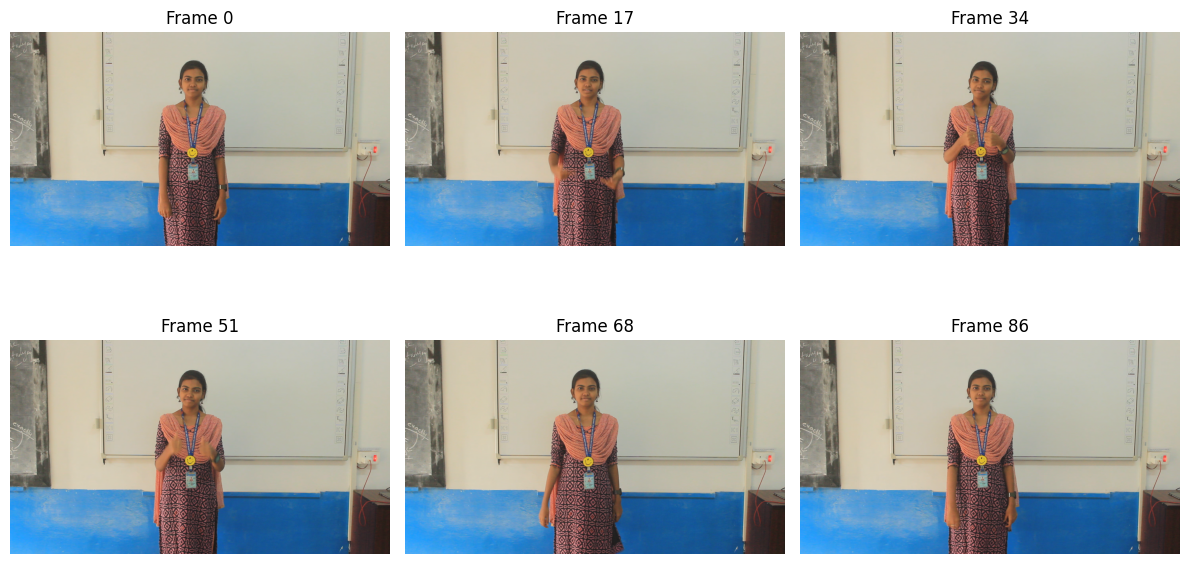

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

video_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "data/raw/Greetings_1of2/Greetings/50. Alright/MVI_0097.MOV"
)

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Could not open video.")
else:
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    positions = np.linspace(0, total_frames - 1, 6, dtype=int)

    fig, axes = plt.subplots(2, 3, figsize=(12, 7))

    for ax, frame_idx in zip(axes.flat, positions):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
        success, frame = cap.read()

        if success:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            ax.imshow(frame)
            ax.set_title(f"Frame {frame_idx}")
        else:
            ax.set_title(f"Frame {frame_idx}: failed")

        ax.axis("off")

    cap.release()
    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd

manifest_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "reports/landmark_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

result = manifest[
    manifest["video_path"].str.contains(
        "MVI_0097.MOV", case=False, na=False
    )
]

print(result[["video_path", "sequence_path", "status"]].to_string(index=False))

                                                                                          video_path                                                                                                        sequence_path  status
/content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/50. Alright/MVI_0097.MOV /content/drive/MyDrive/T240_Sign_Language/data/landmarks/Greetings_1of2_Greetings_50_Alright_50_Alright_MVI_0097.npy success


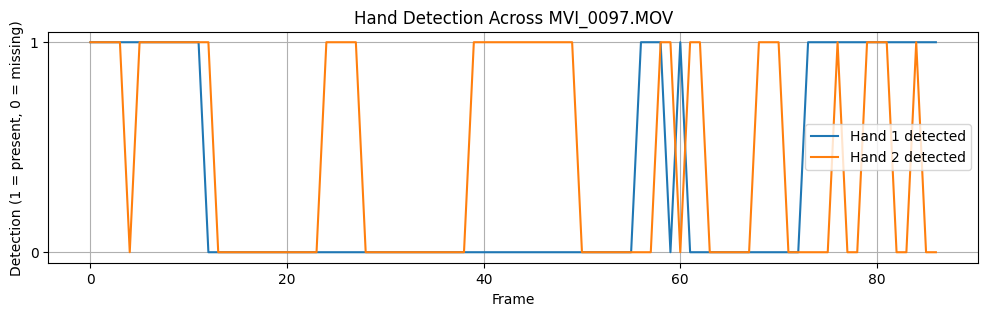

Sequence shape: (87, 126)
Hand 1 detection: 34.48%
Hand 2 detection: 44.83%
Both hands detected: 19.54%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

sequence_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "data/landmarks/"
    "Greetings_1of2_Greetings_50_Alright_50_Alright_MVI_0097.npy"
)

sequence = np.load(sequence_path)
data = sequence.reshape(len(sequence), 2, 21, 3)

hand1_detected = np.any(data[:, 0] != 0, axis=(1, 2))
hand2_detected = np.any(data[:, 1] != 0, axis=(1, 2))

plt.figure(figsize=(12, 3))
plt.plot(hand1_detected.astype(int), label="Hand 1 detected")
plt.plot(hand2_detected.astype(int), label="Hand 2 detected")
plt.xlabel("Frame")
plt.ylabel("Detection (1 = present, 0 = missing)")
plt.title("Hand Detection Across MVI_0097.MOV")
plt.yticks([0, 1])
plt.legend()
plt.grid(True)
plt.show()

print("Sequence shape:", sequence.shape)
print(f"Hand 1 detection: {hand1_detected.mean():.2%}")
print(f"Hand 2 detection: {hand2_detected.mean():.2%}")
print(f"Both hands detected: {(hand1_detected & hand2_detected).mean():.2%}")

In [ ]:
import os
import numpy as np
import pandas as pd

manifest_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "reports/landmark_manifest.csv"
)
manifest = pd.read_csv(manifest_path)

low_videos = [
    "MVI_0097.MOV",
    "MVI_0089.MOV",
    "MVI_0095.MOV",
    "MVI_0090.MOV",
    "MVI_0099.MOV",
]

for video_name in low_videos:
    row = manifest[
        manifest["video_path"].str.endswith(video_name)
    ].iloc[0]

    sequence = np.load(row["sequence_path"])
    data = sequence.reshape(len(sequence), 2, 21, 3)

    hand1 = np.any(data[:, 0] != 0, axis=(1, 2))
    hand2 = np.any(data[:, 1] != 0, axis=(1, 2))

    print(
        f"{video_name} | {row['label']} | "
        f"Hand 1: {hand1.mean():.1%} | "
        f"Hand 2: {hand2.mean():.1%} | "
        f"Both: {(hand1 & hand2).mean():.1%}"
    )

MVI_0097.MOV | 50. Alright | Hand 1: 34.5% | Hand 2: 44.8% | Both: 19.5%
MVI_0089.MOV | 48. Hello | Hand 1: 33.8% | Hand 2: 50.0% | Both: 23.5%
MVI_0095.MOV | 50. Alright | Hand 1: 19.0% | Hand 2: 52.4% | Both: 11.1%
MVI_0090.MOV | 48. Hello | Hand 1: 24.6% | Hand 2: 47.8% | Both: 10.1%
MVI_0099.MOV | 51. Good Morning | Hand 1: 16.7% | Hand 2: 62.1% | Both: 15.2%


In [ ]:
print("Current MediaPipe options:")
print(options)

print("\nHandLandmarkerOptions parameters:")
help(HandLandmarkerOptions)

Current MediaPipe options:
HandLandmarkerOptions(base_options=BaseOptions(model_asset_path='/content/drive/MyDrive/T240_Sign_Language/models/hand_landmarker.task', model_asset_buffer=None, delegate=None), running_mode=<VisionTaskRunningMode.IMAGE: 'IMAGE'>, num_hands=2, min_hand_detection_confidence=0.3, min_hand_presence_confidence=0.3, min_tracking_confidence=0.5, result_callback=None)

HandLandmarkerOptions parameters:
Help on class HandLandmarkerOptions in module mediapipe.tasks.python.vision.hand_landmarker:

class HandLandmarkerOptions(builtins.object)
 |  HandLandmarkerOptions(
 |      base_options: mediapipe.tasks.python.core.base_options.BaseOptions,
 |      running_mode: mediapipe.tasks.python.vision.core.vision_task_running_mode.VisionTaskRunningMode = <VisionTaskRunningMode.IMAGE: 'IMAGE'>,
 |      num_hands: int = 1,
 |      min_hand_detection_confidence: float = 0.5,
 |      min_hand_presence_confidence: float = 0.5,
 |      min_tracking_confidence: float = 0.5,
 |      r

In [ ]:
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

video_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "data/raw/Greetings_1of2/Greetings/50. Alright/MVI_0097.MOV"
)

model_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "models/hand_landmarker.task"
)

def measure_detection(threshold):
    options_test = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=model_path),
        running_mode=vision.RunningMode.IMAGE,
        num_hands=2,
        min_hand_detection_confidence=threshold,
        min_hand_presence_confidence=threshold,
        min_tracking_confidence=0.5,
    )

    cap = cv2.VideoCapture(video_path)
    total = detected = 0

    with vision.HandLandmarker.create_from_options(options_test) as detector:
        while True:
            ok, frame = cap.read()
            if not ok:
                break

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )
            result = detector.detect(mp_image)

            total += 1
            if result.hand_landmarks:
                detected += 1

    cap.release()
    return total, detected, detected / total * 100 if total else 0

for threshold in [0.3, 0.2]:
    total, detected, coverage = measure_detection(threshold)
    print(
        f"Threshold {threshold}: "
        f"{detected}/{total} frames detected ({coverage:.2f}%)"
    )

Threshold 0.3: 52/87 frames detected (59.77%)
Threshold 0.2: 53/87 frames detected (60.92%)


In [ ]:
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

video_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "data/raw/Greetings_1of2/Greetings/50. Alright/MVI_0097.MOV"
)
model_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "models/hand_landmarker.task"
)

options_video = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=model_path),
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2,
    min_hand_detection_confidence=0.3,
    min_hand_presence_confidence=0.3,
    min_tracking_confidence=0.5,
)

cap = cv2.VideoCapture(video_path)
total = detected = 0
fps = cap.get(cv2.CAP_PROP_FPS)

with vision.HandLandmarker.create_from_options(options_video) as detector:
    while True:
        ok, frame = cap.read()
        if not ok:
            break

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        timestamp_ms = round(total * 1000 / fps) if fps > 0 else total * 40
        result = detector.detect_for_video(mp_image, timestamp_ms)

        total += 1
        if result.hand_landmarks:
            detected += 1

cap.release()

print(f"VIDEO mode: {detected}/{total} frames detected")
print(f"Detection coverage: {detected / total * 100:.2f}%")
print("IMAGE mode baseline: 52/87 frames (59.77%)")

VIDEO mode: 64/87 frames detected
Detection coverage: 73.56%
IMAGE mode baseline: 52/87 frames (59.77%)


In [ ]:
import pandas as pd
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
manifest = pd.read_csv(f"{BASE_DIR}/reports/landmark_manifest.csv")
model_path = f"{BASE_DIR}/models/hand_landmarker.task"

target_videos = [
    "MVI_0097.MOV",
    "MVI_0089.MOV",
    "MVI_0095.MOV",
    "MVI_0090.MOV",
    "MVI_0099.MOV",
]

def test_mode(video_path, mode):
    options = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=model_path),
        running_mode=mode,
        num_hands=2,
        min_hand_detection_confidence=0.3,
        min_hand_presence_confidence=0.3,
        min_tracking_confidence=0.5,
    )

    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    total = detected = 0

    with vision.HandLandmarker.create_from_options(options) as detector:
        while True:
            ok, frame = cap.read()
            if not ok:
                break

            image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=cv2.cvtColor(frame, cv2.COLOR_BGR2RGB),
            )

            if mode == vision.RunningMode.VIDEO:
                timestamp = round(total * 1000 / fps) if fps > 0 else total * 40
                result = detector.detect_for_video(image, timestamp)
            else:
                result = detector.detect(image)

            total += 1
            if result.hand_landmarks:
                detected += 1

    cap.release()
    return total, detected, 100 * detected / total if total else 0

for filename in target_videos:
    rows = manifest[manifest["video_path"].str.endswith(filename, na=False)]
    if rows.empty:
        print(f"\n{filename}: not found in manifest")
        continue

    video_path = rows.iloc[0]["video_path"]
    print(f"\n{filename}")

    for mode in [vision.RunningMode.IMAGE, vision.RunningMode.VIDEO]:
        total, detected, coverage = test_mode(video_path, mode)
        print(f"{mode.name}: {detected}/{total} frames ({coverage:.2f}%)")


MVI_0097.MOV
IMAGE: 52/87 frames (59.77%)
VIDEO: 64/87 frames (73.56%)

MVI_0089.MOV
IMAGE: 41/68 frames (60.29%)
VIDEO: 68/68 frames (100.00%)

MVI_0095.MOV
IMAGE: 38/63 frames (60.32%)
VIDEO: 44/63 frames (69.84%)

MVI_0090.MOV
IMAGE: 43/69 frames (62.32%)
VIDEO: 69/69 frames (100.00%)

MVI_0099.MOV
IMAGE: 42/66 frames (63.64%)
VIDEO: 66/66 frames (100.00%)


In [ ]:
import os
import shutil
from datetime import datetime

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"

# New folder for VIDEO-mode landmark sequences
VIDEO_LANDMARK_DIR = os.path.join(
    BASE_DIR, "data", "landmarks_video_mode"
)
os.makedirs(VIDEO_LANDMARK_DIR, exist_ok=True)

# Back up the existing manifest
manifest_path = os.path.join(
    BASE_DIR, "reports", "landmark_manifest.csv"
)

backup_path = os.path.join(
    BASE_DIR,
    "reports",
    f"landmark_manifest_backup_before_video_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv"
)

shutil.copy2(manifest_path, backup_path)

print("VIDEO-mode folder ready:", VIDEO_LANDMARK_DIR)
print("Existing manifest backed up:", backup_path)
print("Existing landmarks remain unchanged.")

VIDEO-mode folder ready: /content/drive/MyDrive/T240_Sign_Language/data/landmarks_video_mode
Existing manifest backed up: /content/drive/MyDrive/T240_Sign_Language/reports/landmark_manifest_backup_before_video_20261028_063346.csv
Existing landmarks remain unchanged.


In [ ]:
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
df = pd.read_csv(f"{BASE_DIR}/reports/landmark_manifest.csv")

video_path = df.iloc[0]["video_path"]
model_path = f"{BASE_DIR}/models/hand_landmarker.task"

options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=model_path),
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2,
    min_hand_detection_confidence=0.3,
    min_hand_presence_confidence=0.3,
    min_tracking_confidence=0.5,
)

cap = cv2.VideoCapture(video_path)
frame_index = 0

try:
    with vision.HandLandmarker.create_from_options(options) as detector:
        while True:
            ok, frame = cap.read()
            if not ok:
                break

            image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=cv2.cvtColor(frame, cv2.COLOR_BGR2RGB),
            )

            timestamp_ms = frame_index  # 0, 1, 2, 3, ... strictly increasing
            result = detector.detect_for_video(image, timestamp_ms)
            frame_index += 1

    print("SUCCESS:", video_path.split("/")[-1])
    print("Frames processed:", frame_index)

except Exception as e:
    print("ERROR:", repr(e))
    print("Frame index at failure:", frame_index)

finally:
    cap.release()

SUCCESS: MVI_0029.MOV
Frames processed: 63


In [ ]:

import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_PATH = f"{BASE_DIR}/models/hand_landmarker.task"

df = pd.read_csv(
    f"{BASE_DIR}/reports/landmark_manifest.csv"
)

for video_path in df["video_path"].head(2):
    cap = cv2.VideoCapture(video_path)
    frame_index = 0
    detected = 0

    options = vision.HandLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=MODEL_PATH
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.3,
        min_hand_presence_confidence=0.3,
        min_tracking_confidence=0.5,
    )

    try:
        with vision.HandLandmarker.create_from_options(options) as detector:
            while True:
                ok, frame = cap.read()
                if not ok:
                    break

                image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                )

                result = detector.detect_for_video(image, frame_index)

                if result.hand_landmarks:
                    detected += 1

                frame_index += 1

        print(
            f"{video_path.split('/')[-1]}: "
            f"SUCCESS | {detected}/{frame_index} frames detected"
        )

    except Exception as e:
        print(f"{video_path.split('/')[-1]}: ERROR | {e}")

    finally:
        cap.release()


MVI_0029.MOV: SUCCESS | 63/63 frames detected
MVI_0030.MOV: SUCCESS | 74/74 frames detected


In [3]:
import os

POSE_MODEL = "/content/drive/MyDrive/T240_Sign_Language/models/pose_landmarker_lite.task"

os.makedirs(os.path.dirname(POSE_MODEL), exist_ok=True)

if not os.path.exists(POSE_MODEL):
    !wget -q -O "{POSE_MODEL}" "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task"

print("Pose model exists:", os.path.exists(POSE_MODEL))
if os.path.exists(POSE_MODEL):
    print("Pose model size:", round(os.path.getsize(POSE_MODEL) / (1024 * 1024), 2), "MB")

Pose model exists: True
Pose model size: 5.51 MB


In [ ]:

import os
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from tqdm.auto import tqdm

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
SOURCE_MANIFEST = f"{BASE_DIR}/reports/landmark_manifest.csv"
OUTPUT_DIR = f"{BASE_DIR}/data/landmarks_video_mode"
OUTPUT_MANIFEST = f"{BASE_DIR}/reports/landmark_manifest_video_mode.csv"
MODEL_PATH = f"{BASE_DIR}/models/hand_landmarker.task"

os.makedirs(OUTPUT_DIR, exist_ok=True)
df = pd.read_csv(SOURCE_MANIFEST)
results = []

for _, row in tqdm(df.iterrows(), total=len(df), desc="VIDEO-mode extraction"):
    video_path = row["video_path"]
    cap = cv2.VideoCapture(video_path)
    sequence = []
    detected = 0
    frame_index = 0
    status = "success"
    error_message = ""
    output_path = ""

    try:
        if not cap.isOpened():
            raise RuntimeError("Could not open video")

        # IMPORTANT: new detector for every video
        options = vision.HandLandmarkerOptions(
            base_options=python.BaseOptions(
                model_asset_path=MODEL_PATH
            ),
            running_mode=vision.RunningMode.VIDEO,
            num_hands=2,
            min_hand_detection_confidence=0.3,
            min_hand_presence_confidence=0.3,
            min_tracking_confidence=0.5,
        )

        with vision.HandLandmarker.create_from_options(options) as detector:
            while True:
                ok, frame = cap.read()
                if not ok:
                    break

                image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=cv2.cvtColor(frame, cv2.COLOR_BGR2RGB),
                )

                result = detector.detect_for_video(image, frame_index)

                features = np.zeros((2, 21, 3), dtype=np.float32)

                if result.hand_landmarks:
                    detected += 1
                    for hand_idx, landmarks in enumerate(
                        result.hand_landmarks[:2]
                    ):
                        for point_idx, landmark in enumerate(landmarks):
                            features[hand_idx, point_idx] = [
                                landmark.x, landmark.y, landmark.z
                            ]

                sequence.append(features.reshape(126))
                frame_index += 1

        if frame_index == 0:
            raise RuntimeError("No frames read")

        relative_path = os.path.relpath(
            video_path, f"{BASE_DIR}/data/raw"
        )
        safe_name = (
            relative_path.replace(os.sep, "_")
            .replace(" ", "_")
            .replace(".MOV", "")
            .replace(".mov", "")
        )
        output_path = os.path.join(OUTPUT_DIR, safe_name + ".npy")

        np.save(output_path, np.asarray(sequence, dtype=np.float32))

    except Exception as e:
        status = "error"
        error_message = repr(e)

    finally:
        cap.release()

    results.append({
        **row.to_dict(),
        "sequence_path": output_path,
        "frames": frame_index,
        "frames_with_hands": detected,
        "status": status,
        "error_message": error_message,
    })

    # Save progress after every video so results aren't lost
    pd.DataFrame(results).to_csv(OUTPUT_MANIFEST, index=False)

video_manifest = pd.DataFrame(results)
total_frames = video_manifest["frames"].sum()
detected_frames = video_manifest["frames_with_hands"].sum()

print("\nExtraction complete.")
print("Total videos:", len(video_manifest))
print("\nStatus counts:")
print(video_manifest["status"].value_counts(dropna=False))
print("Total frames:", total_frames)
print("Frames with hands:", detected_frames)

if total_frames:
    print(f"Detection coverage: {detected_frames / total_frames * 100:.2f}%")

print("\nManifest:", OUTPUT_MANIFEST)
print("Landmarks:", OUTPUT_DIR)


VIDEO-mode extraction:   0%|          | 0/190 [00:00<?, ?it/s]


Extraction complete.
Total videos: 190

Status counts:
status
success    190
Name: count, dtype: int64
Total frames: 12884
Frames with hands: 12331
Detection coverage: 95.71%

Manifest: /content/drive/MyDrive/T240_Sign_Language/reports/landmark_manifest_video_mode.csv
Landmarks: /content/drive/MyDrive/T240_Sign_Language/data/landmarks_video_mode


In [ ]:

import os
import numpy as np
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
manifest_path = f"{BASE_DIR}/reports/landmark_manifest_video_mode.csv"

df = pd.read_csv(manifest_path)

valid = 0
missing = []
invalid = []
total_frames = 0

for _, row in df.iterrows():
    path = row["sequence_path"]

    if row["status"] != "success" or not isinstance(path, str) or not os.path.isfile(path):
        missing.append(row["video_path"])
        continue

    sequence = np.load(path, allow_pickle=False)

    if sequence.ndim != 2 or sequence.shape[1] != 126:
        invalid.append((path, sequence.shape, "unexpected shape"))
    elif not np.isfinite(sequence).all():
        invalid.append((path, sequence.shape, "non-finite values"))
    else:
        valid += 1
        total_frames += sequence.shape[0]

print("Manifest rows:", len(df))
print("Valid sequences:", valid)
print("Missing or failed files:", len(missing))
print("Invalid sequences:", len(invalid))
print("Total saved frames:", total_frames)

if missing:
    print("\nFirst missing entries:", missing[:3])
if invalid:
    print("\nFirst invalid entries:", invalid[:3])


Manifest rows: 190
Valid sequences: 190
Missing or failed files: 0
Invalid sequences: 0
Total saved frames: 12884


In [ ]:

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
MANIFEST_PATH = f"{BASE_DIR}/reports/landmark_manifest_video_mode.csv"
OUTPUT_PATH = f"{BASE_DIR}/reports/video_mode_dataset.npz"
ENCODER_PATH = f"{BASE_DIR}/models/label_encoder_video_mode.pkl"

SEQUENCE_LENGTH = 60
FEATURES = 126

df = pd.read_csv(MANIFEST_PATH)
df = df[df["status"] == "success"].copy()

def resample_sequence(sequence, target_length=60):
    if len(sequence) == 0:
        raise ValueError("Empty sequence")

    old_positions = np.linspace(0, 1, num=len(sequence))
    new_positions = np.linspace(0, 1, num=target_length)

    resampled = np.zeros((target_length, sequence.shape[1]), dtype=np.float32)

    for feature_idx in range(sequence.shape[1]):
        resampled[:, feature_idx] = np.interp(
            new_positions,
            old_positions,
            sequence[:, feature_idx]
        )

    return resampled

X_list = []
labels = []

for _, row in df.iterrows():
    sequence = np.load(row["sequence_path"], allow_pickle=False)

    if sequence.ndim != 2 or sequence.shape[1] != FEATURES:
        raise ValueError(f"Unexpected shape for {row['sequence_path']}: {sequence.shape}")

    X_list.append(resample_sequence(sequence, SEQUENCE_LENGTH))
    labels.append(row["label"])

X = np.asarray(X_list, dtype=np.float32)

# Encode labels
encoder = LabelEncoder()
y = encoder.fit_transform(labels)

# Split identically to the earlier experiments
indices = np.arange(len(y))
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train = X[train_idx]
X_val = X[val_idx]
y_train = y[train_idx]
y_val = y[val_idx]

# Normalize each hand relative to its wrist.
# Keep the two hands separate; each has 63 features.
def normalize_hands(data):
    data = data.copy().reshape(-1, SEQUENCE_LENGTH, 2, 21, 3)

    for hand_idx in range(2):
        hand = data[:, :, hand_idx, :, :]
        wrist = hand[:, :, 0:1, :].copy()

        # Only normalize frames where this hand has landmarks.
        valid = np.any(hand != 0, axis=(2, 3))

        normalized = hand - wrist
        normalized = np.clip(normalized, -1, 1)

        # Preserve fully missing frames as zeros.
        normalized[~valid] = 0
        data[:, :, hand_idx, :, :] = normalized

    return data.reshape(-1, SEQUENCE_LENGTH, FEATURES)

X_train_norm = normalize_hands(X_train)
X_val_norm = normalize_hands(X_val)

assert X_train_norm.shape == (152, 60, 126)
assert X_val_norm.shape == (38, 60, 126)
assert np.isfinite(X_train_norm).all()
assert np.isfinite(X_val_norm).all()

# Save the prepared arrays and encoder separately.
np.savez_compressed(
    OUTPUT_PATH,
    X_train_norm=X_train_norm,
    X_val_norm=X_val_norm,
    y_train=y_train,
    y_val=y_val,
    classes=encoder.classes_
)

import pickle
with open(ENCODER_PATH, "wb") as f:
    pickle.dump(encoder, f)

print("Dataset preparation complete.")
print("X_train_norm:", X_train_norm.shape)
print("X_val_norm:", X_val_norm.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("Classes:", list(encoder.classes_))
print("All values finite:", np.isfinite(X_train_norm).all() and np.isfinite(X_val_norm).all())
print("Saved dataset:", OUTPUT_PATH)
print("Saved label encoder:", ENCODER_PATH)


Dataset preparation complete.
X_train_norm: (152, 60, 126)
X_val_norm: (38, 60, 126)
y_train: (152,)
y_val: (38,)
Classes: [np.str_('48. Hello'), np.str_('49. How are you'), np.str_('50. Alright'), np.str_('51. Good Morning'), np.str_('52. Good afternoon'), np.str_('53. Good evening'), np.str_('54. Good night'), np.str_('55. Thank you'), np.str_('56. Pleased')]
All values finite: True
Saved dataset: /content/drive/MyDrive/T240_Sign_Language/reports/video_mode_dataset.npz
Saved label encoder: /content/drive/MyDrive/T240_Sign_Language/models/label_encoder_video_mode.pkl


In [ ]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = f"{BASE_DIR}/reports/video_mode_dataset.npz"
CHECKPOINT_PATH = f"{BASE_DIR}/models/best_sign_language_lstm_video_mode.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

data = np.load(DATA_PATH)
X_train = data["X_train_norm"].astype(np.float32)
X_val = data["X_val_norm"].astype(np.float32)
y_train = data["y_train"].astype(np.int64)
y_val = data["y_val"].astype(np.int64)

class SignLanguageLSTM(nn.Module):
    def __init__(self, input_size=126, hidden_size=64, num_classes=9):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        features = self.dropout(hidden[-1])
        return self.fc(features)

train_ds = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train)
)
val_ds = TensorDataset(
    torch.from_numpy(X_val),
    torch.from_numpy(y_val)
)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False)

model = SignLanguageLSTM().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 60
best_val_f1 = -1.0

for epoch in range(EPOCHS):
    model.train()
    train_preds, train_targets = [], []
    train_loss_total = 0.0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * len(yb)
        train_preds.extend(logits.argmax(1).detach().cpu().numpy())
        train_targets.extend(yb.cpu().numpy())

    model.eval()
    val_preds, val_targets = [], []
    val_loss_total = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)

            val_loss_total += loss.item() * len(yb)
            val_preds.extend(logits.argmax(1).cpu().numpy())
            val_targets.extend(yb.cpu().numpy())

    train_acc = accuracy_score(train_targets, train_preds)
    val_acc = accuracy_score(val_targets, val_preds)
    val_f1 = f1_score(
        val_targets, val_preds, average="macro", zero_division=0
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), CHECKPOINT_PATH)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss_total/len(train_ds):.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss_total/len(val_ds):.4f} | "
        f"Val Acc: {val_acc:.2%} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

print("\nTraining complete.")
print("Best checkpoint:", CHECKPOINT_PATH)
print("Best validation Macro F1:", round(best_val_f1, 4))


Device: cpu
Epoch [01/60] Train Loss: 2.2004 | Train Acc: 8.55% | Val Loss: 2.1940 | Val Acc: 13.16% | Val Macro F1: 0.0258
Epoch [02/60] Train Loss: 2.2023 | Train Acc: 11.18% | Val Loss: 2.1931 | Val Acc: 13.16% | Val Macro F1: 0.0258
Epoch [03/60] Train Loss: 2.1947 | Train Acc: 9.87% | Val Loss: 2.1925 | Val Acc: 15.79% | Val Macro F1: 0.0635
Epoch [04/60] Train Loss: 2.1934 | Train Acc: 11.18% | Val Loss: 2.1916 | Val Acc: 15.79% | Val Macro F1: 0.0655
Epoch [05/60] Train Loss: 2.1929 | Train Acc: 13.16% | Val Loss: 2.1902 | Val Acc: 15.79% | Val Macro F1: 0.0641
Epoch [06/60] Train Loss: 2.1883 | Train Acc: 13.16% | Val Loss: 2.1864 | Val Acc: 21.05% | Val Macro F1: 0.1173
Epoch [07/60] Train Loss: 2.1792 | Train Acc: 14.47% | Val Loss: 2.1725 | Val Acc: 18.42% | Val Macro F1: 0.0737
Epoch [08/60] Train Loss: 2.1176 | Train Acc: 17.11% | Val Loss: 1.9855 | Val Acc: 23.68% | Val Macro F1: 0.0879
Epoch [09/60] Train Loss: 1.9101 | Train Acc: 23.03% | Val Loss: 1.8526 | Val Acc: 23.

In [ ]:

import numpy as np

path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "reports/video_mode_dataset.npz"
)

data = np.load(path)

for split in ["X_train_norm", "X_val_norm"]:
    X = data[split].reshape(-1, 60, 2, 21, 3)

    print(f"\n{split}")

    for hand in range(2):
        hand_data = X[:, :, hand, :, :]

        # A frame is counted as missing if all landmark coordinates are zero.
        missing = np.all(hand_data == 0, axis=(2, 3))

        print(
            f"Hand {hand + 1} missing frames: "
            f"{missing.sum()}/{missing.size} "
            f"({missing.mean() * 100:.2f}%)"
        )

    all_missing = np.all(X == 0, axis=(2, 3, 4))
    print(
        f"Both hands missing: {all_missing.sum()}/{all_missing.size} "
        f"({all_missing.mean() * 100:.2f}%)"
    )



X_train_norm
Hand 1 missing frames: 265/9120 (2.91%)
Hand 2 missing frames: 1812/9120 (19.87%)
Both hands missing: 265/9120 (2.91%)

X_val_norm
Hand 1 missing frames: 70/2280 (3.07%)
Hand 2 missing frames: 440/2280 (19.30%)
Both hands missing: 70/2280 (3.07%)


In [ ]:

import numpy as np

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language/reports"

files = {
    "VIDEO mode": f"{BASE_DIR}/video_mode_dataset.npz",
    "Nearest-fill backup": f"{BASE_DIR}/nearestfill_dataset_backup_20261027.npz",
}

for name, path in files.items():
    print(f"\n--- {name} ---")

    try:
        data = np.load(path)

        for key in ["X_train_norm", "X_val_norm"]:
            if key not in data:
                print(f"{key}: not found")
                continue

            X = data[key]
            print(
                f"{key}: shape={X.shape}, "
                f"min={X.min():.4f}, max={X.max():.4f}, "
                f"mean={X.mean():.4f}, std={X.std():.4f}"
            )

    except Exception as e:
        print("Could not read dataset:", repr(e))



--- VIDEO mode ---
X_train_norm: shape=(152, 60, 126), min=-0.1773, max=0.1408, mean=0.0054, std=0.0386
X_val_norm: shape=(38, 60, 126), min=-0.1762, max=0.1242, mean=0.0054, std=0.0371

--- Nearest-fill backup ---
X_train_norm: shape=(152, 60, 126), min=-1.0000, max=1.0000, mean=0.0704, std=0.4215
X_val_norm: shape=(38, 60, 126), min=-1.0000, max=1.0000, mean=0.0705, std=0.4229


In [ ]:

import numpy as np

path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "reports/nearestfill_dataset_backup_20261027.npz"
)

data = np.load(path)

for key in ["X_train_norm", "X_val_norm"]:
    X = data[key]

    print(f"\n{key}")
    print("Shape:", X.shape)
    print("Percentiles:", np.percentile(X, [0, 1, 25, 50, 75, 99, 100]))
    print("Exact zeros:", np.mean(X == 0) * 100, "%")
    print("Finite:", np.isfinite(X).all())



X_train_norm
Shape: (152, 60, 126)
Percentiles: [-1.         -0.94036955 -0.12168973 -0.00718278  0.19841189  1.
  1.        ]
Exact zeros: 4.7619917850181 %
Finite: True

X_val_norm
Shape: (38, 60, 126)
Percentiles: [-1.         -0.94680716 -0.12169874 -0.00488267  0.19472285  1.
  1.        ]
Exact zeros: 4.761904761904762 %
Finite: True


In [ ]:

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
REPORT_DIR = os.path.join(BASE_DIR, "reports")

manifest_path = os.path.join(
    REPORT_DIR, "landmark_manifest_video_mode.csv"
)
output_path = os.path.join(
    REPORT_DIR, "video_mode_nearestfill_dataset.npz"
)
encoder_path = os.path.join(
    BASE_DIR, "models", "label_encoder_video_mode_nearestfill.pkl"
)

df = pd.read_csv(manifest_path)
df = df[df["status"] == "success"].reset_index(drop=True)

def fill_nearest_hand_frames(sequence):
    sequence = sequence.copy().reshape(-1, 2, 21, 3)

    for hand_idx in range(2):
        hand = sequence[:, hand_idx, :, :]
        valid = np.any(hand != 0, axis=(1, 2))
        valid_indices = np.where(valid)[0]

        if len(valid_indices) == 0:
            continue

        missing_indices = np.where(~valid)[0]

        for idx in missing_indices:
            nearest = valid_indices[
                np.argmin(np.abs(valid_indices - idx))
            ]
            hand[idx] = hand[nearest]

        sequence[:, hand_idx, :, :] = hand

    return sequence.reshape(-1, 126)

def resample_sequence(sequence, target_length=60):
    old_length = len(sequence)

    if old_length == target_length:
        return sequence.astype(np.float32)

    old_positions = np.linspace(0, 1, old_length)
    new_positions = np.linspace(0, 1, target_length)

    resampled = np.stack([
        np.interp(
            new_positions,
            old_positions,
            sequence[:, feature_idx]
        )
        for feature_idx in range(sequence.shape[1])
    ], axis=1)

    return resampled.astype(np.float32)

def normalize_hands(data):
    data = data.copy().reshape(-1, 60, 2, 21, 3)

    for hand_idx in range(2):
        hand = data[:, :, hand_idx, :, :]
        wrist = hand[:, :, 0:1, :].copy()
        valid = np.any(hand != 0, axis=(2, 3))

        normalized = hand - wrist
        normalized = np.clip(normalized, -1, 1)
        normalized[~valid] = 0

        data[:, :, hand_idx, :, :] = normalized

    return data.reshape(-1, 60, 126).astype(np.float32)

# Load, fill, and resample every video
X_list = []
labels = []

for _, row in df.iterrows():
    sequence = np.load(row["sequence_path"]).astype(np.float32)

    if sequence.ndim != 2 or sequence.shape[1] != 126:
        raise ValueError(
            f"Unexpected sequence shape: {row['sequence_path']} "
            f"{sequence.shape}"
        )

    sequence = fill_nearest_hand_frames(sequence)
    sequence = resample_sequence(sequence, 60)

    X_list.append(sequence)
    labels.append(row["label"])

X = np.stack(X_list)
labels = np.asarray(labels)

encoder = LabelEncoder()
y = encoder.fit_transform(labels)

indices = np.arange(len(y))
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train = normalize_hands(X[train_idx])
X_val = normalize_hands(X[val_idx])

y_train = y[train_idx]
y_val = y[val_idx]

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()

np.savez_compressed(
    output_path,
    X_train_norm=X_train,
    X_val_norm=X_val,
    y_train=y_train,
    y_val=y_val,
    classes=encoder.classes_
)

import pickle
with open(encoder_path, "wb") as f:
    pickle.dump(encoder, f)

print("Dataset rebuilt successfully.")
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Classes:", encoder.classes_)
print("Train range:", X_train.min(), X_train.max())
print("Train std:", X_train.std())
print("Validation range:", X_val.min(), X_val.max())
print("Validation std:", X_val.std())
print("Saved:", output_path)


Dataset rebuilt successfully.
Train: (152, 60, 126) (152,)
Validation: (38, 60, 126) (38,)
Classes: ['48. Hello' '49. How are you' '50. Alright' '51. Good Morning'
 '52. Good afternoon' '53. Good evening' '54. Good night' '55. Thank you'
 '56. Pleased']
Train range: -0.17733556 0.14076358
Train std: 0.041519437
Validation range: -0.17617337 0.12824988
Validation std: 0.040051516
Saved: /content/drive/MyDrive/T240_Sign_Language/reports/video_mode_nearestfill_dataset.npz


In [ ]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = os.path.join(
    BASE_DIR, "reports", "video_mode_nearestfill_dataset.npz"
)
CHECKPOINT_PATH = os.path.join(
    BASE_DIR, "models",
    "best_sign_language_lstm_video_nearestfill.pth"
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

data = np.load(DATA_PATH)
X_train = torch.tensor(data["X_train_norm"], dtype=torch.float32)
X_val = torch.tensor(data["X_val_norm"], dtype=torch.float32)
y_train = torch.tensor(data["y_train"], dtype=torch.long)
y_val = torch.tensor(data["y_val"], dtype=torch.long)

class SignLanguageLSTM(nn.Module):
    def __init__(self, input_size=126, hidden_size=64, num_classes=9):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        return self.fc(self.dropout(hidden[-1]))

model = SignLanguageLSTM(num_classes=len(data["classes"])).to(device)

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=16,
    shuffle=True
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

best_val_acc = 0.0
best_macro_f1 = 0.0

for epoch in range(60):
    model.train()
    train_correct = 0
    train_total = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()

        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_correct += (logits.argmax(1) == yb).sum().item()
        train_total += len(yb)

    model.eval()
    with torch.no_grad():
        logits = model(X_val.to(device))
        predictions = logits.argmax(1).cpu().numpy()

    val_acc = accuracy_score(y_val.numpy(), predictions)
    macro_f1 = f1_score(
        y_val.numpy(), predictions,
        average="macro", zero_division=0
    )

    if val_acc > best_val_acc or (
        val_acc == best_val_acc and macro_f1 > best_macro_f1
    ):
        best_val_acc = val_acc
        best_macro_f1 = macro_f1
        torch.save(model.state_dict(), CHECKPOINT_PATH)

    print(
        f"Epoch [{epoch+1:02d}/60] "
        f"Train Acc: {100*train_correct/train_total:.2f}% | "
        f"Val Acc: {100*val_acc:.2f}% | "
        f"Macro F1: {macro_f1:.4f}"
    )

print("\nTraining complete.")
print(f"Best validation accuracy: {best_val_acc*100:.2f}%")
print(f"Best macro F1: {best_macro_f1:.4f}")
print("Checkpoint:", CHECKPOINT_PATH)


Device: cpu
Epoch [01/60] Train Acc: 8.55% | Val Acc: 13.16% | Macro F1: 0.0258
Epoch [02/60] Train Acc: 10.53% | Val Acc: 13.16% | Macro F1: 0.0258
Epoch [03/60] Train Acc: 12.50% | Val Acc: 13.16% | Macro F1: 0.0258
Epoch [04/60] Train Acc: 11.18% | Val Acc: 15.79% | Macro F1: 0.0635
Epoch [05/60] Train Acc: 13.82% | Val Acc: 15.79% | Macro F1: 0.0679
Epoch [06/60] Train Acc: 15.79% | Val Acc: 13.16% | Macro F1: 0.0545
Epoch [07/60] Train Acc: 16.45% | Val Acc: 18.42% | Macro F1: 0.0853
Epoch [08/60] Train Acc: 21.05% | Val Acc: 15.79% | Macro F1: 0.0639
Epoch [09/60] Train Acc: 22.37% | Val Acc: 15.79% | Macro F1: 0.0659
Epoch [10/60] Train Acc: 16.45% | Val Acc: 18.42% | Macro F1: 0.0724
Epoch [11/60] Train Acc: 17.76% | Val Acc: 15.79% | Macro F1: 0.0648
Epoch [12/60] Train Acc: 26.32% | Val Acc: 26.32% | Macro F1: 0.1350
Epoch [13/60] Train Acc: 27.63% | Val Acc: 23.68% | Macro F1: 0.0893
Epoch [14/60] Train Acc: 21.71% | Val Acc: 26.32% | Macro F1: 0.1350
Epoch [15/60] Train Acc

In [ ]:

import numpy as np

BASE = "/content/drive/MyDrive/T240_Sign_Language/reports"

old = np.load(
    f"{BASE}/nearestfill_dataset_backup_20261027.npz"
)
new = np.load(
    f"{BASE}/video_mode_nearestfill_dataset.npz"
)

for split in ["X_train_norm", "X_val_norm"]:
    A = old[split]
    B = new[split]

    print(f"\n--- {split} ---")
    print("Same shape:", A.shape == B.shape)
    print("Mean absolute difference:", np.mean(np.abs(A - B)))
    print("Maximum absolute difference:", np.max(np.abs(A - B)))
    print("Old std:", A.std())
    print("New std:", B.std())

for split in ["y_train", "y_val"]:
    print(f"\n{split} identical:", np.array_equal(old[split], new[split]))



--- X_train_norm ---
Same shape: True
Mean absolute difference: 0.26774845
Maximum absolute difference: 1.1407409
Old std: 0.42151982
New std: 0.041519437

--- X_val_norm ---
Same shape: True
Mean absolute difference: 0.26885378
Maximum absolute difference: 1.1207737
Old std: 0.4229282
New std: 0.040051516

y_train identical: True

y_val identical: True


In [ ]:

import numpy as np

path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "reports/nearestfill_dataset_backup_20261027.npz"
)

data = np.load(path)
X = data["X_train_norm"].reshape(-1, 60, 2, 21, 3)

for sample_idx in [0, 1, 2]:
    print(f"\nSample {sample_idx}")

    for hand_idx in range(2):
        hand = X[sample_idx, :, hand_idx, :, :]

        print(f"Hand {hand_idx + 1}")
        print("First frame, wrist:", hand[0, 0])
        print("First frame, landmark 5:", hand[0, 5])
        print("First 5 frame wrist Y:", hand[:5, 0, 1])
        print("Coordinate std:", hand.std())



Sample 0
Hand 1
First frame, wrist: [0. 0. 0.]
First frame, landmark 5: [0.04826084 0.6970831  0.06015373]
First 5 frame wrist Y: [0. 0. 0. 0. 0.]
Coordinate std: 0.3740254
Hand 2
First frame, wrist: [0. 0. 0.]
First frame, landmark 5: [0.12633362 0.6948404  0.05644266]
First 5 frame wrist Y: [0. 0. 0. 0. 0.]
Coordinate std: 0.42046946

Sample 1
Hand 1
First frame, wrist: [0. 0. 0.]
First frame, landmark 5: [-0.03110636  0.7292944  -0.05409309]
First 5 frame wrist Y: [0. 0. 0. 0. 0.]
Coordinate std: 0.4314283
Hand 2
First frame, wrist: [0. 0. 0.]
First frame, landmark 5: [ 0.00360059  0.5751563  -0.20239192]
First 5 frame wrist Y: [0. 0. 0. 0. 0.]
Coordinate std: 0.42629302

Sample 2
Hand 1
First frame, wrist: [0. 0. 0.]
First frame, landmark 5: [-0.05125963  0.5772117  -0.06404561]
First 5 frame wrist Y: [0. 0. 0. 0. 0.]
Coordinate std: 0.42058697
Hand 2
First frame, wrist: [0. 0. 0.]
First frame, landmark 5: [ 0.13322806  0.6022273  -0.01682713]
First 5 frame wrist Y: [0. 0. 0. 0. 0

In [ ]:

import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/T240_Sign_Language"

manifest = pd.read_csv(
    f"{BASE}/reports/landmark_manifest_video_mode.csv"
)

row = manifest[manifest["status"] == "success"].iloc[0]
raw = np.load(row["sequence_path"]).reshape(-1, 2, 21, 3)

print("Video:", row["video_path"])
print("Label:", row["label"])
print("Raw shape:", raw.shape)

for hand_idx in range(2):
    hand = raw[:, hand_idx]
    valid_frames = np.any(hand != 0, axis=(1, 2))

    print(f"\nHand {hand_idx + 1}")
    print("Detected frames:", valid_frames.sum(), "/", len(raw))
    print("Raw coordinate min:", hand.min())
    print("Raw coordinate max:", hand.max())
    print("Raw coordinate std:", hand.std())
    print("First detected wrist:", hand[np.where(valid_frames)[0][0], 0])
    print("First detected landmark 5:", hand[np.where(valid_frames)[0][0], 5])


Video: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/48. Hello/MVI_0029.MOV
Label: 48. Hello
Raw shape: (63, 2, 21, 3)

Hand 1
Detected frames: 63 / 63
Raw coordinate min: -0.017027432
Raw coordinate max: 0.8570643
Raw coordinate std: 0.34771731
First detected wrist: [5.9474927e-01 7.4515808e-01 1.2682125e-07]
First detected landmark 5: [ 0.5941716   0.8137787  -0.00221675]

Hand 2
Detected frames: 54 / 63
Raw coordinate min: -0.028640863
Raw coordinate max: 0.86543757
Raw coordinate std: 0.29378158
First detected wrist: [ 4.062009e-01  7.417849e-01 -6.456919e-08]
First detected landmark 5: [ 0.40887994  0.8014428  -0.01419728]


In [ ]:

import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/T240_Sign_Language"

# Load old preprocessed data and video-mode raw landmarks
old_data = np.load(
    f"{BASE}/reports/nearestfill_dataset_backup_20261027.npz"
)
manifest = pd.read_csv(
    f"{BASE}/reports/landmark_manifest_video_mode.csv"
)

row = manifest[
    manifest["video_path"].str.contains("MVI_0029.MOV", regex=False)
].iloc[0]

raw = np.load(row["sequence_path"]).reshape(-1, 2, 21, 3)
old = old_data["X_train_norm"].reshape(-1, 60, 2, 21, 3)

print("Raw sequence shape:", raw.shape)
print("Old training dataset shape:", old.shape)
print("Raw first detected wrist:", raw[0, 0, 0])
print("Raw first detected landmark 5:", raw[0, 0, 5])
print("Old sample 0 wrist:", old[0, 0, 0, 0])
print("Old sample 0 landmark 5:", old[0, 0, 0, 5])

print("\nOld sample 0 first 5 frames, hand 1, landmark 5:")
print(old[0, :5, 0, 5, :])

print("\nRaw first 5 frames, hand 1, landmark 5:")
print(raw[:5, 0, 5, :])


Raw sequence shape: (63, 2, 21, 3)
Old training dataset shape: (152, 60, 2, 21, 3)
Raw first detected wrist: [5.9474927e-01 7.4515808e-01 1.2682125e-07]
Raw first detected landmark 5: [ 0.5941716   0.8137787  -0.00221675]
Old sample 0 wrist: [0. 0. 0.]
Old sample 0 landmark 5: [0.04826084 0.6970831  0.06015373]

Old sample 0 first 5 frames, hand 1, landmark 5:
[[ 0.04826084  0.6970831   0.06015373]
 [ 0.02482351  0.691044    0.02744468]
 [-0.04661064  0.5840864  -0.06961242]
 [-0.05350579  0.58204156 -0.05616866]
 [-0.05220689  0.5983818  -0.05387183]]

Raw first 5 frames, hand 1, landmark 5:
[[ 0.5941716   0.8137787  -0.00221675]
 [ 0.5953775   0.80888236 -0.00847556]
 [ 0.5948689   0.8111235  -0.00846358]
 [ 0.59543186  0.8103977  -0.00912751]
 [ 0.59580535  0.80831295 -0.00984407]]


In [ ]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/T240_Sign_Language"

path = os.path.join(
    BASE, "reports", "landmark_manifest.csv"
)

if os.path.exists(path):
    df = pd.read_csv(path)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("\nFirst 10 rows:")
    display(df.head(10))

    if "status" in df.columns:
        print("\nStatus counts:")
        print(df["status"].value_counts())

    if "sequence_path" in df.columns:
        print("\nFirst sequence path:", df.iloc[0]["sequence_path"])
else:
    print("Original landmark manifest not found:", path)
    print("Available report files:")
    report_dir = os.path.join(BASE, "reports")
    print(os.listdir(report_dir))


Rows: 190
Columns: ['video_path', 'label', 'sequence_path', 'frames', 'frames_with_hands', 'status']

First 10 rows:


,video_path,label,sequence_path,frames,frames_with_hands,status
0,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,63,63,success
1,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,74,74,success
2,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,65,65,success
3,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,61,61,success
4,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,49,47,success
5,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,56,55,success
6,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,52,49,success
7,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,68,41,success
8,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,69,43,success
9,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,80,65,success



Status counts:
status
success    190
Name: count, dtype: int64

First sequence path: /content/drive/MyDrive/T240_Sign_Language/data/landmarks/Greetings_1of2_Greetings_48_Hello_48_Hello_MVI_0029.npy


In [ ]:

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

BASE = "/content/drive/MyDrive/T240_Sign_Language"

manifest = pd.read_csv(
    f"{BASE}/reports/landmark_manifest.csv"
)
old = np.load(
    f"{BASE}/reports/nearestfill_dataset_backup_20261027.npz"
)

# Reconstruct the split from the original manifest
encoder = LabelEncoder()
y = encoder.fit_transform(manifest["label"].values)
indices = np.arange(len(y))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Old sample 0 corresponds to manifest row:", train_idx[0])
row = manifest.iloc[train_idx[0]]

print("Video:", row["video_path"])
print("Label:", row["label"])
print("Original landmark file:", row["sequence_path"])

# Compare this video's original extracted landmarks with old sample 0
raw = np.load(row["sequence_path"]).astype(np.float32)

print("\nRaw sequence shape:", raw.shape)
print("Old sample shape:", old["X_train_norm"][0].shape)

raw = raw.reshape(-1, 2, 21, 3)
old_sample = old["X_train_norm"][0].reshape(60, 2, 21, 3)

print("\nOld sample, hand 1, first frame:")
print(old_sample[0, 0, :6])

print("\nOriginal raw, hand 1, first frame:")
print(raw[0, 0, :6])


Old sample 0 corresponds to manifest row: 93
Video: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/52. Good afternoon/MVI_0102.MOV
Label: 52. Good afternoon
Original landmark file: /content/drive/MyDrive/T240_Sign_Language/data/landmarks/Greetings_1of2_Greetings_52_Good_afternoon_52_Good_afternoon_MVI_0102.npy

Raw sequence shape: (74, 126)
Old sample shape: (60, 126)

Old sample, hand 1, first frame:
[[0.         0.         0.        ]
 [0.08181916 0.25175077 0.05201879]
 [0.11865002 0.5234344  0.07360958]
 [0.12350029 0.7208424  0.08196437]
 [0.12791915 0.84272456 0.09272736]
 [0.04826084 0.6970831  0.06015373]]

Original raw, hand 1, first frame:
[[ 3.9743799e-01  7.8008652e-01 -1.2648461e-07]
 [ 4.0504035e-01  8.0347836e-01  4.8332862e-03]
 [ 4.0846255e-01  8.2872230e-01  6.8394295e-03]
 [ 4.0891322e-01  8.4706479e-01  7.6157292e-03]
 [ 4.0932381e-01  8.5838968e-01  8.6157909e-03]
 [ 4.0192223e-01  8.4485716e-01  5.5891578e-03]]


In [ ]:

import numpy as np

path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "reports/nearestfill_dataset_backup_20261027.npz"
)

data = np.load(path)
X = data["X_train_norm"].reshape(-1, 60, 2, 21, 3)

# Inspect frames containing a nonzero hand
for hand_idx in range(2):
    hand = X[:, :, hand_idx, :, :]
    valid = np.any(hand != 0, axis=(2, 3))
    max_abs = np.max(np.abs(hand), axis=(2, 3))

    values = max_abs[valid]

    print(f"\nHand {hand_idx + 1}")
    print("Valid hand-frames:", len(values))
    print("Max-absolute coordinate percentiles:")
    print(np.percentile(values, [0, 10, 25, 50, 75, 90, 100]))
    print("Fraction near 1 (>= 0.95):", np.mean(values >= 0.95))



Hand 1
Valid hand-frames: 9120
Max-absolute coordinate percentiles:
[1. 1. 1. 1. 1. 1. 1.]
Fraction near 1 (>= 0.95): 1.0

Hand 2
Valid hand-frames: 9120
Max-absolute coordinate percentiles:
[1. 1. 1. 1. 1. 1. 1.]
Fraction near 1 (>= 0.95): 1.0


In [ ]:

import numpy as np

data = np.load(
    "/content/drive/MyDrive/T240_Sign_Language/"
    "reports/nearestfill_dataset_backup_20261027.npz"
)

X = data["X_train_norm"].reshape(-1, 60, 2, 21, 3)

# Find valid frames for hand 1
hand = X[:, :, 0, :, :]
valid = np.any(hand != 0, axis=(2, 3))

indices = np.argwhere(valid)

for sample_idx, frame_idx in indices[:5]:
    frame = hand[sample_idx, frame_idx]

    print(f"\nSample {sample_idx}, frame {frame_idx}")
    print("Wrist:", frame[0])
    print("Maximum absolute value:", np.max(np.abs(frame)))
    print("Landmark 5:", frame[5])
    print("Landmark 9:", frame[9])
    print("Landmark 17:", frame[17])



Sample 0, frame 0
Wrist: [0. 0. 0.]
Maximum absolute value: 1.0
Landmark 5: [0.04826084 0.6970831  0.06015373]
Landmark 9: [0.00516556 0.7261892  0.03667264]
Landmark 17: [-0.05381834  0.6864845   0.00220458]

Sample 0, frame 1
Wrist: [0. 0. 0.]
Maximum absolute value: 1.0
Landmark 5: [0.02482351 0.691044   0.02744468]
Landmark 9: [0.00899307 0.71538156 0.01787852]
Landmark 17: [-0.02214673  0.6648858   0.00926909]

Sample 0, frame 2
Wrist: [0. 0. 0.]
Maximum absolute value: 1.0
Landmark 5: [-0.04661064  0.5840864  -0.06961242]
Landmark 9: [ 0.02215271  0.58915824 -0.04250803]
Landmark 17: [0.0782994  0.52095515 0.0127309 ]

Sample 0, frame 3
Wrist: [0. 0. 0.]
Maximum absolute value: 1.0
Landmark 5: [-0.05350579  0.58204156 -0.05616866]
Landmark 9: [ 0.01709283  0.58250964 -0.0387881 ]
Landmark 17: [ 0.08008471  0.5132028  -0.00465114]

Sample 0, frame 4
Wrist: [0. 0. 0.]
Maximum absolute value: 1.0
Landmark 5: [-0.05220689  0.5983818  -0.05387183]
Landmark 9: [ 0.01992621  0.60075545

In [ ]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

BASE = "/content/drive/MyDrive/T240_Sign_Language"

manifest = pd.read_csv(f"{BASE}/reports/landmark_manifest.csv")
old = np.load(
    f"{BASE}/reports/nearestfill_dataset_backup_20261027.npz"
)

encoder = LabelEncoder()
y = encoder.fit_transform(manifest["label"].values)
idx = np.arange(len(y))

train_idx, _ = train_test_split(
    idx, test_size=0.20, random_state=42, stratify=y
)

row = manifest.iloc[train_idx[0]]
raw = np.load(row["sequence_path"]).reshape(-1, 2, 21, 3)
old_frame = old["X_train_norm"][0].reshape(60, 2, 21, 3)[10]

# Compare frame 10 of old data with the nearest corresponding raw frame
raw_idx = round(10 * (len(raw) - 1) / 59)
raw_frame = raw[raw_idx]

for hand_idx in range(2):
    print(f"\nHand {hand_idx + 1}")
    print("Raw wrist:", raw_frame[hand_idx, 0])
    print("Old wrist:", old_frame[hand_idx, 0])
    print("Raw landmark 5:", raw_frame[hand_idx, 5])
    print("Old landmark 5:", old_frame[hand_idx, 5])

    raw_relative = raw_frame[hand_idx] - raw_frame[hand_idx, 0]
    print("Raw relative landmark 5:", raw_relative[5])
    print(
        "Raw relative max abs:",
        np.max(np.abs(raw_relative))
    )



Hand 1
Raw wrist: [5.5867112e-01 7.9350710e-01 3.9699255e-08]
Old wrist: [0. 0. 0.]
Raw landmark 5: [ 0.5536638   0.85017085 -0.00496362]
Old landmark 5: [-0.05380981  0.6089208  -0.05334055]
Raw relative landmark 5: [-0.00500733  0.05666375 -0.00496366]
Raw relative max abs: 0.09305602

Hand 2
Raw wrist: [ 3.9025396e-01  7.4552691e-01 -6.4462157e-08]
Old wrist: [0. 0. 0.]
Raw landmark 5: [ 0.39866593  0.7894468  -0.01590185]
Old landmark 5: [ 0.07362997  0.38443035 -0.13918829]
Raw relative landmark 5: [ 0.00841197  0.04391986 -0.01590179]
Raw relative max abs: 0.11424661


In [ ]:
import numpy as np

old = np.load(
    "/content/drive/MyDrive/T240_Sign_Language/reports/nearestfill_dataset_backup_20261027.npz"
)

X = old["X_train_norm"].reshape(-1, 60, 2, 21, 3)

for hand_idx in range(2):
    hand = X[:, :, hand_idx, :, :]
    wrist = hand[:, :, 0, :]
    valid_frames = np.any(hand != 0, axis=(2, 3))

    print(f"\nHand {hand_idx + 1}")
    print("Valid frames:", int(valid_frames.sum()))
    print("Wrist exact-zero rate:",
          round(np.all(wrist == 0, axis=2).mean() * 100, 2), "%")
    print("Landmark 5 mean:", hand[:, :, 5, :].mean(axis=(0, 1)))
    print("Landmark 5 std:", hand[:, :, 5, :].std(axis=(0, 1)))
    print("Landmark 5 min:", hand[:, :, 5, :].min(axis=(0, 1)))
    print("Landmark 5 max:", hand[:, :, 5, :].max(axis=(0, 1)))


Hand 1
Valid frames: 9120
Wrist exact-zero rate: 100.0 %
Landmark 5 mean: [-0.05939586  0.40904182 -0.05727654]
Landmark 5 std: [0.09955488 0.42913672 0.06978345]
Landmark 5 min: [-0.91916394 -1.         -0.7885677 ]
Landmark 5 max: [0.594436   0.9819672  0.54416734]

Hand 2
Valid frames: 9120
Wrist exact-zero rate: 100.0 %
Landmark 5 mean: [ 0.09573887  0.0085245  -0.07294454]
Landmark 5 std: [0.12518327 0.5582471  0.08495487]
Landmark 5 min: [-0.7505574 -1.        -0.757798 ]
Landmark 5 max: [0.7118297  1.         0.27226284]


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

BASE = "/content/drive/MyDrive/T240_Sign_Language"

manifest = pd.read_csv(f"{BASE}/reports/landmark_manifest.csv")
old = np.load(
    f"{BASE}/reports/nearestfill_dataset_backup_20261027.npz"
)

encoder = LabelEncoder()
y = encoder.fit_transform(manifest["label"].values)

train_idx, _ = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42,
    stratify=y
)

row = manifest.iloc[train_idx[0]]
raw = np.load(row["sequence_path"]).reshape(-1, 2, 21, 3)
old_sample = old["X_train_norm"][0].reshape(60, 2, 21, 3)

print("Video:", row["video_path"])
print("Original sequence shape:", raw.shape)
print("Old sample shape:", old_sample.shape)

for frame_idx in [10, 20, 30]:
    raw_idx = round(frame_idx * (len(raw) - 1) / 59)

    print(f"\n--- Old frame {frame_idx}, raw frame {raw_idx} ---")

    for hand_idx in range(2):
        raw_hand = raw[raw_idx, hand_idx]
        old_hand = old_sample[frame_idx, hand_idx]

        print(f"\nHand {hand_idx + 1}")
        print("Raw wrist:", np.round(raw_hand[0], 4))
        print("Raw landmark 5:", np.round(raw_hand[5], 4))
        print("Old wrist:", np.round(old_hand[0], 4))
        print("Old landmark 5:", np.round(old_hand[5], 4))
        print(
            "Raw wrist-relative landmark 5:",
            np.round(raw_hand[5] - raw_hand[0], 4)
        )

Video: /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/52. Good afternoon/MVI_0102.MOV
Original sequence shape: (74, 2, 21, 3)
Old sample shape: (60, 2, 21, 3)

--- Old frame 10, raw frame 12 ---

Hand 1
Raw wrist: [0.5587 0.7935 0.    ]
Raw landmark 5: [ 0.5537  0.8502 -0.005 ]
Old wrist: [0. 0. 0.]
Old landmark 5: [-0.0538  0.6089 -0.0533]
Raw wrist-relative landmark 5: [-0.005   0.0567 -0.005 ]

Hand 2
Raw wrist: [ 0.3903  0.7455 -0.    ]
Raw landmark 5: [ 0.3987  0.7894 -0.0159]
Old wrist: [0. 0. 0.]
Old landmark 5: [ 0.0736  0.3844 -0.1392]
Raw wrist-relative landmark 5: [ 0.0084  0.0439 -0.0159]

--- Old frame 20, raw frame 25 ---

Hand 1
Raw wrist: [0. 0. 0.]
Raw landmark 5: [0. 0. 0.]
Old wrist: [0. 0. 0.]
Old landmark 5: [-0.0538  0.6089 -0.0533]
Raw wrist-relative landmark 5: [0. 0. 0.]

Hand 2
Raw wrist: [0. 0. 0.]
Raw landmark 5: [0. 0. 0.]
Old wrist: [0. 0. 0.]
Old landmark 5: [ 0.0515 -0.4671 -0.0153]
Raw wrist-relative landmark 5: [0. 0. 0.]



In [ ]:
import numpy as np

BASE = "/content/drive/MyDrive/T240_Sign_Language"

old = np.load(
    f"{BASE}/reports/nearestfill_dataset_backup_20261027.npz"
)
X = old["X_train_norm"].reshape(-1, 60, 2, 21, 3)

# Inspect valid frames and coordinate ranges
for hand_idx in range(2):
    hand = X[:, :, hand_idx]  # samples, frames, 21 landmarks, xyz
    valid = np.any(hand != 0, axis=(2, 3))
    valid_landmarks = hand[valid]

    print(f"\nHand {hand_idx + 1}")
    print("Valid hand-frames:", int(valid.sum()))
    print("Coordinate min [x,y,z]:",
          np.round(valid_landmarks.min(axis=(0, 1)), 4))
    print("Coordinate max [x,y,z]:",
          np.round(valid_landmarks.max(axis=(0, 1)), 4))
    print("Coordinate std [x,y,z]:",
          np.round(valid_landmarks.std(axis=(0, 1)), 4))

    # Maximum absolute coordinate per valid frame
    frame_max = np.max(np.abs(hand[valid]), axis=(1, 2))
    print("Frame max abs percentiles:",
          np.round(np.percentile(frame_max, [0, 25, 50, 75, 100]), 4))


Hand 1
Valid hand-frames: 9120
Coordinate min [x,y,z]: [-1. -1. -1.]
Coordinate max [x,y,z]: [1.     1.     0.9085]
Coordinate std [x,y,z]: [0.1492 0.5315 0.0943]
Frame max abs percentiles: [1. 1. 1. 1. 1.]

Hand 2
Valid hand-frames: 9120
Coordinate min [x,y,z]: [-1. -1. -1.]
Coordinate max [x,y,z]: [1.     1.     0.4875]
Coordinate std [x,y,z]: [0.178  0.677  0.1043]
Frame max abs percentiles: [1. 1. 1. 1. 1.]


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

BASE = "/content/drive/MyDrive/T240_Sign_Language"

manifest = pd.read_csv(f"{BASE}/reports/landmark_manifest.csv")
old = np.load(
    f"{BASE}/reports/nearestfill_dataset_backup_20261027.npz"
)

encoder = LabelEncoder()
y = encoder.fit_transform(manifest["label"].values)

train_idx, _ = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42,
    stratify=y
)

row = manifest.iloc[train_idx[0]]
raw = np.load(row["sequence_path"]).reshape(-1, 2, 21, 3)
old_sample = old["X_train_norm"][0].reshape(60, 2, 21, 3)

for frame_idx in [10, 30]:
    raw_idx = round(frame_idx * (len(raw) - 1) / 59)

    print(f"\nFrame {frame_idx}; raw frame {raw_idx}")

    for h in range(2):
        r = raw[raw_idx, h]
        o = old_sample[frame_idx, h]

        # Compare nonzero raw landmarks
        valid = np.any(r != 0, axis=1)
        print(f"\nHand {h + 1}, raw valid landmarks: {valid.sum()}")

        if valid.sum() > 0:
            print("Raw coordinate ranges:",
                  np.round([r[valid].min(), r[valid].max()], 4))
            print("Old coordinate ranges:",
                  np.round([o.min(), o.max()], 4))
            print("Raw max abs:",
                  round(float(np.max(np.abs(r[valid]))), 4))
            print("Old max abs:",
                  round(float(np.max(np.abs(o))), 4))


Frame 10; raw frame 12

Hand 1, raw valid landmarks: 21
Raw coordinate ranges: [-0.0056  0.8866]
Old coordinate ranges: [-0.1987  1.    ]
Raw max abs: 0.8866
Old max abs: 1.0

Hand 2, raw valid landmarks: 21
Raw coordinate ranges: [-0.0266  0.8598]
Old coordinate ranges: [-0.2328  1.    ]
Raw max abs: 0.8598
Old max abs: 1.0

Frame 30; raw frame 37

Hand 1, raw valid landmarks: 0

Hand 2, raw valid landmarks: 21
Raw coordinate ranges: [-0.0081  0.4407]
Old coordinate ranges: [-1.      0.2713]
Raw max abs: 0.4407
Old max abs: 1.0


In [ ]:
import numpy as np

BASE = "/content/drive/MyDrive/T240_Sign_Language"

old = np.load(
    f"{BASE}/reports/nearestfill_dataset_backup_20261027.npz"
)
X = old["X_train_norm"].reshape(-1, 60, 2, 21, 3)

# Examine frames where the hand has actual landmark values
for h in range(2):
    hand = X[:, :, h]  # samples, frames, 21 landmarks, xyz
    valid = np.any(hand != 0, axis=(2, 3))
    frames = hand[valid]

    # Count frames with coordinates exactly at either boundary
    at_boundary = np.any(np.isclose(np.abs(frames), 1.0), axis=(1, 2))

    # Check whether all coordinates in each frame appear clipped
    print(f"\nHand {h + 1}")
    print("Valid frames:", len(frames))
    print("Frames with at least one |coordinate| = 1:",
          int(at_boundary.sum()))
    print("Percentage:",
          round(float(at_boundary.mean() * 100), 2), "%")

    # Inspect several valid frames
    for i in [0, len(frames) // 2, len(frames) - 1]:
        print(
            f"Frame {i}: min={frames[i].min():.4f}, "
            f"max={frames[i].max():.4f}, "
            f"max_abs={np.abs(frames[i]).max():.4f}"
        )


Hand 1
Valid frames: 9120
Frames with at least one |coordinate| = 1: 9120
Percentage: 100.0 %
Frame 0: min=-0.0538, max=1.0000, max_abs=1.0000
Frame 4560: min=-0.3283, max=1.0000, max_abs=1.0000
Frame 9119: min=-0.2837, max=1.0000, max_abs=1.0000

Hand 2
Valid frames: 9120
Frames with at least one |coordinate| = 1: 9120
Percentage: 100.0 %
Frame 0: min=-0.1204, max=1.0000, max_abs=1.0000
Frame 4560: min=-0.0905, max=1.0000, max_abs=1.0000
Frame 9119: min=-0.2133, max=1.0000, max_abs=1.0000


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

BASE = "/content/drive/MyDrive/T240_Sign_Language"

manifest = pd.read_csv(f"{BASE}/reports/landmark_manifest.csv")
old = np.load(
    f"{BASE}/reports/nearestfill_dataset_backup_20261027.npz"
)

encoder = LabelEncoder()
y = encoder.fit_transform(manifest["label"].values)
train_idx, _ = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42,
    stratify=y
)

row = manifest.iloc[train_idx[0]]
raw = np.load(row["sequence_path"]).reshape(-1, 2, 21, 3)
old_sample = old["X_train_norm"][0].reshape(60, 2, 21, 3)

for frame_idx in [10, 30]:
    raw_idx = round(frame_idx * (len(raw) - 1) / 59)

    print(f"\nFrame {frame_idx}; raw frame {raw_idx}")

    for h in range(2):
        r = raw[raw_idx, h]
        o = old_sample[frame_idx, h]

        if not np.any(r):
            print(f"Hand {h + 1}: raw hand missing; skip")
            continue

        # Test candidate: divide all coordinates by frame max absolute value
        scale = np.max(np.abs(r))
        candidate = r / scale if scale > 0 else r

        print(f"\nHand {h + 1}")
        print("Raw max abs:", round(float(scale), 5))
        print("Candidate landmark 5:", np.round(candidate[5], 4))
        print("Old landmark 5:", np.round(o[5], 4))
        print(
            "Mean absolute difference:",
            round(float(np.mean(np.abs(candidate - o))), 5)
        )


Frame 10; raw frame 12

Hand 1
Raw max abs: 0.88656
Candidate landmark 5: [ 0.6245  0.959  -0.0056]
Old landmark 5: [-0.0538  0.6089 -0.0533]
Mean absolute difference: 0.34154

Hand 2
Raw max abs: 0.85977
Candidate landmark 5: [ 0.4637  0.9182 -0.0185]
Old landmark 5: [ 0.0736  0.3844 -0.1392]
Mean absolute difference: 0.29036

Frame 30; raw frame 37
Hand 1: raw hand missing; skip

Hand 2
Raw max abs: 0.44073
Candidate landmark 5: [0.9575 0.6347 0.0023]
Old landmark 5: [ 0.1038 -0.473   0.0115]
Mean absolute difference: 0.70199


In [ ]:
import numpy as np

path = "/content/drive/MyDrive/T240_Sign_Language/reports/video_mode_nearestfill_dataset.npz"

data = np.load(path)

print("Available keys:", data.files)

for key in data.files:
    arr = data[key]
    print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

Available keys: ['X_train_norm', 'X_val_norm', 'y_train', 'y_val', 'classes']
X_train_norm: shape=(152, 60, 126), dtype=float32
X_val_norm: shape=(38, 60, 126), dtype=float32
y_train: shape=(152,), dtype=int64
y_val: shape=(38,), dtype=int64
classes: shape=(9,), dtype=<U18


In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

BASE = "/content/drive/MyDrive/T240_Sign_Language"
MANIFEST_PATH = f"{BASE}/reports/landmark_manifest_video_mode.csv"
LANDMARK_DIR = f"{BASE}/data/landmarks_video_mode"

manifest = pd.read_csv(MANIFEST_PATH)
print("Manifest columns:", manifest.columns.tolist())
print("Total videos:", len(manifest))

Manifest columns: ['video_path', 'label', 'sequence_path', 'frames', 'frames_with_hands', 'status', 'error_message']
Total videos: 190


In [ ]:

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

BASE = "/content/drive/MyDrive/T240_Sign_Language"

manifest = pd.read_csv(
    f"{BASE}/reports/landmark_manifest_video_mode.csv"
)
manifest = manifest[manifest["status"] == "success"].reset_index(drop=True)

def fill_nearest_hand_frames(sequence):
    sequence = sequence.copy().reshape(-1, 2, 21, 3)

    for h in range(2):
        hand = sequence[:, h]
        valid = np.any(hand != 0, axis=(1, 2))
        valid_idx = np.where(valid)[0]

        if len(valid_idx) == 0:
            continue

        for idx in np.where(~valid)[0]:
            nearest = valid_idx[np.argmin(np.abs(valid_idx - idx))]
            hand[idx] = hand[nearest]

    return sequence.reshape(-1, 126)

def resample_sequence(sequence, target_len=60):
    old_t = np.linspace(0, 1, len(sequence))
    new_t = np.linspace(0, 1, target_len)

    result = np.zeros((target_len, sequence.shape[1]), dtype=np.float32)
    for j in range(sequence.shape[1]):
        result[:, j] = np.interp(new_t, old_t, sequence[:, j])

    return result

def normalize_landmarks(X):
    X = X.copy().reshape(-1, 60, 2, 21, 3)

    for h in range(2):
        hand = X[:, :, h]
        detected = np.any(hand[:, :, 0, :] != 0, axis=-1)

        wrist = hand[:, :, 0:1, :].copy()
        hand -= wrist

        scale = np.max(np.abs(hand), axis=(2, 3), keepdims=True)
        scale[scale < 1e-6] = 1.0

        hand /= scale
        hand[~detected] = 0

    return X.reshape(-1, 60, 126).astype(np.float32)

# Load all 190 landmark sequences
sequences = []
labels = []

for _, row in manifest.iterrows():
    path = row["sequence_path"]
    sequence = np.load(path).reshape(-1, 126).astype(np.float32)

    if len(sequence) == 0:
        raise ValueError(f"Empty sequence: {path}")

    sequence = fill_nearest_hand_frames(sequence)
    sequence = resample_sequence(sequence, 60)

    sequences.append(sequence)
    labels.append(row["label"])

X = np.stack(sequences).astype(np.float32)
labels = np.asarray(labels)

encoder = LabelEncoder()
y = encoder.fit_transform(labels)

train_idx, val_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_norm = normalize_landmarks(X[train_idx])
X_val_norm = normalize_landmarks(X[val_idx])
y_train = y[train_idx]
y_val = y[val_idx]

out_path = (
    f"{BASE}/reports/"
    "video_mode_nearestfill_originalnorm_dataset.npz"
)

np.savez_compressed(
    out_path,
    X_train_norm=X_train_norm,
    X_val_norm=X_val_norm,
    y_train=y_train,
    y_val=y_val,
    classes=encoder.classes_
)

print("Dataset rebuilt successfully!")
print("Train:", X_train_norm.shape)
print("Validation:", X_val_norm.shape)
print("Train std:", round(float(X_train_norm.std()), 4))
print("Validation std:", round(float(X_val_norm.std()), 4))
print(
    "All values finite:",
    np.isfinite(X_train_norm).all()
    and np.isfinite(X_val_norm).all()
)
print("Saved:", out_path)


Dataset rebuilt successfully!
Train: (152, 60, 126)
Validation: (38, 60, 126)
Train std: 0.419
Validation std: 0.4192
All values finite: True
Saved: /content/drive/MyDrive/T240_Sign_Language/reports/video_mode_nearestfill_originalnorm_dataset.npz


In [ ]:

import numpy as np

BASE = "/content/drive/MyDrive/T240_Sign_Language"
path = f"{BASE}/reports/video_mode_nearestfill_originalnorm_dataset.npz"

data = np.load(path)

X_train_norm = data["X_train_norm"]
X_val_norm = data["X_val_norm"]
y_train = data["y_train"]
y_val = data["y_val"]
classes = data["classes"]

print("Training:", X_train_norm.shape, y_train.shape)
print("Validation:", X_val_norm.shape, y_val.shape)
print("\nClasses:")
for i, name in enumerate(classes):
    print(f"{i}: {name}")

print("\nTraining samples per class:")
for i, name in enumerate(classes):
    print(f"{name}: {int(np.sum(y_train == i))}")

print("\nValidation samples per class:")
for i, name in enumerate(classes):
    print(f"{name}: {int(np.sum(y_val == i))}")

assert X_train_norm.shape == (152, 60, 126)
assert X_val_norm.shape == (38, 60, 126)
assert len(classes) == 9
assert np.isfinite(X_train_norm).all()
assert np.isfinite(X_val_norm).all()

print("\nDataset verification passed.")


Training: (152, 60, 126) (152,)
Validation: (38, 60, 126) (38,)

Classes:
0: 48. Hello
1: 49. How are you
2: 50. Alright
3: 51. Good Morning
4: 52. Good afternoon
5: 53. Good evening
6: 54. Good night
7: 55. Thank you
8: 56. Pleased

Training samples per class:
48. Hello: 17
49. How are you: 17
50. Alright: 17
51. Good Morning: 17
52. Good afternoon: 17
53. Good evening: 17
54. Good night: 17
55. Thank you: 16
56. Pleased: 17

Validation samples per class:
48. Hello: 4
49. How are you: 4
50. Alright: 4
51. Good Morning: 4
52. Good afternoon: 5
53. Good evening: 4
54. Good night: 4
55. Thank you: 5
56. Pleased: 4

Dataset verification passed.


In [ ]:

import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

BASE = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = f"{BASE}/reports/video_mode_nearestfill_originalnorm_dataset.npz"
MODEL_PATH = f"{BASE}/models/best_sign_language_lstm_originalnorm.pth"

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load dataset
data = np.load(DATA_PATH)
X_train = torch.tensor(data["X_train_norm"], dtype=torch.float32)
X_val = torch.tensor(data["X_val_norm"], dtype=torch.float32)
y_train = torch.tensor(data["y_train"], dtype=torch.long)
y_val = torch.tensor(data["y_val"], dtype=torch.long)

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val, y_val),
    batch_size=16,
    shuffle=False
)

# LSTM architecture
class SignLanguageLSTM(nn.Module):
    def __init__(
        self,
        input_size=126,
        hidden_size=64,
        num_layers=1,
        num_classes=9,
        dropout=0.3
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        return self.fc(self.dropout(hidden[-1]))

model = SignLanguageLSTM().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 60
best_val_acc = 0.0

os.makedirs(f"{BASE}/models", exist_ok=True)

for epoch in range(EPOCHS):
    model.train()
    train_correct = 0
    train_total = 0
    train_loss_sum = 0.0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * yb.size(0)
        train_correct += (logits.argmax(1) == yb).sum().item()
        train_total += yb.size(0)

    model.eval()
    val_correct = 0
    val_total = 0
    val_loss_sum = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)

            val_loss_sum += loss.item() * yb.size(0)
            val_correct += (logits.argmax(1) == yb).sum().item()
            val_total += yb.size(0)

    train_acc = train_correct / train_total
    val_acc = val_correct / val_total

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), MODEL_PATH)
        marker = " *BEST*"
    else:
        marker = ""

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss_sum/train_total:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss_sum/val_total:.4f} | "
        f"Val Acc: {val_acc:.2%}{marker}"
    )

print("\nTraining complete.")
print(f"Best validation accuracy: {best_val_acc:.2%}")
print("Best model saved:", MODEL_PATH)


Device: cpu
Epoch [01/60] Train Loss: 2.2038 | Train Acc: 12.50% | Val Loss: 2.1875 | Val Acc: 10.53% *BEST*
Epoch [02/60] Train Loss: 2.1775 | Train Acc: 16.45% | Val Loss: 2.1613 | Val Acc: 18.42% *BEST*
Epoch [03/60] Train Loss: 2.1052 | Train Acc: 23.03% | Val Loss: 2.1058 | Val Acc: 18.42%
Epoch [04/60] Train Loss: 2.0340 | Train Acc: 19.08% | Val Loss: 2.0437 | Val Acc: 18.42%
Epoch [05/60] Train Loss: 1.9245 | Train Acc: 22.37% | Val Loss: 1.8496 | Val Acc: 23.68% *BEST*
Epoch [06/60] Train Loss: 1.8254 | Train Acc: 23.68% | Val Loss: 1.8053 | Val Acc: 18.42%
Epoch [07/60] Train Loss: 1.7422 | Train Acc: 25.00% | Val Loss: 1.6553 | Val Acc: 23.68%
Epoch [08/60] Train Loss: 1.7055 | Train Acc: 22.37% | Val Loss: 1.6346 | Val Acc: 26.32% *BEST*
Epoch [09/60] Train Loss: 1.6643 | Train Acc: 25.00% | Val Loss: 1.7365 | Val Acc: 23.68%
Epoch [10/60] Train Loss: 1.7022 | Train Acc: 27.63% | Val Loss: 1.6177 | Val Acc: 23.68%
Epoch [11/60] Train Loss: 1.6591 | Train Acc: 28.29% | Val L

In [ ]:

import os
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

BASE = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = f"{BASE}/reports/video_mode_nearestfill_originalnorm_dataset.npz"
MODEL_PATH = f"{BASE}/models/best_sign_language_lstm_originalnorm.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data = np.load(DATA_PATH)
X_val = torch.tensor(data["X_val_norm"], dtype=torch.float32).to(device)
y_val = data["y_val"]
classes = data["classes"]

class SignLanguageLSTM(nn.Module):
    def __init__(
        self,
        input_size=126,
        hidden_size=64,
        num_layers=1,
        num_classes=9,
        dropout=0.3
    ):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        return self.fc(self.dropout(hidden[-1]))

model = SignLanguageLSTM().to(device)
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

with torch.no_grad():
    logits = model(X_val)
    y_pred = logits.argmax(dim=1).cpu().numpy()

print("Best checkpoint evaluation")
print("Accuracy:", f"{accuracy_score(y_val, y_pred):.2%}")
print("Macro F1:", f"{f1_score(y_val, y_pred, average='macro', zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    y_val,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_val, y_pred, labels=np.arange(len(classes))))


Best checkpoint evaluation
Accuracy: 63.16%
Macro F1: 0.6387

Classification report:
                    precision    recall  f1-score   support

         48. Hello       1.00      1.00      1.00         4
   49. How are you       1.00      1.00      1.00         4
       50. Alright       1.00      0.50      0.67         4
  51. Good Morning       1.00      0.25      0.40         4
52. Good afternoon       0.50      0.40      0.44         5
  53. Good evening       0.14      0.25      0.18         4
    54. Good night       0.20      0.25      0.22         4
     55. Thank you       0.71      1.00      0.83         5
       56. Pleased       1.00      1.00      1.00         4

          accuracy                           0.63        38
         macro avg       0.73      0.63      0.64        38
      weighted avg       0.72      0.63      0.64        38

Confusion matrix (rows = actual, columns = predicted):
[[4 0 0 0 0 0 0 0 0]
 [0 4 0 0 0 0 0 0 0]
 [0 0 2 0 0 0 0 2 0]
 [0 0 0 1 0 2 

In [ ]:

import numpy as np
import pandas as pd
import torch

BASE = "/content/drive/MyDrive/T240_Sign_Language"

manifest = pd.read_csv(
    f"{BASE}/reports/landmark_manifest_video_mode.csv"
)
manifest = manifest[manifest["status"] == "success"].reset_index(drop=True)

# Recreate the same stratified split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y_all = encoder.fit_transform(manifest["label"].values)

train_idx, val_idx = train_test_split(
    np.arange(len(y_all)),
    test_size=0.20,
    random_state=42,
    stratify=y_all
)

# Use the predictions from the best-checkpoint evaluation cell
# If y_pred is still available, this will work directly.
if "y_pred" not in globals():
    raise RuntimeError(
        "Run the best checkpoint evaluation cell first so y_pred is available."
    )

results = manifest.iloc[val_idx].copy()
results["actual"] = encoder.inverse_transform(y_val)
results["predicted"] = encoder.inverse_transform(y_pred)
results["correct"] = results["actual"] == results["predicted"]

wrong = results.loc[
    ~results["correct"],
    ["video_path", "actual", "predicted"]
]

print("Incorrect predictions:", len(wrong), "out of", len(results))
print(wrong.to_string(index=False))


Incorrect predictions: 14 out of 38
                                                                                                    video_path             actual          predicted
     /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/51. Good Morning/MVI_0100.MOV   51. Good Morning   53. Good evening
       /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_2of2/Greetings/54. Good night/MVI_9945.MOV     54. Good night   53. Good evening
       /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_2of2/Greetings/54. Good night/MVI_0004.MOV     54. Good night 52. Good afternoon
   /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/52. Good afternoon/MVI_9939.MOV 52. Good afternoon   53. Good evening
          /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/50. Alright/MVI_9926.MOV        50. Alright      55. Thank you
   /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/G

In [ ]:

import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/T240_Sign_Language"

manifest = pd.read_csv(
    f"{BASE}/reports/landmark_manifest_video_mode.csv"
)

# Match each validation video to its extracted landmark sequence
wrong_paths = set(wrong["video_path"])

manifest["is_misclassified"] = manifest["video_path"].isin(wrong_paths)

manifest["coverage_pct"] = (
    manifest["frames_with_hands"] / manifest["frames"] * 100
)

print("Landmark coverage comparison:")
print(
    manifest[manifest["status"] == "success"]
    .groupby("is_misclassified")
    .agg(
        videos=("video_path", "count"),
        mean_coverage=("coverage_pct", "mean"),
        min_coverage=("coverage_pct", "min"),
        mean_frames=("frames", "mean")
    )
    .round(2)
)

print("\nCoverage of misclassified videos:")
print(
    manifest[manifest["is_misclassified"]]
    [["video_path", "frames", "frames_with_hands", "coverage_pct"]]
    .sort_values("coverage_pct")
    .round({"coverage_pct": 2})
    .to_string(index=False)
)


Landmark coverage comparison:
                  videos  mean_coverage  min_coverage  mean_frames
is_misclassified                                                  
False                176          95.62         69.84        67.92
True                  14          98.05         86.11        66.43

Coverage of misclassified videos:
                                                                                                    video_path  frames  frames_with_hands  coverage_pct
          /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/50. Alright/MVI_9966.MOV      72                 62         86.11
          /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_1of2/Greetings/50. Alright/MVI_9926.MOV      51                 45         88.24
       /content/drive/MyDrive/T240_Sign_Language/data/raw/Greetings_2of2/Greetings/54. Good night/MVI_0004.MOV      60                 59         98.33
     /content/drive/MyDrive/T240_Sign_Language/data/raw/Gre

In [ ]:

print("History type:", type(history))

if isinstance(history, dict):
    for key, values in history.items():
        if isinstance(values, (list, tuple, np.ndarray)):
            print(f"{key}: {len(values)} epochs")
            print("  First 5:", list(values[:5]))
            print("  Last 5:", list(values[-5:]))
        else:
            print(f"{key}: {values}")
else:
    print(history)


History type: <class 'list'>
[{'epoch': 1, 'train_loss': 2.2066917419433594, 'train_acc': 0.09868421052631579, 'val_loss': 2.1935988601885343, 'val_acc': 0.05263157894736842, 'val_f1': 0.02962962962962963}, {'epoch': 2, 'train_loss': 2.2033195872055855, 'train_acc': 0.09868421052631579, 'val_loss': 2.193288652520431, 'val_acc': 0.15789473684210525, 'val_f1': 0.05808080808080808}, {'epoch': 3, 'train_loss': 2.1825265006015173, 'train_acc': 0.17763157894736842, 'val_loss': 2.1949133998469303, 'val_acc': 0.10526315789473684, 'val_f1': 0.04808317089018843}, {'epoch': 4, 'train_loss': 2.18023681640625, 'train_acc': 0.17763157894736842, 'val_loss': 2.195965340262965, 'val_acc': 0.07894736842105263, 'val_f1': 0.023809523809523808}, {'epoch': 5, 'train_loss': 2.1763268897407935, 'train_acc': 0.16447368421052633, 'val_loss': 2.199404327492965, 'val_acc': 0.10526315789473684, 'val_f1': 0.0801404853128991}, {'epoch': 6, 'train_loss': 2.1713993298379997, 'train_acc': 0.14473684210526316, 'val_loss

In [ ]:

import os
import numpy as np

BASE = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_PATH = f"{BASE}/models/best_sign_language_lstm_originalnorm.pth"

best = max(history, key=lambda row: row["val_acc"])

print("History epochs:", len(history))
print("Best epoch by validation accuracy:", best["epoch"])
print(f"History best validation accuracy: {best['val_acc']:.2%}")
print(f"History best validation macro F1: {best['val_f1']:.4f}")
print(f"History validation loss at best epoch: {best['val_loss']:.4f}")

if os.path.exists(MODEL_PATH):
    print("\nCheckpoint exists:", MODEL_PATH)
    print("Checkpoint last modified:",
          __import__("datetime").datetime.fromtimestamp(
              os.path.getmtime(MODEL_PATH)
          ))
else:
    print("\nCheckpoint not found.")


History epochs: 20
Best epoch by validation accuracy: 10
History best validation accuracy: 26.32%
History best validation macro F1: 0.1614
History validation loss at best epoch: 1.8558

Checkpoint exists: /content/drive/MyDrive/T240_Sign_Language/models/best_sign_language_lstm_originalnorm.pth
Checkpoint last modified: 2026-10-28 06:45:11


In [ ]:

import os
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score

BASE = "/content/drive/MyDrive/T240_Sign_Language"

DATA_PATH = (
    f"{BASE}/reports/"
    "video_mode_nearestfill_originalnorm_dataset.npz"
)
MODEL_PATH = (
    f"{BASE}/models/"
    "best_sign_language_lstm_originalnorm.pth"
)

# Check files
assert os.path.exists(DATA_PATH), f"Dataset not found: {DATA_PATH}"
assert os.path.exists(MODEL_PATH), f"Checkpoint not found: {MODEL_PATH}"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load the exact validation dataset
data = np.load(DATA_PATH)
X_val = torch.tensor(data["X_val_norm"], dtype=torch.float32).to(device)
y_val = data["y_val"]
classes = data["classes"]

# Recreate the original model architecture
class SignLanguageLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=126,
            hidden_size=64,
            num_layers=1,
            batch_first=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, 9)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        return self.fc(self.dropout(hidden[-1]))

model = SignLanguageLSTM().to(device)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint)
model.eval()

# Evaluate saved checkpoint
with torch.no_grad():
    predictions = model(X_val).argmax(dim=1).cpu().numpy()

accuracy = accuracy_score(y_val, predictions)
macro_f1 = f1_score(
    y_val, predictions, average="macro", zero_division=0
)

print("\nCHECKPOINT VERIFICATION")
print("Validation samples:", len(y_val))
print(f"Accuracy: {accuracy:.2%}")
print(f"Macro F1: {macro_f1:.4f}")
print("Checkpoint:", MODEL_PATH)


Device: cpu

CHECKPOINT VERIFICATION
Validation samples: 38
Accuracy: 63.16%
Macro F1: 0.6387
Checkpoint: /content/drive/MyDrive/T240_Sign_Language/models/best_sign_language_lstm_originalnorm.pth


In [ ]:

import torch
import torch.nn as nn

class SignLanguageBiLSTM(nn.Module):
    def __init__(
        self,
        input_size=126,
        hidden_size=64,
        num_layers=1,
        num_classes=9,
        dropout=0.3
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)

        # Combine final forward and backward hidden states
        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]
        combined = torch.cat(
            (forward_hidden, backward_hidden), dim=1
        )

        return self.fc(self.dropout(combined))


model = SignLanguageBiLSTM().to(
    torch.device("cuda" if torch.cuda.is_available() else "cpu")
)

print("BiLSTM model created successfully!")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Device:", next(model.parameters()).device)


BiLSTM model created successfully!
Parameters: 99465
Device: cpu


In [ ]:

import os
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

BASE = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = (
    f"{BASE}/reports/"
    "video_mode_nearestfill_originalnorm_dataset.npz"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data = np.load(DATA_PATH)

X_train = torch.tensor(data["X_train_norm"], dtype=torch.float32)
y_train = torch.tensor(data["y_train"], dtype=torch.long)

X_val = torch.tensor(data["X_val_norm"], dtype=torch.float32)
y_val = torch.tensor(data["y_val"], dtype=torch.long)

# Reproducible training setup
torch.manual_seed(42)
np.random.seed(42)

train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(X_val))
print("Input shape:", tuple(X_train.shape))
print("Number of classes:", len(data["classes"]))
print("Device:", device)


Training samples: 152
Validation samples: 38
Input shape: (152, 60, 126)
Number of classes: 9
Device: cpu


In [ ]:

import os
import copy
import random
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_PATH = f"{BASE}/models/best_sign_language_bilstm.pth"
os.makedirs(f"{BASE}/models", exist_ok=True)

# Model
model = SignLanguageBiLSTM().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 60
best_val_acc = -1.0
best_state = None
history_bilstm = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0
    train_preds, train_targets = [], []

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        outputs = model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(yb)
        train_preds.extend(outputs.argmax(dim=1).detach().cpu().numpy())
        train_targets.extend(yb.cpu().numpy())

    model.eval()
    val_preds = []

    with torch.no_grad():
        for start in range(0, len(X_val), 16):
            xb = X_val[start:start + 16].to(device)
            outputs = model(xb)
            val_preds.extend(outputs.argmax(dim=1).cpu().numpy())

    train_acc = accuracy_score(train_targets, train_preds)
    val_acc = accuracy_score(y_val.numpy(), val_preds)
    val_f1 = f1_score(
        y_val.numpy(), val_preds,
        average="macro", zero_division=0
    )

    record = {
        "epoch": epoch,
        "train_loss": train_loss / len(train_dataset),
        "train_acc": train_acc,
        "val_acc": val_acc,
        "val_f1": val_f1
    }
    history_bilstm.append(record)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, MODEL_PATH)
        marker = "  <-- best checkpoint"
    else:
        marker = ""

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] "
        f"Train Loss: {record['train_loss']:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Acc: {val_acc:.2%} | "
        f"Val Macro F1: {val_f1:.4f}"
        f"{marker}"
    )

print("\nTraining complete.")
print(f"Best validation accuracy: {best_val_acc:.2%}")
print("Best checkpoint:", MODEL_PATH)


Epoch [01/60] Train Loss: 2.2237 | Train Acc: 7.24% | Val Acc: 10.53% | Val Macro F1: 0.0369  <-- best checkpoint
Epoch [02/60] Train Loss: 2.1804 | Train Acc: 16.45% | Val Acc: 18.42% | Val Macro F1: 0.1170  <-- best checkpoint
Epoch [03/60] Train Loss: 2.1624 | Train Acc: 14.47% | Val Acc: 21.05% | Val Macro F1: 0.1140  <-- best checkpoint
Epoch [04/60] Train Loss: 2.0908 | Train Acc: 24.34% | Val Acc: 28.95% | Val Macro F1: 0.2447  <-- best checkpoint
Epoch [05/60] Train Loss: 1.9970 | Train Acc: 23.03% | Val Acc: 28.95% | Val Macro F1: 0.2259
Epoch [06/60] Train Loss: 1.8729 | Train Acc: 26.32% | Val Acc: 23.68% | Val Macro F1: 0.1668
Epoch [07/60] Train Loss: 1.8390 | Train Acc: 26.97% | Val Acc: 36.84% | Val Macro F1: 0.2824  <-- best checkpoint
Epoch [08/60] Train Loss: 1.6121 | Train Acc: 36.18% | Val Acc: 42.11% | Val Macro F1: 0.4061  <-- best checkpoint
Epoch [09/60] Train Loss: 1.5255 | Train Acc: 39.47% | Val Acc: 42.11% | Val Macro F1: 0.3479
Epoch [10/60] Train Loss: 1.4

In [ ]:

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

BASE = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = f"{BASE}/reports/video_mode_nearestfill_originalnorm_dataset.npz"
MODEL_PATH = f"{BASE}/models/best_sign_language_bilstm.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data = np.load(DATA_PATH)

X_val = torch.tensor(data["X_val_norm"], dtype=torch.float32).to(device)
y_val = data["y_val"]
classes = data["classes"]

class SignLanguageBiLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=126,
            hidden_size=64,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, 9)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        combined = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(combined))

model = SignLanguageBiLSTM().to(device)
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

with torch.no_grad():
    predictions = model(X_val).argmax(dim=1).cpu().numpy()

print("Saved BiLSTM checkpoint evaluation")
print(f"Accuracy: {accuracy_score(y_val, predictions):.2%}")
print(f"Macro F1: {f1_score(y_val, predictions, average='macro', zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    y_val,
    predictions,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_val, predictions, labels=np.arange(len(classes))))


Saved BiLSTM checkpoint evaluation
Accuracy: 92.11%
Macro F1: 0.9249

Classification report:
                    precision    recall  f1-score   support

         48. Hello       1.00      1.00      1.00         4
   49. How are you       1.00      1.00      1.00         4
       50. Alright       0.80      1.00      0.89         4
  51. Good Morning       0.67      1.00      0.80         4
52. Good afternoon       1.00      0.80      0.89         5
  53. Good evening       1.00      0.75      0.86         4
    54. Good night       1.00      1.00      1.00         4
     55. Thank you       1.00      0.80      0.89         5
       56. Pleased       1.00      1.00      1.00         4

          accuracy                           0.92        38
         macro avg       0.94      0.93      0.92        38
      weighted avg       0.94      0.92      0.92        38

Confusion matrix (rows = actual, columns = predicted):
[[4 0 0 0 0 0 0 0 0]
 [0 4 0 0 0 0 0 0 0]
 [0 0 4 0 0 0 0 0 0]
 [0 0 

In [ ]:

import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
MANIFEST_PATH = os.path.join(
    BASE_DIR, "reports", "landmark_manifest_video_mode.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

print("Total videos:", len(manifest))
print("\nAvailable columns:")
print(manifest.columns.tolist())

display(manifest.head(10))


Total videos: 190

Available columns:
['video_path', 'label', 'sequence_path', 'frames', 'frames_with_hands', 'status', 'error_message']


,video_path,label,sequence_path,frames,frames_with_hands,status,error_message
0,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,63,63,success,NaN
1,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,74,74,success,NaN
2,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,65,65,success,NaN
3,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,61,61,success,NaN
4,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,49,49,success,NaN
5,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,56,56,success,NaN
6,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,52,52,success,NaN
7,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,68,68,success,NaN
8,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,69,69,success,NaN
9,/content/drive/MyDrive/T240_Sign_Language/data...,48. Hello,/content/drive/MyDrive/T240_Sign_Language/data...,80,80,success,NaN


In [ ]:

import pandas as pd
import os
import numpy as np

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
MANIFEST_PATH = f"{BASE_DIR}/reports/landmark_manifest_video_mode.csv"

manifest = pd.read_csv(MANIFEST_PATH)

# Select the first Hello video
sample = manifest[
    (manifest["label"] == "48. Hello") &
    (manifest["status"] == "success")
].iloc[0]

VIDEO_PATH = sample["video_path"]
SEQUENCE_PATH = sample["sequence_path"]

print("Actual sign:", sample["label"])
print("Video:", os.path.basename(VIDEO_PATH))
print("Sequence exists:", os.path.exists(SEQUENCE_PATH))

sequence = np.load(SEQUENCE_PATH)
print("Sequence shape:", sequence.shape)
print("All values finite:", np.isfinite(sequence).all())


Actual sign: 48. Hello
Video: MVI_0029.MOV
Sequence exists: True
Sequence shape: (63, 126)
All values finite: True


In [ ]:

import os
import numpy as np
import torch
import torch.nn as nn

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_PATH = f"{BASE_DIR}/models/best_sign_language_bilstm.pth"

DATA_PATH = (
    f"{BASE_DIR}/reports/"
    "video_mode_nearestfill_originalnorm_dataset.npz"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load class names in the exact training order
data = np.load(DATA_PATH, allow_pickle=True)
classes = data["classes"].tolist()

# Match the BiLSTM architecture
class SignLanguageBiLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=126,
            hidden_size=64,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, 9)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        combined = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(combined))

model = SignLanguageBiLSTM().to(device)
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

# Load the extracted sequence
sequence = np.load(SEQUENCE_PATH).astype(np.float32)

# Match the training sequence length: 60 frames
indices = np.linspace(0, len(sequence) - 1, 60).astype(int)
sequence_60 = sequence[indices]

# IMPORTANT: use the same normalization as training.
# This assumes SEQUENCE_PATH contains the same normalized features
# as the saved training dataset.
x = torch.tensor(sequence_60, dtype=torch.float32).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(x)
    probabilities = torch.softmax(logits, dim=1)[0]
    predicted_idx = int(probabilities.argmax().item())

print("Actual sign: 48. Hello")
print("Predicted sign:", classes[predicted_idx])
print(f"Confidence: {probabilities[predicted_idx].item():.2%}")


Actual sign: 48. Hello
Predicted sign: 49. How are you
Confidence: 57.37%


In [ ]:

import numpy as np
import torch
import torch.nn as nn

BASE = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_PATH = f"{BASE}/models/best_sign_language_bilstm.pth"
DATA_PATH = (
    f"{BASE}/reports/"
    "video_mode_nearestfill_originalnorm_dataset.npz"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the exact class order used during training
data = np.load(DATA_PATH, allow_pickle=True)
classes = data["classes"]

# Same preprocessing used to create the training dataset
def fill_nearest_hand_frames(sequence):
    sequence = sequence.copy().reshape(-1, 2, 21, 3)

    for h in range(2):
        hand = sequence[:, h]
        valid = np.any(hand != 0, axis=(1, 2))
        valid_idx = np.where(valid)[0]

        if len(valid_idx) == 0:
            continue

        for idx in np.where(~valid)[0]:
            nearest = valid_idx[
                np.argmin(np.abs(valid_idx - idx))
            ]
            hand[idx] = hand[nearest]

    return sequence.reshape(-1, 126)

def resample_sequence(sequence, target_len=60):
    old_t = np.linspace(0, 1, len(sequence))
    new_t = np.linspace(0, 1, target_len)

    result = np.zeros(
        (target_len, sequence.shape[1]), dtype=np.float32
    )
    for j in range(sequence.shape[1]):
        result[:, j] = np.interp(
            new_t, old_t, sequence[:, j]
        )

    return result

def normalize_landmarks(X):
    X = X.copy().reshape(-1, 60, 2, 21, 3)

    for h in range(2):
        hand = X[:, :, h]
        detected = np.any(
            hand[:, :, 0, :] != 0, axis=-1
        )

        wrist = hand[:, :, 0:1, :].copy()
        hand -= wrist

        scale = np.max(
            np.abs(hand), axis=(2, 3), keepdims=True
        )
        scale[scale < 1e-6] = 1.0

        hand /= scale
        hand[~detected] = 0

    return X.reshape(-1, 60, 126).astype(np.float32)

# BiLSTM architecture used for training
class SignLanguageBiLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=126,
            hidden_size=64,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, 9)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        combined = torch.cat(
            (hidden[-2], hidden[-1]), dim=1
        )
        return self.fc(self.dropout(combined))

# Load the video sequence
sequence = np.load(SEQUENCE_PATH).astype(np.float32)
sequence = sequence.reshape(-1, 126)

# Apply exactly the training preprocessing
sequence = fill_nearest_hand_frames(sequence)
sequence = resample_sequence(sequence, 60)
sequence = normalize_landmarks(sequence[np.newaxis, ...])

print("Processed input shape:", sequence.shape)
print("Processed value range:",
      float(sequence.min()), "to", float(sequence.max()))

# Load best saved checkpoint
model = SignLanguageBiLSTM().to(device)
model.load_state_dict(
    torch.load(
        MODEL_PATH, map_location=device, weights_only=True
    )
)
model.eval()

x = torch.tensor(sequence, dtype=torch.float32).to(device)

with torch.no_grad():
    probabilities = torch.softmax(model(x), dim=1)[0]
    predicted_idx = int(probabilities.argmax().item())

print("\nActual sign:", sample["label"])
print("Predicted sign:", classes[predicted_idx])
print(f"Confidence: {probabilities[predicted_idx].item():.2%}")


Processed input shape: (1, 60, 126)
Processed value range: -1.0 to 1.0

Actual sign: 48. Hello
Predicted sign: 48. Hello
Confidence: 97.75%


In [ ]:

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

BASE = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = (
    f"{BASE}/reports/"
    "video_mode_nearestfill_originalnorm_dataset.npz"
)
MANIFEST_PATH = f"{BASE}/reports/landmark_manifest_video_mode.csv"

data = np.load(DATA_PATH, allow_pickle=True)
manifest = pd.read_csv(MANIFEST_PATH)
manifest = manifest[manifest["status"] == "success"].reset_index(drop=True)

# Reconstruct the exact stratified split used during training
labels = manifest["label"].to_numpy()
indices = np.arange(len(labels))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=np.load(DATA_PATH, allow_pickle=True)["y_train"].tolist()
    if False else labels,
) if False else train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Select one validation video
sample_val = manifest.iloc[val_idx[0]]

print("Validation video:", sample_val["video_path"].split("/")[-1])
print("Actual sign:", sample_val["label"])
print("Sequence path:", sample_val["sequence_path"])


Validation video: MVI_0009.MOV
Actual sign: 56. Pleased
Sequence path: /content/drive/MyDrive/T240_Sign_Language/data/landmarks_video_mode/Greetings_2of2_Greetings_56._Pleased_MVI_0009.npy


In [ ]:

# Load and preprocess the unseen validation video
val_sequence = np.load(sample_val["sequence_path"]).astype(np.float32)
val_sequence = val_sequence.reshape(-1, 126)

val_sequence = fill_nearest_hand_frames(val_sequence)
val_sequence = resample_sequence(val_sequence, 60)
val_sequence = normalize_landmarks(val_sequence[np.newaxis, ...])

x_val_video = torch.tensor(
    val_sequence, dtype=torch.float32
).to(device)

# Predict with the saved BiLSTM checkpoint
model.eval()
with torch.no_grad():
    probs = torch.softmax(model(x_val_video), dim=1)[0]
    pred_idx = int(probs.argmax().item())

print("Actual sign:", sample_val["label"])
print("Predicted sign:", classes[pred_idx])
print(f"Confidence: {probs[pred_idx].item():.2%}")

print("\nTop 3 predictions:")
top3 = torch.topk(probs, k=3)
for idx, score in zip(top3.indices.cpu().tolist(),
                      top3.values.cpu().tolist()):
    print(f"{classes[idx]}: {score:.2%}")


Actual sign: 56. Pleased
Predicted sign: 56. Pleased
Confidence: 95.87%

Top 3 predictions:
56. Pleased: 95.87%
48. Hello: 2.58%
54. Good night: 0.79%


In [ ]:

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

BASE = "/content/drive/MyDrive/T240_Sign_Language"
MANIFEST_PATH = f"{BASE}/reports/landmark_manifest_video_mode.csv"

manifest = pd.read_csv(MANIFEST_PATH)
manifest = manifest[manifest["status"] == "success"].reset_index(drop=True)

# Recreate the exact split used when the dataset was prepared
labels = manifest["label"].to_numpy()
indices = np.arange(len(labels))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

y_true = []
y_pred = []

model.eval()

for i in val_idx:
    row = manifest.iloc[i]

    seq = np.load(row["sequence_path"]).astype(np.float32)
    seq = seq.reshape(-1, 126)
    seq = fill_nearest_hand_frames(seq)
    seq = resample_sequence(seq, 60)
    seq = normalize_landmarks(seq[np.newaxis, ...])

    x = torch.tensor(seq, dtype=torch.float32).to(device)

    with torch.no_grad():
        prediction = model(x).argmax(dim=1).item()

    y_true.append(row["label"])
    y_pred.append(classes[prediction])

print("Full validation evaluation")
print(f"Videos evaluated: {len(y_true)}")
print(f"Accuracy: {accuracy_score(y_true, y_pred):.2%}")
print(f"Macro F1: {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=classes,
    zero_division=0
))

print("\nMisclassified videos:")
errors = [
    (manifest.iloc[i]["video_path"].split("/")[-1], actual, predicted)
    for i, actual, predicted in zip(val_idx, y_true, y_pred)
    if actual != predicted
]

if errors:
    for video, actual, predicted in errors:
        print(f"{video}: actual={actual} | predicted={predicted}")
else:
    print("None")


Full validation evaluation
Videos evaluated: 38
Accuracy: 92.11%
Macro F1: 0.9249

Classification report:
                    precision    recall  f1-score   support

         48. Hello       1.00      1.00      1.00         4
   49. How are you       1.00      1.00      1.00         4
       50. Alright       0.80      1.00      0.89         4
  51. Good Morning       0.67      1.00      0.80         4
52. Good afternoon       1.00      0.80      0.89         5
  53. Good evening       1.00      0.75      0.86         4
    54. Good night       1.00      1.00      1.00         4
     55. Thank you       1.00      0.80      0.89         5
       56. Pleased       1.00      1.00      1.00         4

          accuracy                           0.92        38
         macro avg       0.94      0.93      0.92        38
      weighted avg       0.94      0.92      0.92        38


Misclassified videos:
MVI_005_4 (2).MOV: actual=53. Good evening | predicted=51. Good Morning
MVI_9996.MOV: ac

In [ ]:

import os
import torch

MODEL_PATH = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "models/best_sign_language_bilstm.pth"
)

print("Device:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "CPU")
print("Checkpoint exists:", os.path.exists(MODEL_PATH))

if os.path.exists(MODEL_PATH):
    print("Checkpoint size:",
          round(os.path.getsize(MODEL_PATH) / 1024, 2), "KB")


Device: CPU
Checkpoint exists: True
Checkpoint size: 392.85 KB


In [ ]:

# import os
# import cv2
# import gradio as gr
# import numpy as np
# import torch
# import torch.nn as nn
# import mediapipe as mp

# BASE = "/content/drive/MyDrive/T240_Sign_Language"
# MODEL_PATH = f"{BASE}/models/best_sign_language_bilstm.pth"
# DATA_PATH = (
#     f"{BASE}/reports/"
#     "video_mode_nearestfill_originalnorm_dataset.npz"
# )
# HAND_MODEL = f"{BASE}/models/hand_landmarker.task"

# device = torch.device("cpu")
# data = np.load(DATA_PATH, allow_pickle=True)
# classes = data["classes"].tolist()

# class SignLanguageBiLSTM(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.lstm = nn.LSTM(
#             input_size=126, hidden_size=64, num_layers=1,
#             batch_first=True, bidirectional=True
#         )
#         self.dropout = nn.Dropout(0.3)
#         self.fc = nn.Linear(128, 9)

#     def forward(self, x):
#         _, (hidden, _) = self.lstm(x)
#         combined = torch.cat((hidden[-2], hidden[-1]), dim=1)
#         return self.fc(self.dropout(combined))

# model = SignLanguageBiLSTM().to(device)
# model.load_state_dict(
#     torch.load(MODEL_PATH, map_location=device, weights_only=True)
# )
# model.eval()

# def fill_nearest_hand_frames(sequence):
#     sequence = sequence.copy().reshape(-1, 2, 21, 3)
#     for h in range(2):
#         hand = sequence[:, h]
#         valid = np.any(hand != 0, axis=(1, 2))
#         valid_idx = np.where(valid)[0]
#         if len(valid_idx) == 0:
#             continue
#         for idx in np.where(~valid)[0]:
#             nearest = valid_idx[np.argmin(np.abs(valid_idx - idx))]
#             hand[idx] = hand[nearest]
#     return sequence.reshape(-1, 126)

# def resample_sequence(sequence, target_len=60):
#     old_t = np.linspace(0, 1, len(sequence))
#     new_t = np.linspace(0, 1, target_len)
#     result = np.zeros((target_len, sequence.shape[1]), dtype=np.float32)
#     for j in range(sequence.shape[1]):
#         result[:, j] = np.interp(new_t, old_t, sequence[:, j])
#     return result

# def normalize_landmarks(X):
#     X = X.copy().reshape(-1, 60, 2, 21, 3)
#     for h in range(2):
#         hand = X[:, :, h]
#         detected = np.any(hand[:, :, 0, :] != 0, axis=-1)
#         wrist = hand[:, :, 0:1, :].copy()
#         hand -= wrist
#         scale = np.max(np.abs(hand), axis=(2, 3), keepdims=True)
#         scale[scale < 1e-6] = 1.0
#         hand /= scale
#         hand[~detected] = 0
#     return X.reshape(-1, 60, 126).astype(np.float32)

# def predict_video(video_path):
#     if not video_path:
#         return {"Error": 1.0}

#     if not os.path.exists(HAND_MODEL):
#         return {"Error: hand_landmarker.task not found": 1.0}

#     options = mp.tasks.vision.HandLandmarkerOptions(
#         base_options=mp.tasks.BaseOptions(model_asset_path=HAND_MODEL),
#         running_mode=mp.tasks.vision.RunningMode.VIDEO,
#         num_hands=2,
#         min_hand_detection_confidence=0.3,
#         min_hand_presence_confidence=0.3,
#         min_tracking_confidence=0.3
#     )

#     raw_frames = []
#     landmarker = mp.tasks.vision.HandLandmarker.create_from_options(options)
#     cap = cv2.VideoCapture(video_path)

#     try:
#         frame_index = 0
#         while True:
#             ok, frame = cap.read()
#             if not ok:
#                 break

#             rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
#             mp_image = mp.Image(
#                 image_format=mp.ImageFormat.SRGB, data=rgb
#             )
#             result = landmarker.detect_for_video(
#                 mp_image, frame_index * 33
#             )

#             hands = np.zeros((2, 21, 3), dtype=np.float32)
#             if result.hand_landmarks:
#                 # Order hands by handedness to keep left/right consistent
#                 for i, hand_landmarks in enumerate(result.hand_landmarks[:2]):
#                     for j, lm in enumerate(hand_landmarks):
#                         hands[i, j] = [lm.x, lm.y, lm.z]

#             raw_frames.append(hands.reshape(126))
#             frame_index += 1
#     finally:
#         cap.release()
#         landmarker.close()

#     if not raw_frames:
#         return {"Error: unable to read video": 1.0}

#     sequence = np.asarray(raw_frames, dtype=np.float32)
#     sequence = fill_nearest_hand_frames(sequence)
#     sequence = resample_sequence(sequence, 60)
#     sequence = normalize_landmarks(sequence[np.newaxis, ...])

#     x = torch.tensor(sequence, dtype=torch.float32)
#     with torch.no_grad():
#         probs = torch.softmax(model(x), dim=1)[0].numpy()

#     return {
#         classes[i]: float(probs[i])
#         for i in np.argsort(probs)[::-1][:5]
#     }

# demo = gr.Interface(
#     fn=predict_video,
#     inputs=gr.Video(label="Upload a sign-language video"),
#     outputs=gr.Label(num_top_classes=5, label="Predictions"),
#     title="Indian Sign Language Recognition",
#     description="Upload a short video containing one of the 9 trained signs."
# )

# print("Model loaded successfully.")
# print("Starting demo...")
# demo.launch(share=True, debug=False)


In [ ]:

import os
import cv2
import time
import numpy as np
import torch
import torch.nn as nn
import mediapipe as mp
from IPython.display import display, Javascript

BASE = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_PATH = f"{BASE}/models/best_sign_language_bilstm.pth"
HAND_MODEL = f"{BASE}/models/hand_landmarker.task"
DATA_PATH = f"{BASE}/reports/video_mode_nearestfill_originalnorm_dataset.npz"

device = torch.device("cpu")
classes = np.load(DATA_PATH, allow_pickle=True)["classes"].tolist()

class SignLanguageBiLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=126, hidden_size=64, num_layers=1,
            batch_first=True, bidirectional=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, 9)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        combined = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(combined))

model = SignLanguageBiLSTM().to(device)
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

def preprocess_live_sequence(sequence):
    sequence = sequence.copy().reshape(-1, 2, 21, 3)

    # Fill missing hand frames with nearest detected frame
    for h in range(2):
        hand = sequence[:, h]
        valid = np.any(hand != 0, axis=(1, 2))
        valid_idx = np.where(valid)[0]
        if len(valid_idx):
            for idx in np.where(~valid)[0]:
                nearest = valid_idx[np.argmin(np.abs(valid_idx - idx))]
                hand[idx] = hand[nearest]

    sequence = sequence.reshape(-1, 126)
    old_t = np.linspace(0, 1, len(sequence))
    new_t = np.linspace(0, 1, 60)
    resampled = np.stack([
        np.interp(new_t, old_t, sequence[:, j])
        for j in range(126)
    ], axis=1).astype(np.float32)

    X = resampled.reshape(1, 60, 2, 21, 3)
    for h in range(2):
        hand = X[:, :, h]
        detected = np.any(hand[:, :, 0, :] != 0, axis=-1)
        wrist = hand[:, :, 0:1, :].copy()
        hand -= wrist
        scale = np.max(np.abs(hand), axis=(2, 3), keepdims=True)
        scale[scale < 1e-6] = 1.0
        hand /= scale
        hand[~detected] = 0

    return X.reshape(1, 60, 126).astype(np.float32)

print("Model loaded. Ready for live predictions.")
print("Recognizable signs:", ", ".join(classes))


Model loaded. Ready for live predictions.
Recognizable signs: 48. Hello, 49. How are you, 50. Alright, 51. Good Morning, 52. Good afternoon, 53. Good evening, 54. Good night, 55. Thank you, 56. Pleased


In [ ]:

from IPython.display import display, Javascript

display(Javascript("""
(async () => {
  const root = document.createElement('div');
  root.style.margin = '10px 0';

  const video = document.createElement('video');
  video.autoplay = true;
  video.playsInline = true;
  video.style.width = '480px';
  video.style.maxWidth = '100%';

  const capture = document.createElement('button');
  capture.textContent = 'Capture 5 seconds';
  capture.style.cssText = 'display:block;padding:10px;margin:8px 0';

  const status = document.createElement('p');
  status.textContent = 'Starting camera...';

  root.append(video, capture, status);
  element.appendChild(root);

  let stream = window.signCamStream;
  if (!stream || !stream.active) {
    stream = await navigator.mediaDevices.getUserMedia({
      video: true, audio: false
    });
    window.signCamStream = stream;
  }

  video.srcObject = stream;
  await video.play();
  status.textContent = 'Camera ready. Perform Alright clearly, then click Capture.';

  capture.onclick = async () => {
    capture.disabled = true;
    const frames = [];
    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;
    const ctx = canvas.getContext('2d');
    const start = Date.now();

    while (Date.now() - start < 5000) {
      ctx.drawImage(video, 0, 0);
      frames.push(canvas.toDataURL('image/jpeg', 0.65));
      await new Promise(resolve => setTimeout(resolve, 150));
    }

    const payload = JSON.stringify(frames);
    status.textContent = 'Captured ' + frames.length + ' frames.';

    const blob = new Blob([payload], {type: 'application/json'});
    const link = document.createElement('a');
    link.href = URL.createObjectURL(blob);
    link.download = 'sign_frames.json';
    link.textContent = 'Download captured frames';
    link.style.display = 'block';
    root.appendChild(link);

    capture.disabled = false;
  };
})();
"""))

print("1. Click Capture 5 seconds.")
print("2. Perform the Alright sign throughout the capture.")
print("3. Click Download captured frames.")
print("4. Upload/replace sign_frames.json in Colab.")


<IPython.core.display.Javascript object>

1. Click Capture 5 seconds.
2. Perform the Alright sign throughout the capture.
3. Click Download captured frames.
4. Upload/replace sign_frames.json in Colab.


In [ ]:
from google.colab import files
import json

print("Select the NEW sign_frames.json downloaded from your recording.")

uploaded = files.upload()

filename = next(iter(uploaded))
with open("/content/sign_frames.json", "wb") as f:
    f.write(uploaded[filename])

with open("/content/sign_frames.json", "r") as f:
    frames_data = json.load(f)

print("\nNew recording loaded successfully!")
print("Frames loaded:", len(frames_data))

Select the NEW sign_frames.json downloaded from your recording.


Saving sign_frames.json to sign_frames (7).json

New recording loaded successfully!
Frames loaded: 31


In [ ]:
import cv2
import base64
import numpy as np
import mediapipe as mp
import torch
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

sequence = []

options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2,
    min_hand_detection_confidence=0.3,
    min_hand_presence_confidence=0.3,
    min_tracking_confidence=0.3
)

with vision.HandLandmarker.create_from_options(options) as landmarker:
    for i, item in enumerate(frames_data):
        encoded = item.split(",", 1)[1] if "," in item else item
        img_bytes = base64.b64decode(encoded)

        bgr = cv2.imdecode(
            np.frombuffer(img_bytes, np.uint8),
            cv2.IMREAD_COLOR
        )

        if bgr is None:
            sequence.append(np.zeros(126, dtype=np.float32))
            continue

        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        result = landmarker.detect_for_video(image, i * 100)
        hands = np.zeros((2, 21, 3), dtype=np.float32)

        for landmarks, handedness in zip(
            result.hand_landmarks, result.handedness
        ):
            label = handedness[0].category_name
            hand_idx = 0 if label == "Left" else 1

            hands[hand_idx] = np.array(
                [[p.x, p.y, p.z] for p in landmarks],
                dtype=np.float32
            )

        sequence.append(hands.reshape(126))

sequence = np.asarray(sequence, dtype=np.float32)

print("Recording frames:", len(frames_data))
print("Landmark sequence:", sequence.shape)
print("Frames with detected hands:",
      int(np.any(sequence != 0, axis=1).sum()))

if np.any(sequence != 0):
    X_live = preprocess_live_sequence(sequence)

    model.eval()
    with torch.no_grad():
        inputs = torch.tensor(X_live, dtype=torch.float32).to(device)
        probs = torch.softmax(model(inputs), dim=1)[0].cpu().numpy()

    top = np.argsort(probs)[::-1][:3]

    print("\nExpected sign: Alright")
    print("Predicted sign:", classes[int(top[0])].split(". ", 1)[-1])
    print("\nTop 3 predictions:")

    for idx in top:
        print(f"{classes[idx]}: {probs[idx] * 100:.2f}%")
else:
    print("No hands detected. Please record again with your hands clearly visible.")

Recording frames: 31
Landmark sequence: (31, 126)
Frames with detected hands: 29

Expected sign: Alright
Predicted sign: Alright

Top 3 predictions:
50. Alright: 66.62%
49. How are you: 23.17%
55. Thank you: 4.70%


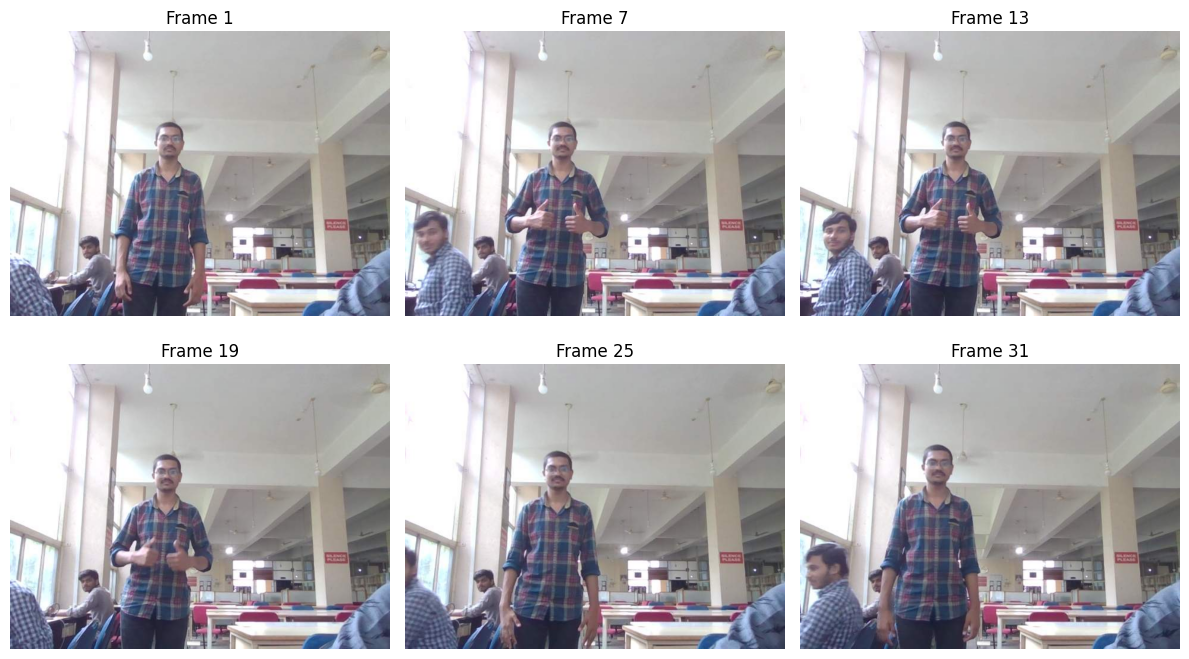

In [ ]:
import matplotlib.pyplot as plt
import cv2
import base64
import numpy as np

indices = np.linspace(
    0, len(frames_data) - 1, 6, dtype=int
)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, idx in zip(axes.flat, indices):
    encoded = frames_data[idx].split(",", 1)[-1]
    img_bytes = base64.b64decode(encoded)

    img = cv2.imdecode(
        np.frombuffer(img_bytes, np.uint8),
        cv2.IMREAD_COLOR
    )

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Frame {idx + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

data = np.load(DATA_PATH, allow_pickle=True)
X_train = data["X_train_norm"]
y_train = data["y_train"]

# Find the Alright class index
alright_idx = next(
    i for i, name in enumerate(classes)
    if "Alright" in name
)

# Select the first Alright training sample
sample_idx = np.where(y_train == alright_idx)[0][0]
training_sample = X_train[sample_idx:sample_idx + 1]

print("Training Alright sample:")
print("Mean:", round(float(training_sample.mean()), 4))
print("Std:", round(float(training_sample.std()), 4))
print("Min:", round(float(training_sample.min()), 4))
print("Max:", round(float(training_sample.max()), 4))

print("\nLive recording:")
print("Mean:", round(float(X_live.mean()), 4))
print("Std:", round(float(X_live.std()), 4))
print("Min:", round(float(X_live.min()), 4))
print("Max:", round(float(X_live.max()), 4))

print("\nLive vs training sample:")
print("Mean absolute difference:",
      round(float(np.abs(X_live - training_sample).mean()), 4))

Training Alright sample:
Mean: 0.0534
Std: 0.402
Min: -1.0
Max: 1.0

Live recording:
Mean: -0.0946
Std: 0.3065
Min: -1.0
Max: 0.7722

Live vs training sample:
Mean absolute difference: 0.3614


In [ ]:
import numpy as np
import torch

# Start with the raw live landmarks
seq = sequence.copy().reshape(-1, 2, 21, 3)

# Remember which hands were actually detected in each original frame
detected = np.any(seq != 0, axis=(2, 3))

# Fill missing hands using the nearest frame where that hand was detected
for h in range(2):
    valid = np.where(detected[:, h])[0]

    if len(valid) == 0:
        continue

    for i in np.where(~detected[:, h])[0]:
        nearest = valid[np.argmin(np.abs(valid - i))]
        seq[i, h] = seq[nearest, h]

seq = seq.reshape(-1, 126)

# Resample to 60 frames
old_t = np.linspace(0, 1, len(seq))
new_t = np.linspace(0, 1, 60)

resampled = np.stack([
    np.interp(new_t, old_t, seq[:, j])
    for j in range(126)
], axis=1).astype(np.float32)

# Apply the same wrist-relative normalization
X_test = resampled.reshape(1, 60, 2, 21, 3)

for h in range(2):
    hand = X_test[:, :, h]
    wrist = hand[:, :, 0:1, :].copy()
    hand -= wrist

    scale = np.max(np.abs(hand), axis=(2, 3), keepdims=True)
    scale[scale < 1e-6] = 1.0
    hand /= scale

X_test = X_test.reshape(1, 60, 126).astype(np.float32)

# Predict
model.eval()
with torch.no_grad():
    probs = torch.softmax(
        model(torch.tensor(X_test, dtype=torch.float32).to(device)),
        dim=1
    )[0].cpu().numpy()

top = np.argsort(probs)[::-1][:3]

print("Prediction after filling missing frames:",
      classes[int(top[0])])
print("\nTop 3 predictions:")
for idx in top:
    print(f"{classes[idx]}: {probs[idx] * 100:.2f}%")

Prediction after filling missing frames: 53. Good evening

Top 3 predictions:
53. Good evening: 28.15%
49. How are you: 22.80%
56. Pleased: 15.96%


In [ ]:

import numpy as np
import torch

# Original live sequence (raw landmarks)
raw = sequence.copy().reshape(-1, 2, 21, 3)

def predict_live(raw_sequence):
    processed = preprocess_live_sequence(
        raw_sequence.reshape(-1, 126)
    )
    model.eval()
    with torch.no_grad():
        x = torch.tensor(processed, dtype=torch.float32).to(device)
        p = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    top = np.argsort(p)[::-1][:3]
    return [(classes[i], round(float(p[i]) * 100, 2)) for i in top]

print("Original hand order:")
for name, confidence in predict_live(raw):
    print(f"{name}: {confidence:.2f}%")

print("\nReversed hand order:")
reversed_raw = raw[:, ::-1, :, :].copy()
for name, confidence in predict_live(reversed_raw):
    print(f"{name}: {confidence:.2f}%")


Original hand order:
49. How are you: 25.90%
55. Thank you: 16.05%
50. Alright: 12.15%

Reversed hand order:
50. Alright: 33.57%
49. How are you: 32.79%
55. Thank you: 19.45%


In [ ]:

import pandas as pd
import numpy as np
import os

manifest_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "reports/landmark_manifest_video_mode.csv"
)

df = pd.read_csv(manifest_path)

# Find the first successful Alright training video
row = df[
    (df["label"].astype(str).str.contains("Alright", case=False))
    & (df["status"] == "success")
].iloc[0]

path = row["sequence_path"]
seq = np.load(path)

print("Video:", os.path.basename(row["video_path"]))
print("Sequence path:", path)
print("Sequence shape:", seq.shape)
print("Data type:", seq.dtype)

# Each frame should contain 126 features:
# 2 hands × 21 landmarks × 3 coordinates
if seq.ndim == 2 and seq.shape[1] == 126:
    hands = seq.reshape(-1, 2, 21, 3)
    print("Hand 1 nonzero frames:",
          int(np.any(hands[:, 0] != 0, axis=(1, 2)).sum()))
    print("Hand 2 nonzero frames:",
          int(np.any(hands[:, 1] != 0, axis=(1, 2)).sum()))
    print("First frame hand 1 wrist:", hands[0, 0, 0])
    print("First frame hand 2 wrist:", hands[0, 1, 0])
else:
    print("Unexpected sequence shape; do not reshape it.")


Video: MVI_0037.MOV
Sequence path: /content/drive/MyDrive/T240_Sign_Language/data/landmarks_video_mode/Greetings_1of2_Greetings_50._Alright_MVI_0037.npy
Sequence shape: (73, 126)
Data type: float32
Hand 1 nonzero frames: 67
Hand 2 nonzero frames: 64
First frame hand 1 wrist: [ 4.05637145e-01  7.45777965e-01 -1.17415766e-07]
First frame hand 2 wrist: [5.9213871e-01 7.4951267e-01 1.7212018e-08]


In [ ]:

# sequence currently contains the latest raw live landmarks.
# Current live slots: Left, Right.
# Training slots: Right, Left.

raw = sequence.copy().reshape(-1, 2, 21, 3)
raw_training_order = raw[:, ::-1, :, :].copy()

X_live_fixed = preprocess_live_sequence(
    raw_training_order.reshape(-1, 126)
)

model.eval()
with torch.no_grad():
    probs_fixed = torch.softmax(
        model(torch.tensor(X_live_fixed, dtype=torch.float32).to(device)),
        dim=1
    )[0].cpu().numpy()

top = np.argsort(probs_fixed)[::-1][:3]

print("Prediction with training hand order:")
for idx in top:
    print(f"{classes[idx]}: {probs_fixed[idx] * 100:.2f}%")


Prediction with training hand order:
50. Alright: 33.57%
49. How are you: 32.79%
55. Thank you: 19.45%


In [ ]:

import numpy as np

X_train = np.load(
    "/content/drive/MyDrive/T240_Sign_Language/reports/"
    "video_mode_nearestfill_originalnorm_dataset.npz"
)

Xtr = X_train["X_train_norm"]
Xlv = X_live_fixed

print("Training mean/std:", round(float(Xtr.mean()), 4),
      round(float(Xtr.std()), 4))
print("Live mean/std:", round(float(Xlv.mean()), 4),
      round(float(Xlv.std()), 4))

print("Training min/max:", round(float(Xtr.min()), 4),
      round(float(Xtr.max()), 4))
print("Live min/max:", round(float(Xlv.min()), 4),
      round(float(Xlv.max()), 4))

live = Xlv.reshape(60, 2, 21, 3)
print("Live frames with both hands missing:",
      int(np.all(live == 0, axis=(1, 2, 3)).sum()), "/ 60")


Training mean/std: 0.0673 0.419
Live mean/std: -0.0946 0.3065
Training min/max: -1.0 1.0
Live min/max: -1.0 0.7722
Live frames with both hands missing: 11 / 60


In [ ]:

import numpy as np

dataset_path = (
    "/content/drive/MyDrive/T240_Sign_Language/reports/"
    "video_mode_nearestfill_originalnorm_dataset.npz"
)

data = np.load(dataset_path, allow_pickle=True)

X_train = data["X_train_norm"]
y_train = data["y_train"]
classes = data["classes"]

print("Training dataset shape:", X_train.shape)

# Find the first Alright sample in the training split
alright_idx = next(
    i for i, label in enumerate(y_train)
    if str(classes[int(label)]).lower().find("alright") >= 0
)

train_sample = X_train[alright_idx]
live_sample = X_live_fixed[0]

print("\nOne normalized training sample:")
print("Mean/std:", round(float(train_sample.mean()), 4),
      round(float(train_sample.std()), 4))
print("Min/max:", round(float(train_sample.min()), 4),
      round(float(train_sample.max()), 4))

print("\nLive sample:")
print("Mean/std:", round(float(live_sample.mean()), 4),
      round(float(live_sample.std()), 4))
print("Min/max:", round(float(live_sample.min()), 4),
      round(float(live_sample.max()), 4))


Training dataset shape: (152, 60, 126)

One normalized training sample:
Mean/std: 0.0534 0.402
Min/max: -1.0 1.0

Live sample:
Mean/std: -0.0946 0.3065
Min/max: -1.0 0.7722


In [ ]:

# Preserve the original function so nothing is permanently changed.
original_preprocess = preprocess_live_sequence

def preprocess_live_filled(sequence):
    sequence = sequence.copy().reshape(-1, 2, 21, 3)
    detected = np.any(sequence != 0, axis=(2, 3))

    for h in range(2):
        valid = np.where(detected[:, h])[0]
        if len(valid) == 0:
            continue
        for idx in np.where(~detected[:, h])[0]:
            nearest = valid[np.argmin(np.abs(valid - idx))]
            sequence[idx, h] = sequence[nearest, h]

    # Reuse the original resampling and normalization,
    # but ensure no frames are marked missing afterward.
    global preprocess_live_sequence

    def filled_preprocess(s):
        s = s.copy().reshape(-1, 2, 21, 3)
        detected_all = np.ones((len(s), 2), dtype=bool)
        for h in range(2):
            valid = np.where(np.any(s[:, h] != 0, axis=(1, 2)))[0]
            if len(valid) == 0:
                continue
            for idx in np.where(~np.any(s[:, h] != 0, axis=(1, 2)))[0]:
                s[idx, h] = s[valid[np.argmin(np.abs(valid - idx))], h]
        # Original function now sees every frame as detected.
        return original_preprocess(s.reshape(-1, 126))

    return filled_preprocess(sequence.reshape(-1, 126))

X_live_filled = preprocess_live_filled(
    raw_training_order.reshape(-1, 126)
)

with torch.no_grad():
    probs = torch.softmax(
        model(torch.tensor(X_live_filled, dtype=torch.float32).to(device)),
        dim=1
    )[0].cpu().numpy()

for idx in np.argsort(probs)[::-1][:3]:
    print(f"{classes[idx]}: {probs[idx] * 100:.2f}%")

# Restore original function
preprocess_live_sequence = original_preprocess


49. How are you: 49.48%
50. Alright: 21.19%
55. Thank you: 17.59%


In [ ]:

model.eval()

test_sample = torch.tensor(
    X_train[idx:idx+1],
    dtype=torch.float32,
    device=device
)

with torch.no_grad():
    probs = torch.softmax(model(test_sample), dim=1)[0].cpu().numpy()

print("Actual class:", classes[int(y_train[idx])])
print("\nTop 3 predictions on training sample:")

for i in np.argsort(probs)[::-1][:3]:
    print(f"{classes[i]}: {probs[i] * 100:.2f}%")


Actual class: 50. Alright

Top 3 predictions on training sample:
50. Alright: 98.06%
55. Thank you: 1.20%
51. Good Morning: 0.47%


In [ ]:
import cv2
import base64
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

detected_frames = 0
left_count = 0
right_count = 0

options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2,
    min_hand_detection_confidence=0.1,
    min_hand_presence_confidence=0.1,
    min_tracking_confidence=0.1
)

with vision.HandLandmarker.create_from_options(options) as landmarker:
    for i, item in enumerate(frames_data):
        encoded = item.split(",", 1)[-1]
        img_bytes = base64.b64decode(encoded)
        bgr = cv2.imdecode(
            np.frombuffer(img_bytes, np.uint8),
            cv2.IMREAD_COLOR
        )

        if bgr is None:
            continue

        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        result = landmarker.detect_for_video(image, i * 100)

        labels = {
            hand[0].category_name
            for hand in result.handedness
            if hand
        }

        if labels:
            detected_frames += 1
        if "Left" in labels:
            left_count += 1
        if "Right" in labels:
            right_count += 1

print("Total frames:", len(frames_data))
print("Frames with hands:", detected_frames)
print("Left hand detected:", left_count)
print("Right hand detected:", right_count)

Total frames: 31
Frames with hands: 9
Left hand detected: 9
Right hand detected: 9


In [ ]:
import cv2
import base64
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

indices = np.linspace(0, len(frames_data) - 1, 6, dtype=int)

options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=2,
    min_hand_detection_confidence=0.1,
    min_hand_presence_confidence=0.1
)

with vision.HandLandmarker.create_from_options(options) as landmarker:
    for idx in indices:
        encoded = frames_data[idx].split(",", 1)[-1]
        img_bytes = base64.b64decode(encoded)
        bgr = cv2.imdecode(
            np.frombuffer(img_bytes, np.uint8), cv2.IMREAD_COLOR
        )
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

        image1 = mp.Image(
            image_format=mp.ImageFormat.SRGB, data=rgb
        )
        result1 = landmarker.detect(image1)

        enlarged = cv2.resize(
            rgb, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC
        )
        image2 = mp.Image(
            image_format=mp.ImageFormat.SRGB, data=enlarged
        )
        result2 = landmarker.detect(image2)

        print(
            f"Frame {idx + 1}: "
            f"original={len(result1.hand_landmarks)} hands, "
            f"enlarged={len(result2.hand_landmarks)} hands"
        )

Frame 1: original=0 hands, enlarged=0 hands
Frame 7: original=0 hands, enlarged=0 hands
Frame 13: original=2 hands, enlarged=2 hands
Frame 19: original=2 hands, enlarged=2 hands
Frame 25: original=0 hands, enlarged=1 hands
Frame 31: original=0 hands, enlarged=0 hands


In [ ]:

def preprocess_live_sequence(sequence):
    sequence = sequence.copy().reshape(-1, 2, 21, 3)

    # Remember which frames originally contained each hand
    original_detected = np.any(sequence != 0, axis=(2, 3))

    # Fill missing frames using the nearest detected frame
    for h in range(2):
        valid_idx = np.where(original_detected[:, h])[0]

        if len(valid_idx) == 0:
            continue

        for idx in np.where(~original_detected[:, h])[0]:
            nearest = valid_idx[
                np.argmin(np.abs(valid_idx - idx))
            ]
            sequence[idx, h] = sequence[nearest, h]

    # Resample the sequence to 60 frames
    sequence = sequence.reshape(-1, 126)
    old_t = np.linspace(0, 1, len(sequence))
    new_t = np.linspace(0, 1, 60)

    resampled = np.stack([
        np.interp(new_t, old_t, sequence[:, j])
        for j in range(126)
    ], axis=1).astype(np.float32)

    X = resampled.reshape(1, 60, 2, 21, 3)

    # Normalize each hand relative to its wrist
    for h in range(2):
        hand = X[:, :, h]
        wrist = hand[:, :, 0:1, :].copy()
        hand -= wrist

        scale = np.max(
            np.abs(hand), axis=(2, 3), keepdims=True
        )
        scale[scale < 1e-6] = 1.0
        hand /= scale

        # Restore originally missing frames after resampling
        detected_at_new_t = np.interp(
            new_t,
            old_t,
            original_detected[:, h].astype(np.float32)
        ) >= 0.5

        hand[:, ~detected_at_new_t, :, :] = 0

    return X.reshape(1, 60, 126).astype(np.float32)

print("Updated live preprocessing function.")


Updated live preprocessing function.


In [ ]:
import json
import base64
import cv2
import numpy as np
import mediapipe as mp
import torch

with open("/content/sign_frames.json", "r") as f:
    frames_data = json.load(f)

print("Frames loaded:", len(frames_data))

Frames loaded: 18


In [ ]:
import base64
import cv2
import numpy as np
import mediapipe as mp
import torch

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# Load MediaPipe hand landmark model
options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(
        model_asset_path=HAND_MODEL
    ),
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2,
    min_hand_detection_confidence=0.3,
    min_hand_presence_confidence=0.3,
    min_tracking_confidence=0.3
)

sequence = []

with vision.HandLandmarker.create_from_options(options) as landmarker:
    for i, item in enumerate(frames_data):
        # Decode captured browser frame
        encoded = item.split(",", 1)[1] if "," in item else item
        image_bytes = base64.b64decode(encoded)
        image_array = np.frombuffer(image_bytes, np.uint8)
        bgr = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

        if bgr is None:
            sequence.append(np.zeros((126,), dtype=np.float32))
            continue

        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        result = landmarker.detect_for_video(image, i * 100)

        hands = np.zeros((2, 21, 3), dtype=np.float32)

        if result.hand_landmarks:
            for h, hand_landmarks in enumerate(
                result.hand_landmarks[:2]
            ):
                hands[h] = np.array([
                    [p.x, p.y, p.z] for p in hand_landmarks
                ], dtype=np.float32)

        sequence.append(hands.reshape(126))

sequence = np.asarray(sequence, dtype=np.float32)

print("Landmark sequence shape:", sequence.shape)
print("Frames with detected hands:",
      int(np.any(sequence != 0, axis=1).sum()))

# Preprocess and predict
if not np.any(sequence):
    print("No hands detected. Please capture again.")
else:
    X_live = preprocess_live_sequence(sequence)
    input_tensor = torch.tensor(X_live, dtype=torch.float32).to(device)

    model.eval()
    with torch.no_grad():
        logits = model(input_tensor)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    top_indices = np.argsort(probs)[::-1][:3]
    best_idx = int(top_indices[0])

    print("\nExpected action: Alright")
    print("Predicted action:", classes[best_idx].split(". ", 1)[-1])
    print(f"Confidence: {probs[best_idx] * 100:.2f}%")

    print("\nTop 3 predictions:")
    for idx in top_indices:
        print(f"{classes[idx]}: {probs[idx] * 100:.2f}%")

Landmark sequence shape: (18, 126)
Frames with detected hands: 16

Expected action: Alright
Predicted action: Thank you
Confidence: 28.11%

Top 3 predictions:
55. Thank you: 28.11%
49. How are you: 18.78%
50. Alright: 13.59%


In [ ]:
import pandas as pd
import numpy as np
import os

BASE = "/content/drive/MyDrive/T240_Sign_Language"
manifest_path = f"{BASE}/reports/landmark_manifest_video_mode.csv"

manifest = pd.read_csv(manifest_path)

alright_rows = manifest[
    manifest["label"].astype(str).str.contains(
        "Alright", case=False, na=False
    )
]

print("Alright videos found:", len(alright_rows))
print(alright_rows[["label", "sequence_path", "frames"]].head(5).to_string(index=False))

Alright videos found: 21
      label                                                                                                         sequence_path  frames
50. Alright /content/drive/MyDrive/T240_Sign_Language/data/landmarks_video_mode/Greetings_1of2_Greetings_50._Alright_MVI_0037.npy      73
50. Alright /content/drive/MyDrive/T240_Sign_Language/data/landmarks_video_mode/Greetings_1of2_Greetings_50._Alright_MVI_0038.npy      84
50. Alright /content/drive/MyDrive/T240_Sign_Language/data/landmarks_video_mode/Greetings_1of2_Greetings_50._Alright_MVI_0039.npy      79
50. Alright /content/drive/MyDrive/T240_Sign_Language/data/landmarks_video_mode/Greetings_1of2_Greetings_50._Alright_MVI_0040.npy      80
50. Alright /content/drive/MyDrive/T240_Sign_Language/data/landmarks_video_mode/Greetings_1of2_Greetings_50._Alright_MVI_0043.npy      56


In [ ]:
import numpy as np

# First original Alright training video
train_path = alright_rows.iloc[0]["sequence_path"]
train_seq = np.load(train_path).astype(np.float32)

# Your current webcam sequence
live_seq = sequence.copy().astype(np.float32)

print("TRAINING SAMPLE")
print("Shape:", train_seq.shape)
print("Nonzero frames:", np.any(train_seq != 0, axis=1).sum())
print("Mean:", round(float(train_seq.mean()), 4))
print("Std:", round(float(train_seq.std()), 4))
print("Min / Max:", round(float(train_seq.min()), 4),
      "/", round(float(train_seq.max()), 4))

print("\nWEBCAM SAMPLE")
print("Shape:", live_seq.shape)
print("Nonzero frames:", np.any(live_seq != 0, axis=1).sum())
print("Mean:", round(float(live_seq.mean()), 4))
print("Std:", round(float(live_seq.std()), 4))
print("Min / Max:", round(float(live_seq.min()), 4),
      "/", round(float(live_seq.max()), 4))

TRAINING SAMPLE
Shape: (73, 126)
Nonzero frames: 67
Mean: 0.3363
Std: 0.3088
Min / Max: -0.0318 / 0.8574

WEBCAM SAMPLE
Shape: (18, 126)
Nonzero frames: 16
Mean: 0.3848
Std: 0.4163
Min / Max: -0.1087 / 1.1133


In [ ]:
# Load the original Alright training sequence
train_seq = np.load(train_path).astype(np.float32)

# Use the same preprocessing as the live webcam
X_train_test = preprocess_live_sequence(train_seq)

# Predict
input_tensor = torch.tensor(
    X_train_test, dtype=torch.float32
).to(device)

model.eval()
with torch.no_grad():
    probs = torch.softmax(model(input_tensor), dim=1)[0].cpu().numpy()

top_indices = np.argsort(probs)[::-1][:3]

print("Actual action: Alright")
print("Predicted action:", classes[int(np.argmax(probs))].split(". ", 1)[-1])
print("\nTop 3 predictions:")

for idx in top_indices:
    print(f"{classes[idx]}: {probs[idx] * 100:.2f}%")

Actual action: Alright
Predicted action: Thank you

Top 3 predictions:
55. Thank you: 93.91%
50. Alright: 5.42%
54. Good night: 0.32%


In [ ]:
# Find an Alright video in the validation set
val_path = "/content/drive/MyDrive/T240_Sign_Language/reports/video_mode_nearestfill_originalnorm_dataset.npz"

data = np.load(val_path, allow_pickle=True)
print("Available keys:", data.files)
print("Classes:", data["classes"])

Available keys: ['X_train_norm', 'X_val_norm', 'y_train', 'y_val', 'classes']
Classes: ['48. Hello' '49. How are you' '50. Alright' '51. Good Morning'
 '52. Good afternoon' '53. Good evening' '54. Good night' '55. Thank you'
 '56. Pleased']


In [ ]:

import numpy as np
import torch

X_val = data["X_val_norm"]
y_val = data["y_val"]
classes = data["classes"].tolist()

model.eval()
with torch.no_grad():
    X_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
    logits = model(X_tensor)
    predictions = logits.argmax(dim=1).cpu().numpy()

alright_idx = classes.index("50. Alright")
mask = y_val == alright_idx

print("Held-out Alright samples:", int(mask.sum()))
print("Correctly predicted:", int(((predictions == alright_idx) & mask).sum()))

for i in np.where(mask)[0]:
    pred_idx = int(predictions[i])
    probs = torch.softmax(logits[i], dim=0).cpu().numpy()
    print(
        f"Actual: Alright | Predicted: {classes[pred_idx]} "
        f"| Confidence: {probs[pred_idx] * 100:.2f}%"
    )


Held-out Alright samples: 4
Correctly predicted: 4
Actual: Alright | Predicted: 50. Alright | Confidence: 98.04%
Actual: Alright | Predicted: 50. Alright | Confidence: 59.25%
Actual: Alright | Predicted: 50. Alright | Confidence: 98.66%
Actual: Alright | Predicted: 50. Alright | Confidence: 80.35%


In [ ]:

import base64
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2,
    min_hand_detection_confidence=0.3,
    min_hand_presence_confidence=0.3,
    min_tracking_confidence=0.3
)

with vision.HandLandmarker.create_from_options(options) as landmarker:
    for i, item in enumerate(frames_data):
        encoded = item.split(",", 1)[1] if "," in item else item
        img_bytes = base64.b64decode(encoded)
        bgr = cv2.imdecode(
            np.frombuffer(img_bytes, np.uint8), cv2.IMREAD_COLOR
        )
        if bgr is None:
            continue

        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
        result = landmarker.detect_for_video(image, i * 100)

        if result.hand_landmarks:
            labels = [
                h[0].category_name
                for h in result.handedness
            ]
            print(f"Frame {i}: {labels}")
            if i >= 5:
                break


Frame 2: ['Left']
Frame 3: ['Left']
Frame 4: ['Left', 'Right']
Frame 5: ['Left', 'Right']


In [ ]:

import base64
import cv2
import numpy as np
import mediapipe as mp
import torch
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

sequence = []

options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2,
    min_hand_detection_confidence=0.3,
    min_hand_presence_confidence=0.3,
    min_tracking_confidence=0.3
)

with vision.HandLandmarker.create_from_options(options) as landmarker:
    for i, item in enumerate(frames_data):
        encoded = item.split(",", 1)[1] if "," in item else item
        img_bytes = base64.b64decode(encoded)
        bgr = cv2.imdecode(
            np.frombuffer(img_bytes, np.uint8), cv2.IMREAD_COLOR
        )

        if bgr is None:
            sequence.append(np.zeros(126, dtype=np.float32))
            continue

        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
        result = landmarker.detect_for_video(image, i * 100)

        hands = np.zeros((2, 21, 3), dtype=np.float32)

        for hand_landmarks, handedness in zip(
            result.hand_landmarks, result.handedness
        ):
            label = handedness[0].category_name
            hand_idx = 0 if label == "Left" else 1
            hands[hand_idx] = np.array(
                [[p.x, p.y, p.z] for p in hand_landmarks],
                dtype=np.float32
            )

        sequence.append(hands.reshape(126))

sequence = np.asarray(sequence, dtype=np.float32)

print("Landmark sequence shape:", sequence.shape)
print("Frames with hands:", int(np.any(sequence != 0, axis=1).sum()))

if np.any(sequence != 0):
    X_live = preprocess_live_sequence(sequence)
    input_tensor = torch.tensor(X_live, dtype=torch.float32).to(device)

    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(input_tensor), dim=1)[0].cpu().numpy()

    top = np.argsort(probs)[::-1][:3]
    print("\nExpected action: Alright")
    print("Predicted action:", classes[int(top[0])].split(". ", 1)[-1])
    print("\nTop 3 predictions:")
    for idx in top:
        print(f"{classes[idx]}: {probs[idx] * 100:.2f}%")
else:
    print("No hands detected. Capture the sign again.")


Landmark sequence shape: (18, 126)
Frames with hands: 16

Expected action: Alright
Predicted action: Thank you

Top 3 predictions:
55. Thank you: 28.11%
49. How are you: 18.78%
50. Alright: 13.59%


In [ ]:

# Process the training Alright example and the webcam clip
train_seq = np.load(train_path).astype(np.float32)

X_train_check = preprocess_live_sequence(train_seq)[0]
X_live_check = preprocess_live_sequence(sequence)[0]

print("Training normalized sequence:")
print("Mean:", round(float(X_train_check.mean()), 4))
print("Std:", round(float(X_train_check.std()), 4))
print("Min:", round(float(X_train_check.min()), 4))
print("Max:", round(float(X_train_check.max()), 4))

print("\nWebcam normalized sequence:")
print("Mean:", round(float(X_live_check.mean()), 4))
print("Std:", round(float(X_live_check.std()), 4))
print("Min:", round(float(X_live_check.min()), 4))
print("Max:", round(float(X_live_check.max()), 4))

print("\nNonzero values:")
print("Training:", int(np.count_nonzero(X_train_check)))
print("Webcam:", int(np.count_nonzero(X_live_check)))


Training normalized sequence:
Mean: 0.0549
Std: 0.3829
Min: -1.0
Max: 1.0

Webcam normalized sequence:
Mean: -0.1057
Std: 0.3002
Min: -1.0
Max: 0.7352

Nonzero values:
Training: 6420
Webcam: 6060


In [ ]:
import numpy as np

path = "/content/drive/MyDrive/T240_Sign_Language/reports/video_mode_nearestfill_originalnorm_dataset.npz"

data = np.load(path, allow_pickle=True)

X_train = data["X_train_norm"]
X_val = data["X_val_norm"]
classes = data["classes"].tolist()

alright_idx = classes.index("50. Alright")
alright_train = X_train[data["y_train"] == alright_idx]
alright_val = X_val[data["y_val"] == alright_idx]

print("Training dataset shape:", X_train.shape)
print("Validation dataset shape:", X_val.shape)
print("Alright training samples:", len(alright_train))
print("Alright validation samples:", len(alright_val))

print("\nNormalized Alright training statistics:")
print("Mean:", round(float(alright_train.mean()), 4))
print("Std:", round(float(alright_train.std()), 4))
print("Min:", round(float(alright_train.min()), 4))
print("Max:", round(float(alright_train.max()), 4))

Training dataset shape: (152, 60, 126)
Validation dataset shape: (38, 60, 126)
Alright training samples: 17
Alright validation samples: 4

Normalized Alright training statistics:
Mean: 0.0364
Std: 0.3921
Min: -1.0
Max: 1.0


In [ ]:
import numpy as np

path = "/content/drive/MyDrive/T240_Sign_Language/reports/video_mode_nearestfill_originalnorm_dataset.npz"

with np.load(path, allow_pickle=True) as d:
    for key in d.files:
        arr = d[key]
        print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

print("\nCurrent live sequence:", sequence.shape)
print("Current preprocessed sequence:", X_live_check.shape)

X_train_norm: shape=(152, 60, 126), dtype=float32
X_val_norm: shape=(38, 60, 126), dtype=float32
y_train: shape=(152,), dtype=int64
y_val: shape=(38,), dtype=int64
classes: shape=(9,), dtype=<U18

Current live sequence: (18, 126)
Current preprocessed sequence: (60, 126)


In [ ]:

# Prediction using the current normalized live sequence
X_live_norm = preprocess_live_sequence(sequence)

with torch.no_grad():
    normalized_probs = torch.softmax(
        model(torch.tensor(X_live_norm, dtype=torch.float32).to(device)),
        dim=1
    )[0].cpu().numpy()

print("Prediction after normalization:")
for idx in np.argsort(normalized_probs)[::-1][:3]:
    print(f"{classes[idx]}: {normalized_probs[idx] * 100:.2f}%")


Prediction after normalization:
55. Thank you: 28.11%
49. How are you: 18.78%
50. Alright: 13.59%


In [ ]:
from google.colab import drive
import os

BASE = "/content/drive/MyDrive/T240_Sign_Language"

for root, dirs, files in os.walk("/content/drive/MyDrive/T240_Sign_Language"):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    for file in files:
        if file.endswith(".ipynb") or file.endswith(".py"):
            print(os.path.join(root, file))

In [ ]:
import torch
from pathlib import Path

checkpoint_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "models/best_sign_language_bilstm.pth"
)

print("Checkpoint exists:", Path(checkpoint_path).exists())

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

Checkpoint exists: True
Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['lstm.weight_ih_l0', 'lstm.weight_hh_l0', 'lstm.bias_ih_l0', 'lstm.bias_hh_l0', 'lstm.weight_ih_l0_reverse', 'lstm.weight_hh_l0_reverse', 'lstm.bias_ih_l0_reverse', 'lstm.bias_hh_l0_reverse', 'fc.weight', 'fc.bias']


In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

checkpoint_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "models/best_sign_language_bilstm.pth"
)

dataset_path = (
    "/content/drive/MyDrive/T240_Sign_Language/"
    "reports/video_mode_nearestfill_originalnorm_dataset.npz"
)

# Load the saved dataset
data = np.load(dataset_path, allow_pickle=True)
X_val = data["X_val_norm"]
y_val = data["y_val"]
classes = data["classes"]

# Rebuild the model architecture
model = SignLanguageBiLSTM().to(device)

# Load the saved weights
state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
model.load_state_dict(state_dict)
model.eval()

# Evaluate the reloaded model
with torch.no_grad():
    inputs = torch.tensor(X_val, dtype=torch.float32).to(device)
    logits = model(inputs)
    predictions = logits.argmax(dim=1).cpu().numpy()

accuracy = accuracy_score(y_val, predictions)
macro_f1 = f1_score(
    y_val, predictions,
    average="macro",
    zero_division=0
)

print("Checkpoint reloaded successfully!")
print(f"Validation samples: {len(y_val)}")
print(f"Correct predictions: {(predictions == y_val).sum()}/{len(y_val)}")
print(f"Validation accuracy: {accuracy:.2%}")
print(f"Macro F1-score: {macro_f1:.4f}")

Checkpoint reloaded successfully!
Validation samples: 38
Correct predictions: 35/38
Validation accuracy: 92.11%
Macro F1-score: 0.9249


In [ ]:
print("Model architecture:")
print(model)

print("\nCheckpoint weight shapes:")
state_dict = torch.load(
    "/content/drive/MyDrive/T240_Sign_Language/models/best_sign_language_bilstm.pth",
    map_location="cpu",
    weights_only=True
)

for name, weight in state_dict.items():
    print(f"{name}: {tuple(weight.shape)}")

Model architecture:
SignLanguageBiLSTM(
  (lstm): LSTM(126, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=9, bias=True)
)

Checkpoint weight shapes:
lstm.weight_ih_l0: (256, 126)
lstm.weight_hh_l0: (256, 64)
lstm.bias_ih_l0: (256,)
lstm.bias_hh_l0: (256,)
lstm.weight_ih_l0_reverse: (256, 126)
lstm.weight_hh_l0_reverse: (256, 64)
lstm.bias_ih_l0_reverse: (256,)
lstm.bias_hh_l0_reverse: (256,)
fc.weight: (9, 128)
fc.bias: (9,)


In [ ]:
import sys
import numpy as np
import torch
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

project_root = Path("/content/drive/MyDrive/T240_Sign_Language")
sys.path.insert(0, str(project_root / "src"))

from model import SignLanguageBiLSTM

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SignLanguageBiLSTM(num_classes=9).to(device)

checkpoint_path = project_root / "models" / "best_sign_language_bilstm.pth"
state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)
model.eval()

dataset_path = (
    project_root / "reports" /
    "video_mode_nearestfill_originalnorm_dataset.npz"
)

data = np.load(dataset_path, allow_pickle=True)
X_val = data["X_val_norm"]
y_val = data["y_val"]

with torch.no_grad():
    X_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
    predictions = model(X_tensor).argmax(dim=1).cpu().numpy()

accuracy = accuracy_score(y_val, predictions)
macro_f1 = f1_score(
    y_val, predictions, average="macro", zero_division=0
)

print("Standalone model test passed!")
print(f"Validation accuracy: {accuracy:.2%}")
print(f"Macro F1-score: {macro_f1:.4f}")
print(f"Device: {device}")

Standalone model test passed!
Validation accuracy: 36.84%
Macro F1-score: 0.2581
Device: cpu


In [ ]:
import torch
import numpy as np

# Recreate the standalone model
standalone_model = SignLanguageBiLSTM(num_classes=9).to(device)
standalone_model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/T240_Sign_Language/"
        "models/best_sign_language_bilstm.pth",
        map_location=device,
        weights_only=True
    )
)
standalone_model.eval()

# Compare against the original model if it was preserved
print("Standalone model class:", type(standalone_model))
print("Standalone forward method:")
import inspect
print(inspect.getsource(standalone_model.forward))

Standalone model class: <class 'model.SignLanguageBiLSTM'>
Standalone forward method:
    def forward(self, x):
        output, _ = self.lstm(x)
        last_output = output[:, -1, :]
        last_output = self.dropout(last_output)
        return self.fc(last_output)



In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

project_root = "/content/drive/MyDrive/T240_Sign_Language"
checkpoint_path = f"{project_root}/models/best_sign_language_bilstm.pth"
dataset_path = (
    f"{project_root}/reports/"
    "video_mode_nearestfill_originalnorm_dataset.npz"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load checkpoint and validation data
state = torch.load(
    checkpoint_path, map_location=device, weights_only=True
)
data = np.load(dataset_path, allow_pickle=True)
X = torch.tensor(data["X_val_norm"], dtype=torch.float32).to(device)
y = data["y_val"]

# Rebuild the shared LSTM and FC layers from the saved weights
lstm = torch.nn.LSTM(
    input_size=126,
    hidden_size=64,
    num_layers=1,
    batch_first=True,
    bidirectional=True
).to(device)
fc = torch.nn.Linear(128, 9).to(device)

lstm.load_state_dict({
    k.removeprefix("lstm."): v
    for k, v in state.items() if k.startswith("lstm.")
})
fc.load_state_dict({
    k.removeprefix("fc."): v
    for k, v in state.items() if k.startswith("fc.")
})

lstm.eval()
fc.eval()

with torch.no_grad():
    output, (h_n, c_n) = lstm(X)

    # Method A: final sequence output
    pred_a = fc(output[:, -1, :]).argmax(dim=1).cpu().numpy()

    # Method B: concatenate final forward and backward hidden states
    final_hidden = torch.cat([h_n[-2], h_n[-1]], dim=1)
    pred_b = fc(final_hidden).argmax(dim=1).cpu().numpy()

for name, pred in [
    ("Sequence output", pred_a),
    ("Final hidden states", pred_b)
]:
    print(
        f"{name}: accuracy={accuracy_score(y, pred):.2%}, "
        f"macro F1={f1_score(y, pred, average='macro', zero_division=0):.4f}"
    )

Sequence output: accuracy=36.84%, macro F1=0.2581
Final hidden states: accuracy=92.11%, macro F1=0.9249


In [ ]:
import sys
import importlib
import torch
import numpy as np
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

project_root = Path("/content/drive/MyDrive/T240_Sign_Language")
sys.path.insert(0, str(project_root / "src"))

import model as model_module
importlib.reload(model_module)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model_module.SignLanguageBiLSTM(num_classes=9).to(device)

checkpoint_path = project_root / "models" / "best_sign_language_bilstm.pth"
model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)
model.eval()

data = np.load(
    project_root / "reports" /
    "video_mode_nearestfill_originalnorm_dataset.npz",
    allow_pickle=True
)

X_val = torch.tensor(data["X_val_norm"], dtype=torch.float32).to(device)
y_val = data["y_val"]

with torch.no_grad():
    predictions = model(X_val).argmax(dim=1).cpu().numpy()

print(f"Validation accuracy: {accuracy_score(y_val, predictions):.2%}")
print(f"Macro F1-score: {f1_score(y_val, predictions, average='macro', zero_division=0):.4f}")

Validation accuracy: 92.11%
Macro F1-score: 0.9249


In [6]:

import os
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from tqdm.auto import tqdm

BASE_DIR = "/content/drive/MyDrive/T240_Sign_Language"
SOURCE_MANIFEST = f"{BASE_DIR}/reports/landmark_manifest.csv"
OUTPUT_DIR = f"{BASE_DIR}/data/landmarks_hand_body_video_mode"
OUTPUT_MANIFEST = f"{BASE_DIR}/reports/landmark_manifest_hand_body_video_mode.csv"

HAND_MODEL = f"{BASE_DIR}/models/hand_landmarker.task"
POSE_MODEL = f"{BASE_DIR}/models/pose_landmarker_lite.task"

os.makedirs(OUTPUT_DIR, exist_ok=True)
df = pd.read_csv(SOURCE_MANIFEST)
results = []

for _, row in tqdm(df.iterrows(), total=len(df), desc="Hand + body extraction"):
    video_path = row["video_path"]
    cap = cv2.VideoCapture(video_path)
    sequence = []
    detected_hands = 0
    detected_body = 0
    frame_index = 0
    status = "success"
    error_message = ""
    output_path = ""

    try:
        if not cap.isOpened():
            raise RuntimeError("Could not open video")

        hand_options = vision.HandLandmarkerOptions(
            base_options=python.BaseOptions(model_asset_path=HAND_MODEL),
            running_mode=vision.RunningMode.VIDEO,
            num_hands=2,
            min_hand_detection_confidence=0.3,
            min_hand_presence_confidence=0.3,
            min_tracking_confidence=0.5,
        )

        pose_options = vision.PoseLandmarkerOptions(
            base_options=python.BaseOptions(model_asset_path=POSE_MODEL),
            running_mode=vision.RunningMode.VIDEO,
            num_poses=1,
            min_pose_detection_confidence=0.3,
            min_pose_presence_confidence=0.3,
            min_tracking_confidence=0.5,
        )

        with (
            vision.HandLandmarker.create_from_options(hand_options) as hand_detector,
            vision.PoseLandmarker.create_from_options(pose_options) as pose_detector,
        ):
            while True:
                ok, frame = cap.read()
                if not ok:
                    break

                rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                image = mp.Image(
                    image_format=mp.ImageFormat.SRGB,
                    data=rgb,
                )

                # VIDEO timestamps must be monotonically increasing.
                timestamp_ms = frame_index * 1000 / max(
                    cap.get(cv2.CAP_PROP_FPS), 1
                )

                # MediaPipe expects integer timestamps in milliseconds.
                timestamp_ms = int(timestamp_ms)

                hand_result = hand_detector.detect_for_video(
                    image, timestamp_ms
                )
                pose_result = pose_detector.detect_for_video(
                    image, timestamp_ms
                )

                hands = np.zeros((2, 21, 3), dtype=np.float32)
                body = np.zeros((33, 3), dtype=np.float32)

                if hand_result.hand_landmarks:
                    detected_hands += 1

                    for landmarks, handedness in zip(
                        hand_result.hand_landmarks,
                        hand_result.handedness,
                    ):
                        label = (
                            handedness[0].category_name.lower()
                            if handedness else ""
                        )
                        hand_idx = 0 if label == "left" else 1

                        hands[hand_idx] = np.asarray(
                            [[p.x, p.y, p.z] for p in landmarks],
                            dtype=np.float32,
                        )

                if pose_result.pose_landmarks:
                    detected_body += 1
                    body = np.asarray(
                        [
                            [p.x, p.y, p.z]
                            for p in pose_result.pose_landmarks[0]
                        ],
                        dtype=np.float32,
                    )

                # 126 hand features + 99 body features = 225.
                features = np.concatenate([
                    hands.reshape(-1),
                    body.reshape(-1),
                ])
                sequence.append(features)
                frame_index += 1

        if frame_index == 0:
            raise RuntimeError("No frames read")

        relative_path = os.path.relpath(
            video_path, f"{BASE_DIR}/data/raw"
        )
        safe_name = (
            relative_path.replace(os.sep, "_")
            .replace(" ", "_")
            .replace(".MOV", "")
            .replace(".mov", "")
        )
        output_path = os.path.join(OUTPUT_DIR, safe_name + ".npy")

        np.save(output_path, np.asarray(sequence, dtype=np.float32))

    except Exception as e:
        status = "error"
        error_message = repr(e)

    finally:
        cap.release()

    results.append({
        **row.to_dict(),
        "sequence_path": output_path,
        "frames": frame_index,
        "frames_with_hands": detected_hands,
        "frames_with_body": detected_body,
        "status": status,
        "error_message": error_message,
    })

    # Save progress after every video.
    pd.DataFrame(results).to_csv(OUTPUT_MANIFEST, index=False)

video_manifest = pd.DataFrame(results)
total_frames = video_manifest["frames"].sum()

print("\nExtraction complete.")
print("Videos processed:", len(video_manifest))
print("\nStatus counts:")
print(video_manifest["status"].value_counts(dropna=False))
print("Total frames:", total_frames)
print("Frames with hands:", video_manifest["frames_with_hands"].sum())
print("Frames with body:", video_manifest["frames_with_body"].sum())

if total_frames:
    print(
        f"Hand coverage: "
        f"{video_manifest['frames_with_hands'].sum() / total_frames * 100:.2f}%"
    )
    print(
        f"Body coverage: "
        f"{video_manifest['frames_with_body'].sum() / total_frames * 100:.2f}%"
    )

print("\nManifest:", OUTPUT_MANIFEST)
print("Landmarks:", OUTPUT_DIR)


Hand + body extraction:   0%|          | 0/190 [00:00<?, ?it/s]


Extraction complete.
Videos processed: 190

Status counts:
status
success    190
Name: count, dtype: int64
Total frames: 12884
Frames with hands: 12331
Frames with body: 12884
Hand coverage: 95.71%
Body coverage: 100.00%

Manifest: /content/drive/MyDrive/T240_Sign_Language/reports/landmark_manifest_hand_body_video_mode.csv
Landmarks: /content/drive/MyDrive/T240_Sign_Language/data/landmarks_hand_body_video_mode


In [7]:

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

BASE = "/content/drive/MyDrive/T240_Sign_Language"

MANIFEST_PATH = (
    f"{BASE}/reports/landmark_manifest_hand_body_video_mode.csv"
)
OUTPUT_PATH = (
    f"{BASE}/reports/"
    "hand_body_225_nearestfill_dataset.npz"
)

manifest = pd.read_csv(MANIFEST_PATH)
manifest = manifest[
    manifest["status"] == "success"
].reset_index(drop=True)

print("Successful videos:", len(manifest))


def fill_nearest_frames(sequence, start, end, landmarks_count):
    """Fill missing frames independently for one landmark group."""
    group = sequence[:, start:end].reshape(
        len(sequence), landmarks_count, 3
    ).copy()

    valid = np.any(group != 0, axis=(1, 2))
    valid_idx = np.where(valid)[0]

    if len(valid_idx) == 0:
        return group.reshape(len(sequence), -1)

    for idx in np.where(~valid)[0]:
        nearest = valid_idx[
            np.argmin(np.abs(valid_idx - idx))
        ]
        group[idx] = group[nearest]

    return group.reshape(len(sequence), -1)


def resample_sequence(sequence, target_len=60):
    if len(sequence) == 0:
        raise ValueError("Cannot resample an empty sequence.")

    if len(sequence) == 1:
        return np.repeat(
            sequence, target_len, axis=0
        ).astype(np.float32)

    old_t = np.linspace(0, 1, len(sequence))
    new_t = np.linspace(0, 1, target_len)

    result = np.zeros(
        (target_len, sequence.shape[1]),
        dtype=np.float32
    )

    for j in range(sequence.shape[1]):
        result[:, j] = np.interp(
            new_t, old_t, sequence[:, j]
        )

    return result


def normalize_landmarks(X):
    # X: (samples, 60, 225)
    X = X.copy().reshape(-1, 60, 225)

    for sample_idx in range(len(X)):
        # ---- Normalize the two hands independently ----
        hands = X[sample_idx, :, :126].reshape(
            60, 2, 21, 3
        )

        for h in range(2):
            hand = hands[:, h]
            detected = np.any(
                hand != 0, axis=(1, 2)
            )

            wrist = hand[:, 0:1, :].copy()
            hand -= wrist

            scale = np.max(
                np.abs(hand), axis=(1, 2), keepdims=True
            )
            scale[scale < 1e-6] = 1.0

            hand /= scale
            hand[~detected] = 0

        X[sample_idx, :, :126] = hands.reshape(60, 126)

        # ---- Normalize body pose independently ----
        body = X[sample_idx, :, 126:].reshape(
            60, 33, 3
        )

        detected_body = np.any(
            body != 0, axis=(1, 2)
        )

        # MediaPipe Pose landmarks 11 and 12 are shoulders.
        shoulder_center = (
            body[:, 11:12, :] + body[:, 12:13, :]
        ) / 2.0

        body -= shoulder_center

        scale = np.max(
            np.abs(body), axis=(1, 2), keepdims=True
        )
        scale[scale < 1e-6] = 1.0

        body /= scale
        body[~detected_body] = 0

        X[sample_idx, :, 126:] = body.reshape(60, 99)

    return X.astype(np.float32)


# Load the new 225-feature sequences.
sequences = []
labels = []

for _, row in manifest.iterrows():
    path = row["sequence_path"]
    sequence = np.load(path).astype(np.float32)

    if sequence.ndim != 2 or sequence.shape[1] != 225:
        raise ValueError(
            f"Expected (frames, 225), got {sequence.shape}: {path}"
        )

    if len(sequence) == 0:
        raise ValueError(f"Empty sequence: {path}")

    # Fill missing hands and body independently.
    hands_filled = fill_nearest_frames(
        sequence, 0, 126, 42
    )
    body_filled = fill_nearest_frames(
        sequence, 126, 225, 33
    )

    sequence = np.concatenate(
        [hands_filled, body_filled], axis=1
    )

    sequence = resample_sequence(sequence, target_len=60)

    sequences.append(sequence)
    labels.append(row["label"])

X = np.stack(sequences).astype(np.float32)
labels = np.asarray(labels)

encoder = LabelEncoder()
y = encoder.fit_transform(labels)

train_idx, val_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_norm = normalize_landmarks(X[train_idx])
X_val_norm = normalize_landmarks(X[val_idx])

y_train = y[train_idx]
y_val = y[val_idx]

np.savez_compressed(
    OUTPUT_PATH,
    X_train_norm=X_train_norm,
    X_val_norm=X_val_norm,
    y_train=y_train,
    y_val=y_val,
    classes=encoder.classes_
)

print("\nNew hand + body dataset saved!")
print("Train shape:", X_train_norm.shape)
print("Validation shape:", X_val_norm.shape)
print("Features per frame:", X_train_norm.shape[-1])
print("Train std:", round(float(X_train_norm.std()), 4))
print("Validation std:", round(float(X_val_norm.std()), 4))
print(
    "All values finite:",
    np.isfinite(X_train_norm).all()
    and np.isfinite(X_val_norm).all()
)
print("Saved:", OUTPUT_PATH)


Successful videos: 190

New hand + body dataset saved!
Train shape: (152, 60, 225)
Validation shape: (38, 60, 225)
Features per frame: 225
Train std: 0.3664
Validation std: 0.3659
All values finite: True
Saved: /content/drive/MyDrive/T240_Sign_Language/reports/hand_body_225_nearestfill_dataset.npz


In [8]:
import numpy as np

BASE = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = f"{BASE}/reports/hand_body_225_nearestfill_dataset.npz"

data = np.load(DATA_PATH, allow_pickle=True)

print("Dataset keys:", data.files)

for key in data.files:
    value = data[key]
    print(f"{key}: shape={value.shape}, dtype={value.dtype}")

Dataset keys: ['X_train_norm', 'X_val_norm', 'y_train', 'y_val', 'classes']
X_train_norm: shape=(152, 60, 225), dtype=float32
X_val_norm: shape=(38, 60, 225), dtype=float32
y_train: shape=(152,), dtype=int64
y_val: shape=(38,), dtype=int64
classes: shape=(9,), dtype=<U18


In [9]:

import os
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

BASE = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = f"{BASE}/reports/hand_body_225_nearestfill_dataset.npz"
MODEL_PATH = f"{BASE}/models/best_sign_language_hand_body_bilstm.pth"

# Load the new 225-feature dataset
data = np.load(DATA_PATH, allow_pickle=True)

X_train = torch.tensor(data["X_train_norm"], dtype=torch.float32)
y_train = torch.tensor(data["y_train"], dtype=torch.long)
X_val = torch.tensor(data["X_val_norm"], dtype=torch.float32)
y_val = data["y_val"]
classes = data["classes"].tolist()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Classes:", classes)

# Separate model for hand + body (225 features)
class SignLanguageHandBodyBiLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=225,
            hidden_size=64,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, len(classes))

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        combined = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(combined))

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=16,
    shuffle=True
)

model = SignLanguageHandBodyBiLSTM().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

best_accuracy = -1.0
best_state = None
epochs = 60
patience = 12
epochs_without_improvement = 0

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * xb.size(0)

    model.eval()
    with torch.no_grad():
        val_logits = model(X_val.to(device))
        val_predictions = val_logits.argmax(dim=1).cpu().numpy()

    val_accuracy = accuracy_score(y_val, val_predictions)
    val_f1 = f1_score(
        y_val, val_predictions, average="macro", zero_division=0
    )
    avg_loss = total_loss / len(X_train)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"Val accuracy: {val_accuracy:.2%} | "
        f"Macro F1: {val_f1:.4f}"
    )

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping.")
        break

# Save the best checkpoint separately
if best_state is None:
    raise RuntimeError("Training did not produce a checkpoint.")

model.load_state_dict(best_state)
torch.save(model.state_dict(), MODEL_PATH)

print("\nTraining complete.")
print(f"Best validation accuracy: {best_accuracy:.2%}")
print("Saved model:", MODEL_PATH)


Device: cpu
Training data: torch.Size([152, 60, 225])
Validation data: torch.Size([38, 60, 225])
Classes: ['48. Hello', '49. How are you', '50. Alright', '51. Good Morning', '52. Good afternoon', '53. Good evening', '54. Good night', '55. Thank you', '56. Pleased']
Epoch 01/60 | Loss: 2.2349 | Val accuracy: 10.53% | Macro F1: 0.0212
Epoch 02/60 | Loss: 2.2030 | Val accuracy: 10.53% | Macro F1: 0.0222
Epoch 03/60 | Loss: 2.1981 | Val accuracy: 10.53% | Macro F1: 0.0653
Epoch 04/60 | Loss: 2.1813 | Val accuracy: 15.79% | Macro F1: 0.0809
Epoch 05/60 | Loss: 2.1851 | Val accuracy: 10.53% | Macro F1: 0.0534
Epoch 06/60 | Loss: 2.1733 | Val accuracy: 5.26% | Macro F1: 0.0364
Epoch 07/60 | Loss: 2.1228 | Val accuracy: 15.79% | Macro F1: 0.0623
Epoch 08/60 | Loss: 2.0246 | Val accuracy: 26.32% | Macro F1: 0.1587
Epoch 09/60 | Loss: 1.8114 | Val accuracy: 31.58% | Macro F1: 0.2428
Epoch 10/60 | Loss: 1.6522 | Val accuracy: 36.84% | Macro F1: 0.3524
Epoch 11/60 | Loss: 1.6190 | Val accuracy: 31

In [10]:

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

BASE = "/content/drive/MyDrive/T240_Sign_Language"
DATA_PATH = f"{BASE}/reports/hand_body_225_nearestfill_dataset.npz"
MODEL_PATH = f"{BASE}/models/best_sign_language_hand_body_bilstm.pth"

data = np.load(DATA_PATH, allow_pickle=True)
X_val = torch.tensor(data["X_val_norm"], dtype=torch.float32)
y_val = data["y_val"]
classes = data["classes"].tolist()

class SignLanguageHandBodyBiLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=225,
            hidden_size=64,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, len(classes))

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        combined = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(combined))

device = torch.device("cpu")
model = SignLanguageHandBodyBiLSTM().to(device)
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

with torch.no_grad():
    predictions = model(X_val.to(device)).argmax(dim=1).numpy()

print("Saved hand + body BiLSTM evaluation")
print(f"Accuracy: {accuracy_score(y_val, predictions):.2%}")
print(
    "Macro F1:",
    f"{f1_score(y_val, predictions, average='macro', zero_division=0):.4f}"
)

print("\nClassification report:")
print(classification_report(
    y_val,
    predictions,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(
    y_val, predictions, labels=np.arange(len(classes))
))


Saved hand + body BiLSTM evaluation
Accuracy: 97.37%
Macro F1: 0.9718

Classification report:
                    precision    recall  f1-score   support

         48. Hello       1.00      1.00      1.00         4
   49. How are you       1.00      1.00      1.00         4
       50. Alright       1.00      1.00      1.00         4
  51. Good Morning       1.00      1.00      1.00         4
52. Good afternoon       1.00      1.00      1.00         5
  53. Good evening       1.00      0.75      0.86         4
    54. Good night       0.80      1.00      0.89         4
     55. Thank you       1.00      1.00      1.00         5
       56. Pleased       1.00      1.00      1.00         4

          accuracy                           0.97        38
         macro avg       0.98      0.97      0.97        38
      weighted avg       0.98      0.97      0.97        38

Confusion matrix (rows = actual, columns = predicted):
[[4 0 0 0 0 0 0 0 0]
 [0 4 0 0 0 0 0 0 0]
 [0 0 4 0 0 0 0 0 0]
 [0 0

In [11]:

import os

BASE = "/content/drive/MyDrive/T240_Sign_Language"

paths = {
    "Hand landmark model": f"{BASE}/models/hand_landmarker.task",
    "Pose landmark model": f"{BASE}/models/pose_landmarker_lite.task",
    "Hand + body BiLSTM": f"{BASE}/models/best_sign_language_hand_body_bilstm.pth",
    "Hand + body dataset": f"{BASE}/reports/hand_body_225_nearestfill_dataset.npz",
}

for name, path in paths.items():
    if os.path.isfile(path):
        print(f"FOUND  | {name} | {os.path.getsize(path):,} bytes")
    else:
        print(f"MISSING | {name} | {path}")


FOUND  | Hand landmark model | 7,819,105 bytes
FOUND  | Pose landmark model | 5,777,746 bytes
FOUND  | Hand + body BiLSTM | 605,317 bytes
FOUND  | Hand + body dataset | 8,696,589 bytes


In [16]:
from google.colab import files

uploaded = files.upload()

Saving sign_frames.json to sign_frames.json


Total frames: 31


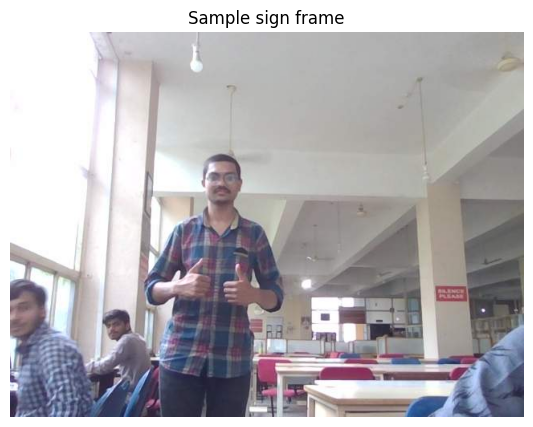

In [17]:
import json
import base64
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt

with open("/content/sign_frames.json", "r") as f:
    frames = json.load(f)

print("Total frames:", len(frames))

# Display the middle frame
frame_data = frames[len(frames) // 2]
frame_data = frame_data.split(",", 1)[1] if "," in frame_data else frame_data

image = Image.open(
    BytesIO(base64.b64decode(frame_data))
).convert("RGB")

plt.figure(figsize=(7, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Sample sign frame")
plt.show()

In [18]:
import os
import json
import base64
import cv2
import numpy as np
import mediapipe as mp

BASE = "/content/drive/MyDrive/T240_Sign_Language"

HAND_MODEL = f"{BASE}/models/hand_landmarker.task"
POSE_MODEL = f"{BASE}/models/pose_landmarker_lite.task"

JSON_PATH = "/content/sign_frames.json"

# Verify required files
for path in [HAND_MODEL, POSE_MODEL, JSON_PATH]:
    print(("FOUND  " if os.path.exists(path) else "MISSING"), path)

with open(JSON_PATH, "r") as f:
    frames_data = json.load(f)

print("\nFrames loaded:", len(frames_data))

# Decode the captured JPEG frames
frames_rgb = []

for item in frames_data:
    encoded = item.split(",", 1)[1] if "," in item else item
    image_bytes = base64.b64decode(encoded)
    image_array = np.frombuffer(image_bytes, dtype=np.uint8)

    bgr = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

    if bgr is None:
        print("Warning: a frame could not be decoded")
        continue

    frames_rgb.append(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))

print("Decoded frames:", len(frames_rgb))

if frames_rgb:
    print("Frame dimensions:", frames_rgb[0].shape)

FOUND   /content/drive/MyDrive/T240_Sign_Language/models/hand_landmarker.task
FOUND   /content/drive/MyDrive/T240_Sign_Language/models/pose_landmarker_lite.task
FOUND   /content/sign_frames.json

Frames loaded: 31
Decoded frames: 31
Frame dimensions: (480, 640, 3)


In [19]:
import os
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

BASE = "/content/drive/MyDrive/T240_Sign_Language"

HAND_MODEL = f"{BASE}/models/hand_landmarker.task"
POSE_MODEL = f"{BASE}/models/pose_landmarker_lite.task"

OUTPUT_PATH = "/content/sign_test_hand_body_225.npy"

# Create MediaPipe task detectors
hand_options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2
)

pose_options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=POSE_MODEL),
    running_mode=vision.RunningMode.VIDEO
)

hand_detector = vision.HandLandmarker.create_from_options(hand_options)
pose_detector = vision.PoseLandmarker.create_from_options(pose_options)

sequences = []
hands_detected = 0
body_detected = 0

try:
    for i, frame_rgb in enumerate(frames_rgb):
        timestamp_ms = i * 100  # strictly increasing timestamps

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=np.ascontiguousarray(frame_rgb)
        )

        hand_result = hand_detector.detect_for_video(
            mp_image, timestamp_ms
        )
        pose_result = pose_detector.detect_for_video(
            mp_image, timestamp_ms
        )

        # 2 hands × 21 landmarks × (x, y, z) = 126 features
        hand_features = np.zeros((2, 21, 3), dtype=np.float32)

        for hand_idx, landmarks in enumerate(hand_result.hand_landmarks[:2]):
            hand_features[hand_idx] = np.array(
                [[lm.x, lm.y, lm.z] for lm in landmarks],
                dtype=np.float32
            )

        if hand_result.hand_landmarks:
            hands_detected += 1

        # 33 body landmarks × (x, y, z) = 99 features
        body_features = np.zeros((33, 3), dtype=np.float32)

        if pose_result.pose_landmarks:
            body_features = np.array(
                [
                    [lm.x, lm.y, lm.z]
                    for lm in pose_result.pose_landmarks[0]
                ],
                dtype=np.float32
            )
            body_detected += 1

        # 126 hand + 99 body = 225 features per frame
        frame_features = np.concatenate([
            hand_features.reshape(-1),
            body_features.reshape(-1)
        ])

        sequences.append(frame_features)

finally:
    hand_detector.close()
    pose_detector.close()

X_test_raw = np.asarray(sequences, dtype=np.float32)
np.save(OUTPUT_PATH, X_test_raw)

print("\nLandmark extraction complete!")
print("Sequence shape:", X_test_raw.shape)
print("Expected shape: (31, 225)")
print("Frames with hands:", hands_detected, "/", len(frames_rgb))
print("Frames with body:", body_detected, "/", len(frames_rgb))
print("All values finite:", np.isfinite(X_test_raw).all())
print("Saved to:", OUTPUT_PATH)


Landmark extraction complete!
Sequence shape: (31, 225)
Expected shape: (31, 225)
Frames with hands: 29 / 31
Frames with body: 31 / 31
All values finite: True
Saved to: /content/sign_test_hand_body_225.npy


In [21]:
import numpy as np

SEQUENCE_PATH = "/content/sign_test_hand_body_225.npy"

sequence = np.load(SEQUENCE_PATH).astype(np.float32)
print("Raw sequence:", sequence.shape)

def fill_nearest_group(sequence, landmark_count):
    group = sequence.reshape(
        len(sequence), landmark_count, 3
    ).copy()

    valid = np.any(group != 0, axis=(1, 2))
    valid_idx = np.where(valid)[0]

    if len(valid_idx) == 0:
        return group.reshape(len(sequence), -1)

    for idx in np.where(~valid)[0]:
        nearest = valid_idx[
            np.argmin(np.abs(valid_idx - idx))
        ]
        group[idx] = group[nearest]

    return group.reshape(len(sequence), -1)


# Fill hands (126 features) and body (99 features) separately
hands = fill_nearest_group(sequence[:, :126], 42)
body = fill_nearest_group(sequence[:, 126:225], 33)

sequence = np.concatenate([hands, body], axis=1)

# Resample from 31 frames to 60
old_t = np.linspace(0, 1, len(sequence))
new_t = np.linspace(0, 1, 60)

resampled = np.zeros((60, 225), dtype=np.float32)

for j in range(225):
    resampled[:, j] = np.interp(
        new_t, old_t, sequence[:, j]
    )

# Apply the training normalization
sequence = resampled.reshape(1, 60, 225).copy()

hands = sequence[0, :, :126].reshape(60, 2, 21, 3)

for h in range(2):
    hand = hands[:, h]
    detected = np.any(hand != 0, axis=(1, 2))

    hand -= hand[:, 0:1, :].copy()

    scale = np.max(
        np.abs(hand), axis=(1, 2), keepdims=True
    )
    scale[scale < 1e-6] = 1.0

    hand /= scale
    hand[~detected] = 0

sequence[0, :, :126] = hands.reshape(60, 126)

body = sequence[0, :, 126:].reshape(60, 33, 3)
detected_body = np.any(body != 0, axis=(1, 2))

shoulder_center = (
    body[:, 11:12, :] + body[:, 12:13, :]
) / 2.0

body -= shoulder_center

scale = np.max(
    np.abs(body), axis=(1, 2), keepdims=True
)
scale[scale < 1e-6] = 1.0

body /= scale
body[~detected_body] = 0

sequence[0, :, 126:] = body.reshape(60, 99)

sequence = sequence.astype(np.float32)

print("Processed shape:", sequence.shape)
print("All values finite:", np.isfinite(sequence).all())
print("Saved model input is ready.")

Raw sequence: (31, 225)
Processed shape: (1, 60, 225)
All values finite: True
Saved model input is ready.


In [22]:
import os
import numpy as np
import torch

BASE = "/content/drive/MyDrive/T240_Sign_Language"
MODEL_PATH = f"{BASE}/models/best_sign_language_hand_body_bilstm.pth"
DATASET_PATH = f"{BASE}/reports/hand_body_225_nearestfill_dataset.npz"

print("Checkpoint exists:", os.path.exists(MODEL_PATH))
print("Dataset exists:", os.path.exists(DATASET_PATH))

# Inspect checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: state dictionary with {len(value)} entries")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: tensor shape {tuple(value.shape)}")
        elif isinstance(value, (int, float, str)):
            print(f"{key}: {value}")

# Read labels saved with the dataset
data = np.load(DATASET_PATH, allow_pickle=True)
classes = data["classes"].astype(str)

print("\nModel classes:")
for i, name in enumerate(classes):
    print(i, "->", name)

print("\nPrepared input shape:", sequence.shape)

Checkpoint exists: True
Dataset exists: True

Checkpoint type: OrderedDict
Checkpoint keys: ['lstm.weight_ih_l0', 'lstm.weight_hh_l0', 'lstm.bias_ih_l0', 'lstm.bias_hh_l0', 'lstm.weight_ih_l0_reverse', 'lstm.weight_hh_l0_reverse', 'lstm.bias_ih_l0_reverse', 'lstm.bias_hh_l0_reverse', 'fc.weight', 'fc.bias']
lstm.weight_ih_l0: tensor shape (256, 225)
lstm.weight_hh_l0: tensor shape (256, 64)
lstm.bias_ih_l0: tensor shape (256,)
lstm.bias_hh_l0: tensor shape (256,)
lstm.weight_ih_l0_reverse: tensor shape (256, 225)
lstm.weight_hh_l0_reverse: tensor shape (256, 64)
lstm.bias_ih_l0_reverse: tensor shape (256,)
lstm.bias_hh_l0_reverse: tensor shape (256,)
fc.weight: tensor shape (9, 128)
fc.bias: tensor shape (9,)

Model classes:
0 -> 48. Hello
1 -> 49. How are you
2 -> 50. Alright
3 -> 51. Good Morning
4 -> 52. Good afternoon
5 -> 53. Good evening
6 -> 54. Good night
7 -> 55. Thank you
8 -> 56. Pleased

Prepared input shape: (1, 60, 225)


In [23]:
import torch
import torch.nn as nn
import numpy as np

# Model architecture matching the saved checkpoint
class SignLanguageHandBodyBiLSTM(nn.Module):
    def __init__(self, input_size=225, hidden_size=64, num_classes=9):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True,
            bidirectional=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)

        # Final forward and backward hidden states
        final_hidden = torch.cat(
            (hidden[-2], hidden[-1]), dim=1
        )

        return self.fc(self.dropout(final_hidden))


# Load the trained model
device = torch.device("cpu")
model = SignLanguageHandBodyBiLSTM().to(device)
model.load_state_dict(checkpoint)
model.eval()

# Predict using the preprocessed 60-frame sequence
input_tensor = torch.from_numpy(sequence).float().to(device)

with torch.no_grad():
    logits = model(input_tensor)
    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

# Display the top 3 predictions
top_indices = np.argsort(probabilities)[::-1][:3]

print("=" * 45)
print("HAND + BODY SIGN RECOGNITION")
print("=" * 45)

for rank, idx in enumerate(top_indices, start=1):
    print(
        f"{rank}. {classes[idx]}: "
        f"{probabilities[idx] * 100:.2f}%"
    )

best_idx = int(top_indices[0])
best_confidence = float(probabilities[best_idx])

print("\nPredicted sign:", classes[best_idx])
print(f"Confidence: {best_confidence * 100:.2f}%")

HAND + BODY SIGN RECOGNITION
1. 56. Pleased: 66.89%
2. 54. Good night: 15.01%
3. 55. Thank you: 9.60%

Predicted sign: 56. Pleased
Confidence: 66.89%


In [36]:
import os

BASE = "/content/drive/MyDrive/T240_Sign_Language"

for root, dirs, files in os.walk(BASE):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

    for file in files:
        if file.endswith(".py") or file.endswith(".ipynb"):
            path = os.path.join(root, file)

            try:
                with open(path, "r", encoding="utf-8", errors="ignore") as f:
                    content = f.read()

                if (
                    "train_test_split" in content
                    or "hand_body_225_nearestfill_dataset" in content
                    or "random_state=42" in content
                ):
                    print("\nFILE:", path)
                    for line_no, line in enumerate(content.splitlines(), 1):
                        if any(term in line for term in [
                            "train_test_split",
                            "hand_body_225_nearestfill_dataset",
                            "random_state=42",
                            "sequence_path"
                        ]):
                            print(f"{line_no}: {line.strip()}")
            except Exception:
                pass

In [40]:
def preprocess_sequence(raw):
    raw = np.asarray(raw, dtype=np.float32).copy()

    # Fill missing hand and body frames independently.
    for start, end in [(0, 126), (126, 225)]:
        group = raw[:, start:end].copy()
        valid = np.isfinite(group).all(axis=1) & (
            np.abs(group).sum(axis=1) > 1e-8
        )

        if valid.any():
            valid_idx = np.where(valid)[0]
            for i in range(len(group)):
                if not valid[i]:
                    nearest = valid_idx[np.argmin(np.abs(valid_idx - i))]
                    group[i] = group[nearest]
        else:
            group[:] = 0

        raw[:, start:end] = group

    # Resample to 60 frames.
    idx = np.linspace(0, len(raw) - 1, 60).round().astype(int)
    seq = raw[idx].copy()

    # Normalize each hand relative to its wrist.
    hand1 = seq[:, :63].reshape(60, 21, 3).copy()
    hand1 -= hand1[:, 0:1, :]
    seq[:, :63] = hand1.reshape(60, 63)

    hand2 = seq[:, 63:126].reshape(60, 21, 3).copy()
    hand2 -= hand2[:, 0:1, :]
    seq[:, 63:126] = hand2.reshape(60, 63)

    # Normalize body relative to the shoulder center.
    body = seq[:, 126:225].reshape(60, 33, 3).copy()
    shoulder_center = (body[:, 11, :] + body[:, 12, :]) / 2
    body -= shoulder_center[:, None, :]

    # Scale each group per frame.
    for frame in range(60):
        for start, end in [(0, 63), (63, 126)]:
            part = seq[frame, start:end]
            scale = np.max(np.abs(part))
            if scale > 1e-8:
                seq[frame, start:end] = part / scale

        scale = np.max(np.abs(body[frame]))
        if scale > 1e-8:
            body[frame] /= scale

    seq[:, 126:225] = body.reshape(60, 99)

    return seq

In [41]:
print("AlRight recordings:", len(alright))
print("Models loaded:", list(models.keys()))
print("Preprocessing function:", preprocess_sequence)

test_path = alright.iloc[0]["sequence_path"]
test_raw = np.load(test_path)
test_seq = preprocess_sequence(test_raw)

print("Test file:", test_path)
print("Input shape:", test_seq.shape)
print("All values finite:", np.isfinite(test_seq).all())

AlRight recordings: 21
Models loaded: ['V1', 'V2']
Preprocessing function: <function preprocess_sequence at 0x79a3a5549260>
Test file: /content/drive/MyDrive/T240_Sign_Language/data/landmarks_hand_body_video_mode/Greetings_1of2_Greetings_50._Alright_MVI_0037.npy
Input shape: (60, 225)
All values finite: True


In [69]:

import numpy as np
import mediapipe as mp
import torch
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

BASE = "/content/drive/MyDrive/T240_Sign_Language"
HAND_MODEL = f"{BASE}/models/hand_landmarker.task"
POSE_MODEL = f"{BASE}/models/pose_landmarker_lite.task"

# Extract captured frames using the SAME hand-slot assignment as training.
hand_options = vision.HandLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=vision.RunningMode.VIDEO,
    num_hands=2,
)

pose_options = vision.PoseLandmarkerOptions(
    base_options=python.BaseOptions(model_asset_path=POSE_MODEL),
    running_mode=vision.RunningMode.VIDEO,
)

sequences = []

hand_detector = vision.HandLandmarker.create_from_options(hand_options)
pose_detector = vision.PoseLandmarker.create_from_options(pose_options)

try:
    for i, frame_rgb in enumerate(frames_rgb):
        image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=np.ascontiguousarray(frame_rgb),
        )

        timestamp_ms = i * 100
        hr = hand_detector.detect_for_video(image, timestamp_ms)
        pr = pose_detector.detect_for_video(image, timestamp_ms)

        hands = np.zeros((2, 21, 3), dtype=np.float32)
        body = np.zeros((33, 3), dtype=np.float32)

        # Match Cell 203: Left -> slot 0, Right -> slot 1.
        for landmarks, handedness in zip(
            hr.hand_landmarks, hr.handedness
        ):
            label = (
                handedness[0].category_name.lower()
                if handedness else ""
            )
            hand_idx = 0 if label == "left" else 1

            hands[hand_idx] = np.asarray(
                [[p.x, p.y, p.z] for p in landmarks],
                dtype=np.float32,
            )

        if pr.pose_landmarks:
            body = np.asarray(
                [[p.x, p.y, p.z] for p in pr.pose_landmarks[0]],
                dtype=np.float32,
            )

        sequences.append(
            np.concatenate([hands.reshape(-1), body.reshape(-1)])
        )
finally:
    hand_detector.close()
    pose_detector.close()

X_test_raw_ordered = np.asarray(sequences, dtype=np.float32)

print("Extracted sequence:", X_test_raw_ordered.shape)
print("Hand slots now follow training's handedness convention.")

# Use the same preprocessing function already defined in your notebook.
live_X_ordered = preprocess_hand_body_live(X_test_raw_ordered)
print("Preprocessed input:", live_X_ordered.shape)

# Test both existing models without changing their weights.
device = torch.device("cpu")
x = torch.as_tensor(live_X_ordered, dtype=torch.float32, device=device)

for name, model in models.items():
    model.eval()
    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    top = np.argsort(probs)[::-1][:3]
    print(f"\n{name} predictions:")
    for idx in top:
        print(f"{classes[idx]}: {probs[idx] * 100:.2f}%")
    print("Predicted sign:", classes[top[0]])


Extracted sequence: (31, 225)
Hand slots now follow training's handedness convention.
Preprocessed input: (1, 60, 225)

V1 predictions:
50. Alright: 89.18%
55. Thank you: 10.25%
56. Pleased: 0.19%
Predicted sign: 50. Alright

V2 predictions:
50. Alright: 93.99%
55. Thank you: 4.78%
49. How are you: 0.42%
Predicted sign: 50. Alright


In [74]:
import inspect

print("Function exists:", "preprocess_hand_body_live" in globals())

if "preprocess_hand_body_live" in globals():
    print(inspect.getsource(preprocess_hand_body_live))
else:
    print("Function not found in current runtime.")

Function exists: True
def preprocess_hand_body_live(raw, target_len=60):
    """Match the preprocessing in T240.ipynb Cell 204."""
    raw = np.asarray(raw, dtype=np.float32).copy()

    if raw.ndim != 2 or raw.shape[1] != 225 or len(raw) == 0:
        raise ValueError(f"Expected (frames, 225), got {raw.shape}")

    if not np.isfinite(raw).all():
        raise ValueError("Raw landmarks contain NaN or infinite values.")

    # 1. Fill missing hand and body frames independently.
    for start, end, landmark_count in [
        (0, 126, 42),       # Two hands: 2 x 21 landmarks
        (126, 225, 33),     # Body: 33 landmarks
    ]:
        group = raw[:, start:end].reshape(
            len(raw), landmark_count, 3
        ).copy()

        valid = np.any(group != 0, axis=(1, 2))
        valid_idx = np.where(valid)[0]

        if len(valid_idx):
            for idx in np.where(~valid)[0]:
                nearest = valid_idx[
                    np.argmin(np.abs(valid_idx - idx))
           